In [ ]:
# Comfort limits
UPPER_LIMIT = 27
LOWER_LIMIT = 22
TARGET_TEMP = 25

# Objective weights used ONLY as the starting point
W1_VIOLATION_DEGREES = 1 / 0.38   # Obj 1: HVAC hours + w1 * sum(violation degrees)
W2_VIOLATION_COUNT   = 5.0        # Obj 2: HVAC hours + w2 * count(violating hours)
W3_ABS_DEVIATION      = 0.5       # Obj 3: HVAC hours + w3 * sum(|T_in - target|)

OBJ3_TIME_LIMIT_SECONDS = 500

# PMV standard office defaults.
PMV_AIR_VELOCITY = 0.1   # m/s
PMV_RH           = 50.0  # % relative humidity
PMV_MET          = 1.2  # met, seated office work
PMV_CLO          = 0.5   # clo, summer clothing (this notebook is cooling-only)

# Daily test sessions
DAILY_DATES = [
    
    '2025-05-05','2025-05-06','2025-05-07','2025-05-08', '2025-05-09',
     
    '2025-05-19', '2025-05-20','2025-05-21','2025-05-22','2025-05-23',
    '2025-06-02', '2025-06-03','2025-06-04','2025-06-05','2025-06-06',
    
    '2025-08-25', '2025-08-26','2025-08-27', '2025-08-28', '2025-08-29',
    
    '2025-09-01', '2025-09-02', '2025-09-03', '2025-09-04', '2025-09-05',
    '2025-09-08', '2025-09-09', '2025-09-10', '2025-09-11', '2025-09-12',
    '2025-09-15', '2025-09-16', '2025-09-17', '2025-09-18', '2025-09-19',
    '2025-09-22', '2025-09-23', '2025-09-24', '2025-09-25', '2025-09-26',
]

DAILY_SESSIONS = [
    {'label': f'Day_{d}', 'history_end': f'{d} 00:00:00', 'test_start': f'{d} 00:00:00', 'n_hours': 24}
    for d in DAILY_DATES
]

# File path
DATA_PATH = "../data/office35_fullop_dataframe.xlsx"


## Data Prep

In [52]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
import pulp

data = pd.read_excel(DATA_PATH)
data['timestamp'] = pd.to_datetime(data['timestamp'])
data.set_index('timestamp', inplace=True)

print(f"Loaded: {data.index.min()} -> {data.index.max()}  ({len(data):,} rows)")


Loaded: 2024-11-27 11:00:00 -> 2025-11-15 09:00:00  (8,471 rows)


In [53]:
plt.rcParams.update({
    'font.size': 12,        # axis tick labels, legend, etc.
    'axes.labelsize': 14,   # xlabel/ylabel text
    'axes.titlesize': 14,   # plot title
    'lines.markersize': 10, # dot size on every plot
})

In [ ]:
data['sequence']     = data['sequence'].fillna(0)
data['heating_mode'] = data['heating_mode'].fillna(0)
data['cooling_mode'] = data['cooling_mode'].fillna(0)
data['consumption']  = data['consumption'].fillna(0)

data['heating_mode_lag1'] = data['heating_mode'].shift(1)
data['cooling_mode_lag1'] = data['cooling_mode'].shift(1)
data['heating_mode_lag2'] = data['heating_mode'].shift(2)
data['cooling_mode_lag2'] = data['cooling_mode'].shift(2)

data['t_in_lag1']  = data['t_in'].shift(1)
data['t_in_lag2']  = data['t_in'].shift(2)
data['t_in_lag3']  = data['t_in'].shift(3)
data['t_out_lag1'] = data['t_out'].shift(1)

data['is_working_hours'] = (
    (data.index.weekday < 5) &
    (data.index.hour >= 9)   &
    (data.index.hour <= 17)
)

data['sin_hour'] = np.sin(2 * np.pi * data.index.hour / 24)
data['cos_hour'] = np.cos(2 * np.pi * data.index.hour / 24)

FEATURE_COLS = [
    't_in_lag1', 't_in_lag2', 't_in_lag3',
    't_out', 't_out_lag1',
    'heating_mode', 'cooling_mode',
    'heating_mode_lag1', 'cooling_mode_lag1',
    'sin_hour', 'cos_hour'
]
TARGET_COL = 't_in'

data_clean = data.dropna(subset=FEATURE_COLS + [TARGET_COL])
print(f"Clean rows: {len(data_clean):,}")

# Average real consumption during hours the AC was actually cooling
avg_consumption_per_hour = data.loc[data['cooling_mode'] == 1, 'consumption'].mean()
print(f"avg_consumption_per_hour (cooling_mode==1) = {avg_consumption_per_hour:.2f} Wh")


Clean rows: 8,468
avg_consumption_per_hour (cooling_mode==1) = 932.51 Wh


## LR Model

In [55]:
train_data = data_clean[:'2025-08-31 23:59:59']

lr_model = LinearRegression()
lr_model.fit(train_data[FEATURE_COLS], train_data[TARGET_COL])

coeffs    = dict(zip(FEATURE_COLS, lr_model.coef_))
intercept = lr_model.intercept_

print(f"Training set: {train_data.index.min().date()} -> {train_data.index.max().date()}  ({len(train_data):,} rows)")
print("\nCoefficients:")
for f, c in coeffs.items():
    print(f"  {f:30s}  {c:.2f}")
print(f"  {'intercept':30s}  {intercept:.2f}")


Training set: 2024-11-27 -> 2025-08-31  (6,658 rows)

Coefficients:
  t_in_lag1                       1.22
  t_in_lag2                       -0.19
  t_in_lag3                       -0.07
  t_out                           0.05
  t_out_lag1                      -0.02
  heating_mode                    0.50
  cooling_mode                    -1.08
  heating_mode_lag1               -0.26
  cooling_mode_lag1               0.88
  sin_hour                        0.06
  cos_hour                        -0.05
  intercept                       0.31


## Shared Helpers (recursive simulation, actual-schedule reconstruction, per-day metrics)

In [ ]:
from pythermalcomfort.models import pmv_ppd_iso


def simulate_temperature(schedule, test_data, initial_history):
    """Recursive LR forecast under a FIXED, already-known 0/1/2 schedule (0=off,
    1=heating, 2=cooling) -- used below to compute the 'simulated actual' t_in."""
    t_in_sim = []
    history  = list(initial_history)
    for t in range(len(test_data)):
        h_on   = 1 if schedule[t] == 1 else 0
        c_on   = 1 if schedule[t] == 2 else 0
        h_lag1 = 1 if (t > 0 and schedule[t-1] == 1) else 0
        c_lag1 = 1 if (t > 0 and schedule[t-1] == 2) else 0
        row    = test_data.iloc[t]
        pred = (
            coeffs['t_in_lag1']         * history[-1]       +
            coeffs['t_in_lag2']         * history[-2]       +
            coeffs['t_in_lag3']         * history[-3]       +
            coeffs['t_out']             * row['t_out']      +
            coeffs['t_out_lag1']        * row['t_out_lag1'] +
            coeffs['heating_mode']      * h_on              +
            coeffs['cooling_mode']      * c_on              +
            coeffs['heating_mode_lag1'] * h_lag1            +
            coeffs['cooling_mode_lag1'] * c_lag1            +
            coeffs['sin_hour']          * row['sin_hour']  +
            coeffs['cos_hour']          * row['cos_hour']  +
            intercept
        )
        t_in_sim.append(pred)
        history.append(pred)
    return t_in_sim


def build_actual_schedule(test_data):
    """Packs the real recorded heating_mode/cooling_mode columns into the same 0/1/2
    schedule encoding """
    h = test_data['heating_mode'].values
    c = test_data['cooling_mode'].values
    return np.where(h == 1, 1, np.where(c == 1, 2, 0))


def compute_day_metrics(schedule, t_pred, work_mask):
    """
    Standard metric set for one (weight, day) MILP solve. 
    """
    schedule = pd.Series(schedule)
    t_pred   = pd.Series(t_pred)

    hvac_h = int((schedule > 0).sum())
    avg_t  = float(t_pred[work_mask].mean())
    max_t  = float(t_pred[work_mask].max())

    distance = pd.Series(0.0, index=t_pred.index)
    below = t_pred < LOWER_LIMIT
    above = t_pred > UPPER_LIMIT
    distance[below] = LOWER_LIMIT - t_pred[below]
    distance[above] = t_pred[above] - UPPER_LIMIT

    work_distance = distance[work_mask]
    violated_mask = work_distance > 0
    n_violations  = int(violated_mask.sum())

    avg_disc_all  = float(work_distance.mean())
    avg_disc_viol = float(work_distance[violated_mask].mean()) if n_violations > 0 else np.nan

    work_t_in = t_pred[work_mask].values
    pmv_vals  = pmv_ppd_iso(tdb=work_t_in, tr=work_t_in, vr=PMV_AIR_VELOCITY, rh=PMV_RH,
                             met=PMV_MET, clo=PMV_CLO, limit_inputs=False).pmv
    avg_pmv   = float(np.mean(pmv_vals))

    return {
        'HVAC Hours': hvac_h,
        'Avg T_in (work)': avg_t,
        'Max T_in (work)': max_t,
        'Number of Violations': n_violations,
        'Avg Discomfort (violated hrs)': avg_disc_viol,
        'Avg Discomfort (all work hrs)': avg_disc_all,
        'Avg PMV (work)': avg_pmv,
        'violation_degrees_sum': float(work_distance.sum()),
    }


def aggregate_weight_row(weight, day_metrics):
    """Averages a list of per-day compute_day_metrics() dicts into one weight-table row."""
    return {
        'weight': weight,
        'HVAC Hours': np.sum([d['HVAC Hours'] for d in day_metrics]),
        'Avg HVAC Hours': np.mean([d['HVAC Hours'] for d in day_metrics]),
        'Avg T_in (work)': np.mean([d['Avg T_in (work)'] for d in day_metrics]),
        'Max T_in (work)': np.mean([d['Max T_in (work)'] for d in day_metrics]),
        'Number of Violations': np.sum([d['Number of Violations'] for d in day_metrics]),
        'Avg Number of Violations': np.mean([d['Number of Violations'] for d in day_metrics]),
        'Avg Discomfort (all work hrs)': np.mean([d['Avg Discomfort (all work hrs)'] for d in day_metrics]),
        'Avg PMV (work)': np.mean([d['Avg PMV (work)'] for d in day_metrics]),
    }

print("Shared helpers defined.")


Shared helpers defined.


## MILP Objective Variants

In [ ]:
# Prefer Gurobi over CBC
GUROBI_IS_AVAILABLE = 'GUROBI' in pulp.listSolvers(onlyAvailable=True)

def get_milp_solver(time_limit=None):
    if GUROBI_IS_AVAILABLE:
        return pulp.GUROBI(msg=0, timeLimit=time_limit)
    return pulp.PULP_CBC_CMD(msg=0, timeLimit=time_limit)

print(f"MILP solver: {'Gurobi' if GUROBI_IS_AVAILABLE else 'CBC (Gurobi not available on this machine)'}")


MILP solver: Gurobi


In [59]:
def run_milp_obj1(test_data, initial_history):
    """Objective 1: HVAC ON hours + w1 * sum(violation degrees above 27 / below 22), working hours only."""
    T    = range(len(test_data))
    prob = pulp.LpProblem("HVAC_MILP_Obj1", pulp.LpMinimize)

    h_on  = pulp.LpVariable.dicts("Heat",  T, cat=pulp.LpBinary)
    c_on  = pulp.LpVariable.dicts("Cool",  T, cat=pulp.LpBinary)
    t_in  = pulp.LpVariable.dicts("Temp",  T, lowBound=10, upBound=40)
    over  = pulp.LpVariable.dicts("Over",  T, lowBound=0)
    under = pulp.LpVariable.dicts("Under", T, lowBound=0)

    for t in T:
        row  = test_data.iloc[t]
        lag1 = t_in[t-1] if t >= 1 else initial_history[t-1]
        lag2 = t_in[t-2] if t >= 2 else initial_history[t-2]
        lag3 = t_in[t-3] if t >= 3 else initial_history[t-3]
        h_l1 = h_on[t-1] if t >= 1 else 0
        c_l1 = c_on[t-1] if t >= 1 else 0

        prob += t_in[t] == (
            coeffs['t_in_lag1']         * lag1              +
            coeffs['t_in_lag2']         * lag2              +
            coeffs['t_in_lag3']         * lag3              +
            coeffs['t_out']             * row['t_out']      +
            coeffs['t_out_lag1']        * row['t_out_lag1'] +
            coeffs['heating_mode']      * h_on[t]           +
            coeffs['cooling_mode']      * c_on[t]           +
            coeffs['heating_mode_lag1'] * h_l1              +
            coeffs['cooling_mode_lag1'] * c_l1              +
            coeffs['sin_hour']          * row['sin_hour']  +
            coeffs['cos_hour']          * row['cos_hour']  +
            intercept
        )

        current_hour = test_data.index[t].hour
        hvac_allowed = row['is_working_hours'] or (current_hour in [6, 7, 8])
        if not hvac_allowed:
            prob += h_on[t] == 0
            prob += c_on[t] == 0
        prob += h_on[t] + c_on[t] <= 1

        if row['is_working_hours']:
            prob += t_in[t] - over[t]  <= UPPER_LIMIT
            prob += t_in[t] + under[t] >= LOWER_LIMIT

    prob += (
        pulp.lpSum([h_on[t] + c_on[t] for t in T]) +
        pulp.lpSum([(over[t] + under[t]) * W1_VIOLATION_DEGREES for t in T])
    )

    prob.solve(get_milp_solver())

    schedule   = [int(round(pulp.value(c_on[t]))) * 2 for t in T]
    t_in_preds = [pulp.value(t_in[t]) for t in T]
    return {'hvac_schedule': schedule, 't_in_pred': t_in_preds, 'objective_value': pulp.value(prob.objective)}

print("Objective 1 (violation degrees) defined.")


Objective 1 (violation degrees) defined.


In [60]:
def run_milp_obj2(test_data, initial_history):
    """Objective 2: HVAC ON hours + w2 * count(hours violating the 22-27 band), working hours only."""
    T    = range(len(test_data))
    prob = pulp.LpProblem("HVAC_MILP_Obj2", pulp.LpMinimize)

    h_on    = pulp.LpVariable.dicts("Heat",   T, cat=pulp.LpBinary)
    c_on    = pulp.LpVariable.dicts("Cool",   T, cat=pulp.LpBinary)
    t_in    = pulp.LpVariable.dicts("Temp",   T, lowBound=10, upBound=40)
    z_over  = pulp.LpVariable.dicts("ZOver",  T, cat=pulp.LpBinary)
    z_under = pulp.LpVariable.dicts("ZUnder", T, cat=pulp.LpBinary)

    M_OVER  = 40 - UPPER_LIMIT
    M_UNDER = LOWER_LIMIT - 10

    for t in T:
        row  = test_data.iloc[t]
        lag1 = t_in[t-1] if t >= 1 else initial_history[t-1]
        lag2 = t_in[t-2] if t >= 2 else initial_history[t-2]
        lag3 = t_in[t-3] if t >= 3 else initial_history[t-3]
        h_l1 = h_on[t-1] if t >= 1 else 0
        c_l1 = c_on[t-1] if t >= 1 else 0

        prob += t_in[t] == (
            coeffs['t_in_lag1']         * lag1              +
            coeffs['t_in_lag2']         * lag2              +
            coeffs['t_in_lag3']         * lag3              +
            coeffs['t_out']             * row['t_out']      +
            coeffs['t_out_lag1']        * row['t_out_lag1'] +
            coeffs['heating_mode']      * h_on[t]           +
            coeffs['cooling_mode']      * c_on[t]           +
            coeffs['heating_mode_lag1'] * h_l1              +
            coeffs['cooling_mode_lag1'] * c_l1              +
            coeffs['sin_hour']          * row['sin_hour']  +
            coeffs['cos_hour']          * row['cos_hour']  +
            intercept
        )

        current_hour = test_data.index[t].hour
        hvac_allowed = row['is_working_hours'] or (current_hour in [6, 7, 8])
        if not hvac_allowed:
            prob += h_on[t] == 0
            prob += c_on[t] == 0
        prob += h_on[t] + c_on[t] <= 1

        if row['is_working_hours']:
            prob += t_in[t] - UPPER_LIMIT <= M_OVER  * z_over[t]
            prob += LOWER_LIMIT - t_in[t] <= M_UNDER * z_under[t]

    prob += (
        pulp.lpSum([h_on[t] + c_on[t] for t in T]) +
        pulp.lpSum([(z_over[t] + z_under[t]) * W2_VIOLATION_COUNT for t in T])
    )

    prob.solve(get_milp_solver())

    schedule   = [int(round(pulp.value(c_on[t]))) * 2 for t in T]
    t_in_preds = [pulp.value(t_in[t]) for t in T]
    return {'hvac_schedule': schedule, 't_in_pred': t_in_preds, 'objective_value': pulp.value(prob.objective)}

print("Objective 2 (violation count) defined.")


Objective 2 (violation count) defined.


In [ ]:
def run_milp_obj3(test_data, initial_history):
    """
    Objective 3: HVAC ON hours + w3 * sum(|T_in - target|), working hours only.
    """
    T    = range(len(test_data))
    prob = pulp.LpProblem("HVAC_MILP_Obj3", pulp.LpMinimize)

    h_on = pulp.LpVariable.dicts("Heat", T, cat=pulp.LpBinary)
    c_on = pulp.LpVariable.dicts("Cool", T, cat=pulp.LpBinary)
    t_in = pulp.LpVariable.dicts("Temp", T, lowBound=10, upBound=40)
    dev  = pulp.LpVariable.dicts("Dev",  T, lowBound=0)

    for t in T:
        row  = test_data.iloc[t]
        lag1 = t_in[t-1] if t >= 1 else initial_history[t-1]
        lag2 = t_in[t-2] if t >= 2 else initial_history[t-2]
        lag3 = t_in[t-3] if t >= 3 else initial_history[t-3]
        h_l1 = h_on[t-1] if t >= 1 else 0
        c_l1 = c_on[t-1] if t >= 1 else 0

        prob += t_in[t] == (
            coeffs['t_in_lag1']         * lag1              +
            coeffs['t_in_lag2']         * lag2              +
            coeffs['t_in_lag3']         * lag3              +
            coeffs['t_out']             * row['t_out']      +
            coeffs['t_out_lag1']        * row['t_out_lag1'] +
            coeffs['heating_mode']      * h_on[t]           +
            coeffs['cooling_mode']      * c_on[t]           +
            coeffs['heating_mode_lag1'] * h_l1              +
            coeffs['cooling_mode_lag1'] * c_l1              +
            coeffs['sin_hour']          * row['sin_hour']  +
            coeffs['cos_hour']          * row['cos_hour']  +
            intercept
        )

        current_hour = test_data.index[t].hour
        hvac_allowed = row['is_working_hours'] or (current_hour in [6, 7, 8])
        if not hvac_allowed:
            prob += h_on[t] == 0
            prob += c_on[t] == 0
        prob += h_on[t] + c_on[t] <= 1

        if row['is_working_hours']:
            prob += dev[t] >= t_in[t] - TARGET_TEMP
            prob += dev[t] >= TARGET_TEMP - t_in[t]

    prob += (
        pulp.lpSum([h_on[t] + c_on[t] for t in T]) +
        pulp.lpSum([dev[t] * W3_ABS_DEVIATION for t in T])
    )

    prob.solve(get_milp_solver(time_limit=OBJ3_TIME_LIMIT_SECONDS))
    proven_optimal = (prob.sol_status == pulp.LpSolutionOptimal)

    schedule   = [int(round(pulp.value(c_on[t]))) * 2 for t in T]
    t_in_preds = [pulp.value(t_in[t]) for t in T]
    return {
        'hvac_schedule': schedule,
        't_in_pred': t_in_preds,
        'objective_value': pulp.value(prob.objective),
        'proven_optimal': proven_optimal,
    }

print("Objective 3 (absolute deviation) defined.")


Objective 3 (absolute deviation) defined.


## Parametric Weight Sweep - Pareto Fronts + Per-Weight Metrics Tables

### Objective 1 sweep - Violation Degrees vs HVAC hours

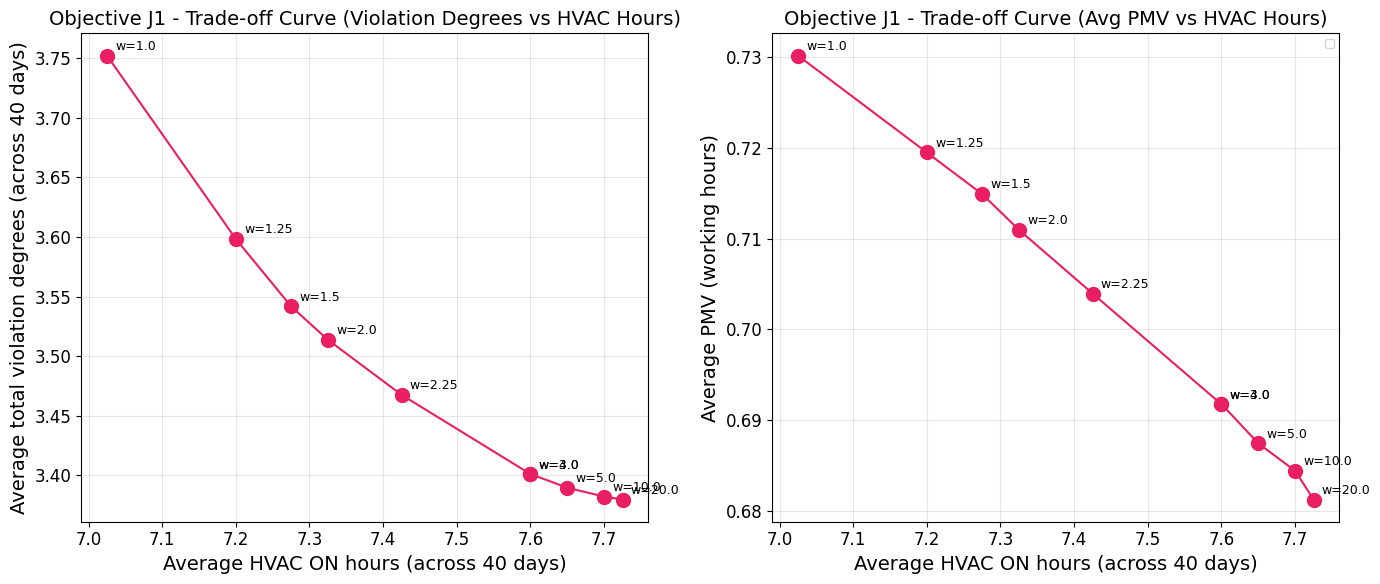

=== Objective J1: metrics by weight (averaged over 40 daily sessions) ===


,weight,HVAC Hours,Avg HVAC Hours,Avg T_in (work),Max T_in (work),Number of Violations,Avg Number of Violations,Avg Discomfort (all work hrs),Avg PMV (work)
0,1.00,281,7.02,27.14,27.56,214,5.35,0.417,0.730
1,1.25,288,7.20,27.11,27.50,204,5.10,0.400,0.720
2,1.50,291,7.28,27.09,27.48,201,5.03,0.394,0.715
3,2.00,293,7.32,27.08,27.46,196,4.90,0.390,0.711
4,2.25,297,7.42,27.06,27.43,185,4.62,0.385,0.704
5,3.00,304,7.60,27.02,27.39,163,4.08,0.378,0.692
6,4.00,304,7.60,27.02,27.39,163,4.08,0.378,0.692
7,5.00,306,7.65,27.00,27.38,159,3.98,0.377,0.687
8,10.00,308,7.70,26.99,27.36,156,3.90,0.376,0.684
9,20.00,309,7.72,26.98,27.35,152,3.80,0.376,0.681


In [62]:
weight_grid_obj1 = [1, 1.25, 1.5, 2, 2.25, 3, 4, 5, 10, 20]


original_w1 = W1_VIOLATION_DEGREES
pareto_rows_obj1 = []
weight_rows_obj1 = []

for w in weight_grid_obj1:
    W1_VIOLATION_DEGREES = w
    day_metrics = []

    for session in DAILY_SESSIONS:
        history_data = data_clean[:session['history_end']]
        test_data    = data_clean[session['test_start']:].iloc[:session['n_hours']].copy()
        initial_history = list(history_data['t_in'].tail(24).values)

        result = run_milp_obj1(test_data, initial_history)
        t_pred = pd.Series(result['t_in_pred'], index=test_data.index)
        work   = test_data['is_working_hours']

        day_metrics.append(compute_day_metrics(result['hvac_schedule'], t_pred, work))

    weight_rows_obj1.append(aggregate_weight_row(w, day_metrics))
    pareto_rows_obj1.append({
        'weight': w,
        'avg_hvac_hours': np.mean([d['HVAC Hours'] for d in day_metrics]),
        'avg_violation_degrees': np.mean([d['violation_degrees_sum'] for d in day_metrics]),
        'avg_pmv': np.mean([d['Avg PMV (work)'] for d in day_metrics]),
    })

W1_VIOLATION_DEGREES = original_w1

sweep_df_obj1     = pd.DataFrame(pareto_rows_obj1)
#obj1_weight_table = pd.DataFrame(weight_rows_obj1).round(3)
obj1_weight_table = pd.DataFrame(weight_rows_obj1).round({
    'Avg HVAC Hours': 2,
    'Avg T_in (work)': 2,
    'Max T_in (work)': 2,
    'Avg PMV (work)': 3,
    'Avg Number of Violations': 2,
    'Avg Discomfort (all work hrs)': 3,
})

n_days = len(DAILY_SESSIONS)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

ax1.plot(sweep_df_obj1['avg_hvac_hours'], sweep_df_obj1['avg_violation_degrees'], 'o-', color='#E91E63')
for _, row in sweep_df_obj1.iterrows():
    ax1.annotate(f"w={row['weight']}", (row['avg_hvac_hours'], row['avg_violation_degrees']),
                 textcoords="offset points", xytext=(6, 4), fontsize=9)
ax1.set_xlabel(f'Average HVAC ON hours (across {n_days} days)')
ax1.set_ylabel(f'Average total violation degrees (across {n_days} days)')
ax1.set_title('Objective J1 - Trade-off Curve (Violation Degrees vs HVAC Hours)')
ax1.grid(alpha=0.3)

ax2.plot(sweep_df_obj1['avg_hvac_hours'], sweep_df_obj1['avg_pmv'], 'o-', color='#E91E63')
for _, row in sweep_df_obj1.iterrows():
    ax2.annotate(f"w={row['weight']}", (row['avg_hvac_hours'], row['avg_pmv']),
                 textcoords="offset points", xytext=(6, 4), fontsize=9)
ax2.set_xlabel(f'Average HVAC ON hours (across {n_days} days)')
ax2.set_ylabel('Average PMV (working hours)')
ax2.set_title('Objective J1 - Trade-off Curve (Avg PMV vs HVAC Hours)')
ax2.legend(fontsize=8, loc='best')
ax2.grid(alpha=0.3)

fig.tight_layout()
plt.show()

print(f"=== Objective J1: metrics by weight (averaged over {n_days} daily sessions) ===")
obj1_weight_table


### Objective 2 sweep - Violation Count vs HVAC hours

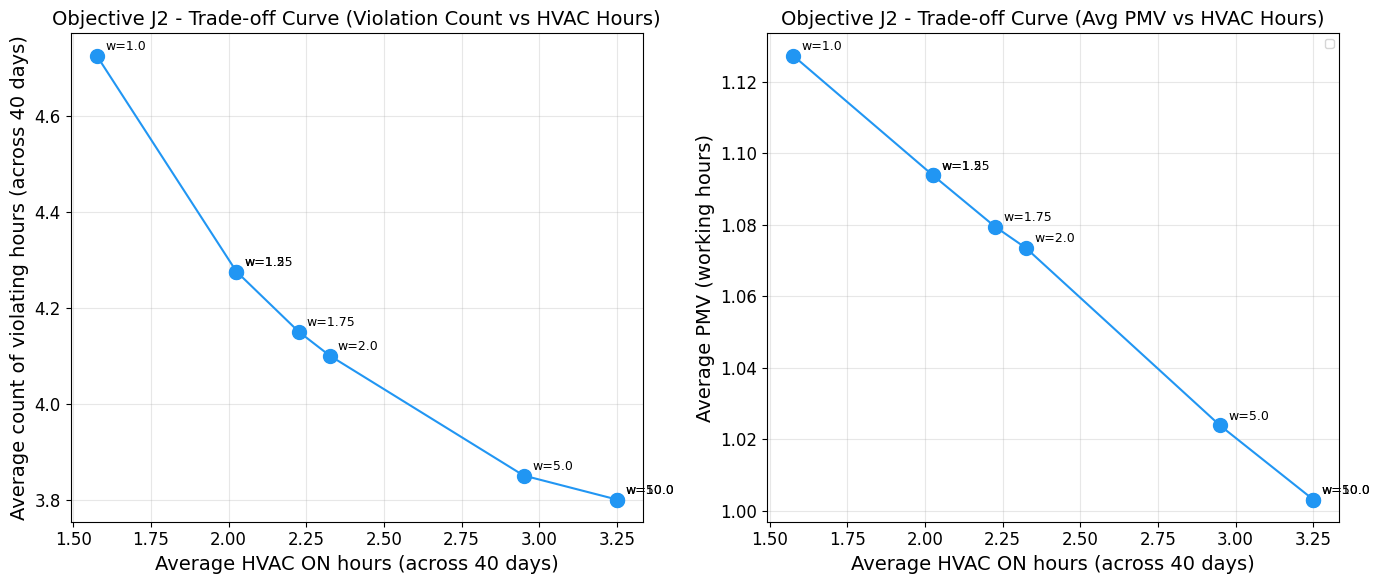

=== Objective J2: metrics by weight (averaged over 40 daily sessions) ===


,weight,HVAC Hours,Avg HVAC Hours,Avg T_in (work),Max T_in (work),Number of Violations,Avg Number of Violations,Avg Discomfort (all work hrs),Avg PMV (work)
0,1.00,63,1.58,28.43,28.98,189,4.72,1.78,1.127
1,1.25,81,2.02,28.32,28.84,171,4.28,1.70,1.094
2,1.50,81,2.02,28.32,28.84,171,4.28,1.70,1.094
3,1.75,89,2.22,28.27,28.82,166,4.15,1.65,1.079
4,2.00,93,2.33,28.25,28.78,164,4.10,1.63,1.073
5,5.00,118,2.95,28.09,28.68,154,3.85,1.48,1.024
6,10.00,130,3.25,28.02,28.61,152,3.80,1.41,1.003
7,50.00,130,3.25,28.02,28.61,152,3.80,1.41,1.003


In [63]:
weight_grid_obj2 = [1, 1.25, 1.5, 1.75, 2, 5, 10, 50]

original_w2 = W2_VIOLATION_COUNT
pareto_rows_obj2 = []
weight_rows_obj2 = []

for w in weight_grid_obj2:
    W2_VIOLATION_COUNT = w
    day_metrics = []

    for session in DAILY_SESSIONS:
        history_data = data_clean[:session['history_end']]
        test_data    = data_clean[session['test_start']:].iloc[:session['n_hours']].copy()
        initial_history = list(history_data['t_in'].tail(24).values)

        result = run_milp_obj2(test_data, initial_history)
        t_pred = pd.Series(result['t_in_pred'], index=test_data.index)
        work   = test_data['is_working_hours']

        day_metrics.append(compute_day_metrics(result['hvac_schedule'], t_pred, work))

    weight_rows_obj2.append(aggregate_weight_row(w, day_metrics))
    pareto_rows_obj2.append({
        'weight': w,
        'avg_hvac_hours': np.mean([d['HVAC Hours'] for d in day_metrics]),
        'avg_violation_count': np.mean([d['Number of Violations'] for d in day_metrics]),
        'avg_pmv': np.mean([d['Avg PMV (work)'] for d in day_metrics]),
    })

W2_VIOLATION_COUNT = original_w2

sweep_df_obj2     = pd.DataFrame(pareto_rows_obj2)
obj2_weight_table = pd.DataFrame(weight_rows_obj2).round({
    'Avg HVAC Hours': 2,
    'Avg T_in (work)': 2,
    'Max T_in (work)': 2,
    'Avg PMV (work)': 3,
    'Avg Number of Violations': 2,
    'Avg Discomfort (all work hrs)': 2,
})

n_days = len(DAILY_SESSIONS)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

ax1.plot(sweep_df_obj2['avg_hvac_hours'], sweep_df_obj2['avg_violation_count'], 'o-', color='#2196F3')
for _, row in sweep_df_obj2.iterrows():
    ax1.annotate(f"w={row['weight']}", (row['avg_hvac_hours'], row['avg_violation_count']),
                 textcoords="offset points", xytext=(6, 4), fontsize=9)
ax1.set_xlabel(f'Average HVAC ON hours (across {n_days} days)')
ax1.set_ylabel(f'Average count of violating hours (across {n_days} days)')
ax1.set_title('Objective J2 - Trade-off Curve (Violation Count vs HVAC Hours)')
ax1.grid(alpha=0.3)

ax2.plot(sweep_df_obj2['avg_hvac_hours'], sweep_df_obj2['avg_pmv'], 'o-', color='#2196F3')
for _, row in sweep_df_obj2.iterrows():
    ax2.annotate(f"w={row['weight']}", (row['avg_hvac_hours'], row['avg_pmv']),
                 textcoords="offset points", xytext=(6, 4), fontsize=9)
ax2.set_xlabel(f'Average HVAC ON hours (across {n_days} days)')
ax2.set_ylabel('Average PMV (working hours)')
ax2.set_title('Objective J2 - Trade-off Curve (Avg PMV vs HVAC Hours)')
ax2.legend(fontsize=8, loc='best')
ax2.grid(alpha=0.3)

fig.tight_layout()
plt.show()

print(f"=== Objective J2: metrics by weight (averaged over {n_days} daily sessions) ===")
obj2_weight_table


### Objective 3 sweep - Absolute Deviation vs HVAC hours

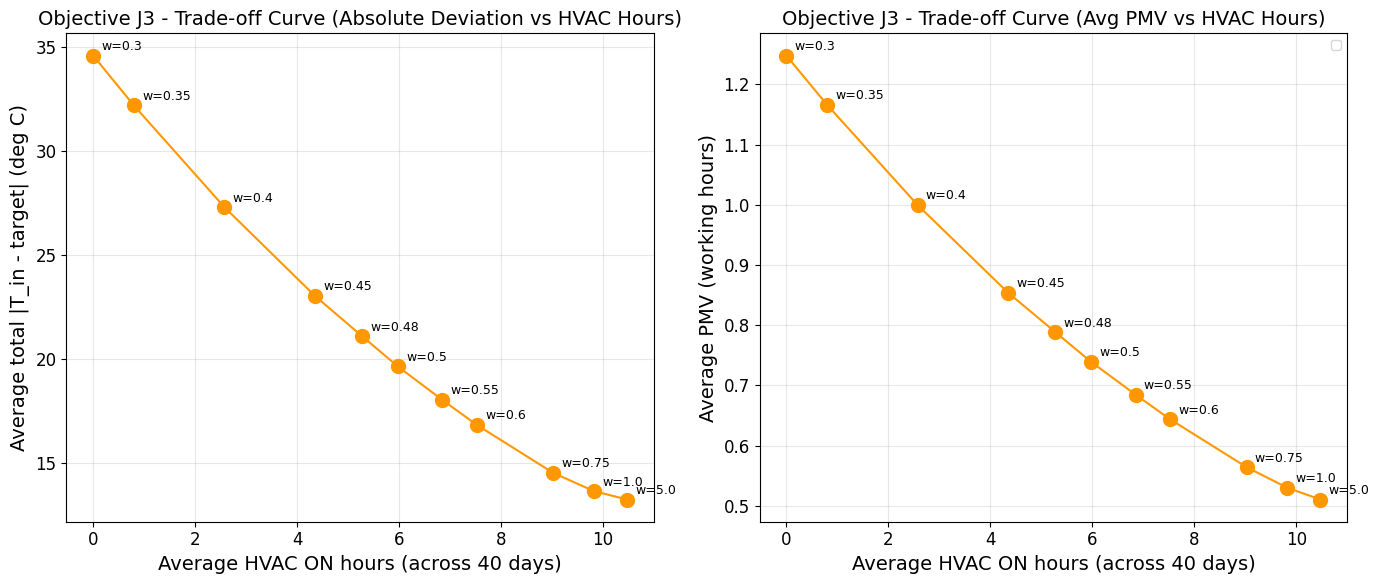

=== Objective J3: metrics by weight (averaged over 40 daily sessions) ===


,weight,HVAC Hours,Avg HVAC Hours,Avg T_in (work),Max T_in (work),Number of Violations,Avg Number of Violations,Avg Discomfort (all work hrs),Avg PMV (work)
0,0.30,0,0.00,28.83,29.37,286,7.15,2.01,1.248
1,0.35,32,0.80,28.56,29.24,274,6.85,1.79,1.166
2,0.40,103,2.58,28.02,28.91,239,5.98,1.39,1.000
3,0.45,174,4.35,27.54,28.52,202,5.05,1.05,0.854
4,0.48,211,5.28,27.33,28.29,190,4.75,0.91,0.789
5,0.50,239,5.98,27.16,28.18,187,4.68,0.80,0.739
6,0.55,274,6.85,26.99,27.89,177,4.42,0.69,0.685
7,0.60,301,7.52,26.85,27.79,171,4.28,0.59,0.644
8,0.75,361,9.02,26.59,27.34,155,3.88,0.43,0.564
9,1.00,393,9.82,26.48,26.86,152,3.80,0.38,0.530


In [64]:
weight_grid_obj3 = [0.3, 0.35, 0.4, 0.45, 0.48, 0.5, 0.55, 0.6, 0.75, 1, 5]

original_w3 = W3_ABS_DEVIATION
pareto_rows_obj3 = []
weight_rows_obj3 = []

for w in weight_grid_obj3:
    W3_ABS_DEVIATION = w
    day_metrics = []

    for session in DAILY_SESSIONS:
        history_data = data_clean[:session['history_end']]
        test_data    = data_clean[session['test_start']:].iloc[:session['n_hours']].copy()
        initial_history = list(history_data['t_in'].tail(24).values)

        result = run_milp_obj3(test_data, initial_history)

        t_pred = pd.Series(result['t_in_pred'], index=test_data.index)
        work   = test_data['is_working_hours']

        day_metrics.append(compute_day_metrics(result['hvac_schedule'], t_pred, work))
        day_metrics[-1]['abs_deviation_sum'] = float((t_pred[work] - TARGET_TEMP).abs().sum())

    weight_rows_obj3.append(aggregate_weight_row(w, day_metrics))
    pareto_rows_obj3.append({
        'weight': w,
        'avg_hvac_hours': np.mean([d['HVAC Hours'] for d in day_metrics]),
        'avg_deviation': np.mean([d['abs_deviation_sum'] for d in day_metrics]),
        'avg_pmv': np.mean([d['Avg PMV (work)'] for d in day_metrics]),
    })

W3_ABS_DEVIATION = original_w3

sweep_df_obj3     = pd.DataFrame(pareto_rows_obj3)
obj3_weight_table = pd.DataFrame(weight_rows_obj3).round({
    'Avg HVAC Hours': 2,
    'Avg T_in (work)': 2,
    'Max T_in (work)': 2,
    'Avg PMV (work)': 3,
    'Avg Number of Violations': 2,
    'Avg Discomfort (all work hrs)': 2,
})

n_days = len(DAILY_SESSIONS)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

ax1.plot(sweep_df_obj3['avg_hvac_hours'], sweep_df_obj3['avg_deviation'], 'o-', color='#FF9800')
for _, row in sweep_df_obj3.iterrows():
    ax1.annotate(f"w={row['weight']}", (row['avg_hvac_hours'], row['avg_deviation']),
                 textcoords="offset points", xytext=(6, 4), fontsize=9)
ax1.set_xlabel(f'Average HVAC ON hours (across {n_days} days)')
ax1.set_ylabel('Average total |T_in - target| (deg C)')
ax1.set_title('Objective J3 - Trade-off Curve (Absolute Deviation vs HVAC Hours)')
ax1.grid(alpha=0.3)

ax2.plot(sweep_df_obj3['avg_hvac_hours'], sweep_df_obj3['avg_pmv'], 'o-', color='#FF9800')
for _, row in sweep_df_obj3.iterrows():
    ax2.annotate(f"w={row['weight']}", (row['avg_hvac_hours'], row['avg_pmv']),
                 textcoords="offset points", xytext=(6, 4), fontsize=9)
ax2.set_xlabel(f'Average HVAC ON hours (across {n_days} days)')
ax2.set_ylabel('Average PMV (working hours)')
ax2.set_title('Objective J3 - Trade-off Curve (Avg PMV vs HVAC Hours)')
ax2.legend(fontsize=9, loc='best')
ax2.grid(alpha=0.3)

fig.tight_layout()
plt.show()

print(f"=== Objective J3: metrics by weight (averaged over {n_days} daily sessions) ===")
display(obj3_weight_table)

### Baseline

In [65]:
baseline_rows = []
for src_label, use_simulated in [('Actual', False), ('Simulated Actual', True)]:
    day_metrics = []
    for session in DAILY_SESSIONS:
        history_data = data_clean[:session['history_end']]
        test_data    = data_clean[session['test_start']:].iloc[:session['n_hours']].copy()
        initial_history = list(history_data['t_in'].tail(24).values)

        actual_schedule = build_actual_schedule(test_data)
        work = test_data['is_working_hours']

        if use_simulated:
            t_pred = pd.Series(simulate_temperature(actual_schedule, test_data, initial_history),
                                index=test_data.index)
        else:
            t_pred = test_data['t_in']

        day_metrics.append(compute_day_metrics(actual_schedule, t_pred, work))

    baseline_rows.append(aggregate_weight_row(src_label, day_metrics))

baseline_table = pd.DataFrame(baseline_rows).rename(columns={'weight': 'Source'}).round({
    'Avg HVAC Hours': 2,
    'Avg T_in (work)': 2,
    'Max T_in (work)': 2,
    'Avg PMV (work)': 3,
    'Avg Number of Violations': 2,
    'Avg Discomfort (all work hrs)': 2,
})

print(f"\n=== Actual vs Simulated Actual: same metrics, averaged over {n_days} daily sessions ===")
display(baseline_table)



=== Actual vs Simulated Actual: same metrics, averaged over 40 daily sessions ===


,Source,HVAC Hours,Avg HVAC Hours,Avg T_in (work),Max T_in (work),Number of Violations,Avg Number of Violations,Avg Discomfort (all work hrs),Avg PMV (work)
0,Actual,323,8.07,26.56,27.68,115,2.88,0.25,0.554
1,Simulated Actual,323,8.07,26.86,27.50,177,4.42,0.56,0.647


## Sessions -- head-to-head comparison of all 3 objectives using chosen weights

In [ ]:
import time

# Objective weights, chosen for the head-to-head comparison below.
W1_VIOLATION_DEGREES = 3           # Obj 1: HVAC hours + w1 * sum(violation degrees)
W2_VIOLATION_COUNT   = 10.0        # Obj 2: HVAC hours + w2 * count(violating hours)
W3_ABS_DEVIATION     = 0.6         # Obj 3: HVAC hours + w3 * sum(|T_in - target|)

METHODS = [
    ('Obj1_ViolDeg',   run_milp_obj1),
    ('Obj2_ViolCount', run_milp_obj2),
    ('Obj3_AbsDev',    run_milp_obj3),
]

all_session_results    = {}   # label -> DataFrame
all_session_runtimes   = {}   # label -> {method_name: seconds}
all_session_objectives = {}   # label -> {method_name: native objective value}


def compute_method_metrics(df, method_name, label=None, schedule_col=None, temp_col=None, real_consumption=None):
    schedule_col = schedule_col or f'{method_name}_schedule'
    temp_col     = temp_col or f'{method_name}_t_in_pred'

    sched  = df.get(schedule_col)
    t_pred = df.get(temp_col)
    work   = df['is_working_hours']

    na_row = {
        'HVAC Hours': 'N/A', 'Switches': 'N/A', 'Avg T_in (work)': 'N/A', 'Max T_in (work)': 'N/A',
        'Comfort Violation Hours': 'N/A', 'Avg Discomfort (all work hrs)': 'N/A',
        'Avg Discomfort (violated hrs)': 'N/A', 'Avg PMV (work)': 'N/A', 'Energy Proxy (Wh)': 'N/A',
        'Objective Cost': 'N/A', 'Runtime (s)': 'N/A',
    }
    if sched is None or sched.isna().all():
        return na_row

    sched  = sched.astype(float)
    t_pred = t_pred.astype(float)

    hvac_h   = int((sched > 0).sum())
    switches = int((sched.diff().fillna(0) != 0).sum())
    avg_t    = round(float(t_pred[work].mean()), 2)
    max_t    = round(float(t_pred[work].max()), 2)

    distance = pd.Series(0.0, index=t_pred.index)
    below = t_pred < LOWER_LIMIT
    above = t_pred > UPPER_LIMIT
    distance[below] = LOWER_LIMIT - t_pred[below]
    distance[above] = t_pred[above] - UPPER_LIMIT

    work_distance = distance[work]
    violated_mask = work_distance > 0
    viol_hours    = int(violated_mask.sum())

    avg_disc_all  = round(float(work_distance.mean()), 3)
    avg_disc_viol = round(float(work_distance[violated_mask].mean()), 3) if viol_hours > 0 else 'N/A'

    if real_consumption is not None:
        energy_proxy = round(float(real_consumption), 1)
    else:
        energy_proxy = round(hvac_h * avg_consumption_per_hour, 1)

    obj_cost = all_session_objectives.get(label, {}).get(method_name) if label is not None else None
    obj_cost = round(obj_cost, 3) if isinstance(obj_cost, (int, float)) else 'N/A'

    runtime = all_session_runtimes.get(label, {}).get(method_name) if label is not None else None
    runtime = round(runtime, 2) if isinstance(runtime, (int, float)) else 'N/A'

    work_t_in = t_pred[work].values
    pmv_vals  = pmv_ppd_iso(tdb=work_t_in, tr=work_t_in, vr=PMV_AIR_VELOCITY, rh=PMV_RH,
                             met=PMV_MET, clo=PMV_CLO, limit_inputs=False).pmv
    avg_pmv   = round(float(np.mean(pmv_vals)), 3)

    return {
        'HVAC Hours': hvac_h,
        'Switches': switches,
        'Avg T_in (work)': avg_t,
        'Max T_in (work)': max_t,
        'Comfort Violation Hours': viol_hours,
        'Avg Discomfort (all work hrs)': avg_disc_all,
        'Avg Discomfort (violated hrs)': avg_disc_viol,
        'Avg PMV (work)': avg_pmv,
        'Energy Proxy (Wh)': energy_proxy,
        'Objective Cost': obj_cost,
        'Runtime (s)': runtime,
    }

print("Shared metric helper defined.")


Shared metric helper defined.


### Objective 1 - Violation Degrees

In [67]:
# Run Obj1_ViolDeg across all 27 daily sessions
method_name = 'Obj1_ViolDeg'

for session in DAILY_SESSIONS:
    label   = session['label']
    n_hours = session['n_hours']

    history_data = data_clean[:session['history_end']]
    test_data    = data_clean[session['test_start']:].iloc[:n_hours].copy()

    if len(test_data) < n_hours:
        print(f"Skipping {label} - only {len(test_data)} hours available")
        continue

    initial_history = list(history_data['t_in'].tail(24).values)

    if label not in all_session_results:
        df = pd.DataFrame(index=test_data.index)
        df['t_out']               = test_data['t_out'].values
        df['is_working_hours']    = test_data['is_working_hours'].values
        df['actual_cooling_mode'] = test_data['cooling_mode'].values
        df['actual_t_in']         = test_data['t_in'].values
        df['actual_consumption']  = test_data['consumption'].values

        actual_schedule = build_actual_schedule(test_data)
        df['actual_t_in_simulated'] = simulate_temperature(actual_schedule, test_data, initial_history)

        all_session_results[label] = df
    else:
        df = all_session_results[label]

    print(f"{label} -- {method_name} ...", end=' ', flush=True)
    try:
        start_time = time.time()
        result = run_milp_obj1(test_data, initial_history)
        elapsed = time.time() - start_time
        df[f'{method_name}_schedule']  = result['hvac_schedule']
        df[f'{method_name}_t_in_pred'] = result['t_in_pred']
        all_session_runtimes.setdefault(label, {})[method_name]   = elapsed
        all_session_objectives.setdefault(label, {})[method_name] = result['objective_value']
        print(f"done  (HVAC hours: {sum(1 for x in result['hvac_schedule'] if x and x > 0)}, {elapsed:.1f}s)")
    except Exception as e:
        print(f"ERROR: {e}")
        df[f'{method_name}_schedule']  = None
        df[f'{method_name}_t_in_pred'] = None
        all_session_runtimes.setdefault(label, {})[method_name]   = None
        all_session_objectives.setdefault(label, {})[method_name] = None

print(f"\n{method_name} complete across all {len(DAILY_SESSIONS)} sessions.")


Day_2025-05-05 -- Obj1_ViolDeg ... 

done  (HVAC hours: 0, 0.0s)
Day_2025-05-06 -- Obj1_ViolDeg ... done  (HVAC hours: 0, 0.0s)
Day_2025-05-07 -- Obj1_ViolDeg ... done  (HVAC hours: 0, 0.0s)
Day_2025-05-08 -- Obj1_ViolDeg ... done  (HVAC hours: 3, 0.1s)
Day_2025-05-09 -- Obj1_ViolDeg ... done  (HVAC hours: 4, 0.1s)
Day_2025-05-19 -- Obj1_ViolDeg ... done  (HVAC hours: 0, 0.0s)
Day_2025-05-20 -- Obj1_ViolDeg ... done  (HVAC hours: 0, 0.0s)
Day_2025-05-21 -- Obj1_ViolDeg ... done  (HVAC hours: 1, 0.0s)
Day_2025-05-22 -- Obj1_ViolDeg ... done  (HVAC hours: 3, 0.1s)
Day_2025-05-23 -- Obj1_ViolDeg ... done  (HVAC hours: 3, 0.1s)
Day_2025-06-02 -- Obj1_ViolDeg ... done  (HVAC hours: 3, 0.1s)
Day_2025-06-03 -- Obj1_ViolDeg ... done  (HVAC hours: 6, 0.1s)
Day_2025-06-04 -- Obj1_ViolDeg ... done  (HVAC hours: 9, 0.0s)
Day_2025-06-05 -- Obj1_ViolDeg ... done  (HVAC hours: 12, 0.0s)
Day_2025-06-06 -- Obj1_ViolDeg ... done  (HVAC hours: 12, 0.0s)
Day_2025-08-25 -- Obj1_ViolDeg ... done  (HVAC hours: 12, 0.0s)
Day_2025-08-26 -- Obj1_V

### Objective 2 - Violation Count

In [68]:
# Run Obj2_ViolCount across all 27 daily sessions
method_name = 'Obj2_ViolCount'

for session in DAILY_SESSIONS:
    label   = session['label']
    n_hours = session['n_hours']

    history_data = data_clean[:session['history_end']]
    test_data    = data_clean[session['test_start']:].iloc[:n_hours].copy()

    if len(test_data) < n_hours:
        print(f"Skipping {label} - only {len(test_data)} hours available")
        continue

    initial_history = list(history_data['t_in'].tail(24).values)

    if label not in all_session_results:
        df = pd.DataFrame(index=test_data.index)
        df['t_out']               = test_data['t_out'].values
        df['is_working_hours']    = test_data['is_working_hours'].values
        df['actual_cooling_mode'] = test_data['cooling_mode'].values
        df['actual_t_in']         = test_data['t_in'].values
        df['actual_consumption']  = test_data['consumption'].values

        actual_schedule = build_actual_schedule(test_data)
        df['actual_t_in_simulated'] = simulate_temperature(actual_schedule, test_data, initial_history)

        all_session_results[label] = df
    else:
        df = all_session_results[label]

    print(f"{label} -- {method_name} ...", end=' ', flush=True)
    try:
        start_time = time.time()
        result = run_milp_obj2(test_data, initial_history)
        elapsed = time.time() - start_time
        df[f'{method_name}_schedule']  = result['hvac_schedule']
        df[f'{method_name}_t_in_pred'] = result['t_in_pred']
        all_session_runtimes.setdefault(label, {})[method_name]   = elapsed
        all_session_objectives.setdefault(label, {})[method_name] = result['objective_value']
        print(f"done  (HVAC hours: {sum(1 for x in result['hvac_schedule'] if x and x > 0)}, {elapsed:.1f}s)")
    except Exception as e:
        print(f"ERROR: {e}")
        df[f'{method_name}_schedule']  = None
        df[f'{method_name}_t_in_pred'] = None
        all_session_runtimes.setdefault(label, {})[method_name]   = None
        all_session_objectives.setdefault(label, {})[method_name] = None

print(f"\n{method_name} complete across all {len(DAILY_SESSIONS)} sessions.")


Day_2025-05-05 -- Obj2_ViolCount ... done  (HVAC hours: 0, 0.0s)
Day_2025-05-06 -- Obj2_ViolCount ... done  (HVAC hours: 0, 0.0s)
Day_2025-05-07 -- Obj2_ViolCount ... done  (HVAC hours: 0, 0.0s)
Day_2025-05-08 -- Obj2_ViolCount ... done  (HVAC hours: 3, 0.0s)
Day_2025-05-09 -- Obj2_ViolCount ... done  (HVAC hours: 4, 0.0s)
Day_2025-05-19 -- Obj2_ViolCount ... done  (HVAC hours: 0, 0.0s)
Day_2025-05-20 -- Obj2_ViolCount ... done  (HVAC hours: 0, 0.0s)
Day_2025-05-21 -- Obj2_ViolCount ... done  (HVAC hours: 1, 0.0s)
Day_2025-05-22 -- Obj2_ViolCount ... done  (HVAC hours: 3, 0.0s)
Day_2025-05-23 -- Obj2_ViolCount ... done  (HVAC hours: 4, 0.0s)
Day_2025-06-02 -- Obj2_ViolCount ... done  (HVAC hours: 3, 0.1s)
Day_2025-06-03 -- Obj2_ViolCount ... done  (HVAC hours: 6, 0.0s)
Day_2025-06-04 -- Obj2_ViolCount ... done  (HVAC hours: 9, 0.0s)
Day_2025-06-05 -- Obj2_ViolCount ... done  (HVAC hours: 6, 0.0s)
Day_2025-06-06 -- Obj2_ViolCount ... done  (HVAC hours: 0, 0.0s)
Day_2025-08-25 -- Obj2_Vi

### Objective 3 - Absolute Deviation (capped at OBJ3_TIME_LIMIT_SECONDS per session)

In [69]:
# Run Obj3_AbsDev across all 27 daily sessions
method_name = 'Obj3_AbsDev'

for session in DAILY_SESSIONS:
    label   = session['label']
    n_hours = session['n_hours']

    history_data = data_clean[:session['history_end']]
    test_data    = data_clean[session['test_start']:].iloc[:n_hours].copy()

    if len(test_data) < n_hours:
        print(f"Skipping {label} - only {len(test_data)} hours available")
        continue

    initial_history = list(history_data['t_in'].tail(24).values)

    if label not in all_session_results:
        df = pd.DataFrame(index=test_data.index)
        df['t_out']               = test_data['t_out'].values
        df['is_working_hours']    = test_data['is_working_hours'].values
        df['actual_cooling_mode'] = test_data['cooling_mode'].values
        df['actual_t_in']         = test_data['t_in'].values
        df['actual_consumption']  = test_data['consumption'].values

        actual_schedule = build_actual_schedule(test_data)
        df['actual_t_in_simulated'] = simulate_temperature(actual_schedule, test_data, initial_history)

        all_session_results[label] = df
    else:
        df = all_session_results[label]

    print(f"{label} -- {method_name} ...", end=' ', flush=True)
    try:
        start_time = time.time()
        result = run_milp_obj3(test_data, initial_history)
        elapsed = time.time() - start_time
        df[f'{method_name}_schedule']  = result['hvac_schedule']
        df[f'{method_name}_t_in_pred'] = result['t_in_pred']
        all_session_runtimes.setdefault(label, {})[method_name]   = elapsed
        all_session_objectives.setdefault(label, {})[method_name] = result['objective_value']
        print(f"done  (HVAC hours: {sum(1 for x in result['hvac_schedule'] if x and x > 0)}, {elapsed:.1f}s)")
    except Exception as e:
        print(f"ERROR: {e}")
        df[f'{method_name}_schedule']  = None
        df[f'{method_name}_t_in_pred'] = None
        all_session_runtimes.setdefault(label, {})[method_name]   = None
        all_session_objectives.setdefault(label, {})[method_name] = None

print(f"\n{method_name} complete across all {len(DAILY_SESSIONS)} sessions.")


Day_2025-05-05 -- Obj3_AbsDev ... done  (HVAC hours: 0, 0.0s)
Day_2025-05-06 -- Obj3_AbsDev ... done  (HVAC hours: 3, 0.0s)
Day_2025-05-07 -- Obj3_AbsDev ... done  (HVAC hours: 3, 0.1s)
Day_2025-05-08 -- Obj3_AbsDev ... done  (HVAC hours: 6, 0.0s)
Day_2025-05-09 -- Obj3_AbsDev ... done  (HVAC hours: 7, 0.1s)
Day_2025-05-19 -- Obj3_AbsDev ... done  (HVAC hours: 0, 0.0s)
Day_2025-05-20 -- Obj3_AbsDev ... done  (HVAC hours: 2, 0.0s)
Day_2025-05-21 -- Obj3_AbsDev ... done  (HVAC hours: 4, 0.1s)
Day_2025-05-22 -- Obj3_AbsDev ... done  (HVAC hours: 6, 0.0s)
Day_2025-05-23 -- Obj3_AbsDev ... done  (HVAC hours: 7, 0.0s)
Day_2025-06-02 -- Obj3_AbsDev ... done  (HVAC hours: 7, 0.0s)
Day_2025-06-03 -- Obj3_AbsDev ... done  (HVAC hours: 8, 0.0s)
Day_2025-06-04 -- Obj3_AbsDev ... done  (HVAC hours: 9, 0.0s)
Day_2025-06-05 -- Obj3_AbsDev ... done  (HVAC hours: 9, 0.0s)
Day_2025-06-06 -- Obj3_AbsDev ... done  (HVAC hours: 9, 0.0s)
Day_2025-08-25 -- Obj3_AbsDev ... done  (HVAC hours: 9, 0.0s)
Day_2025

## Plots

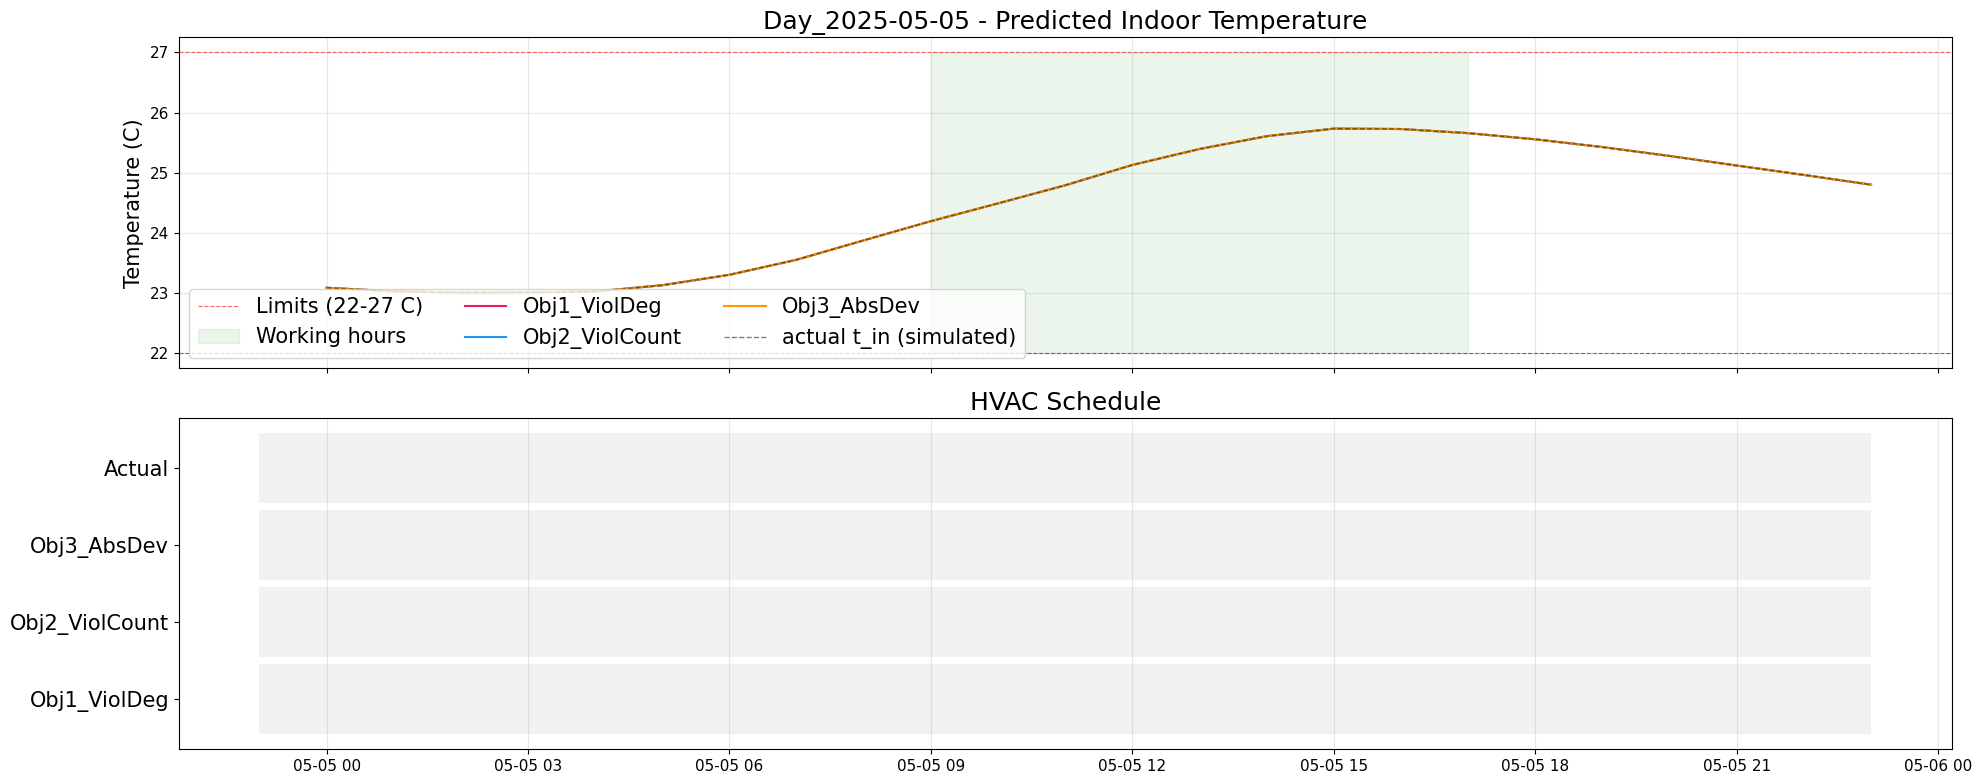

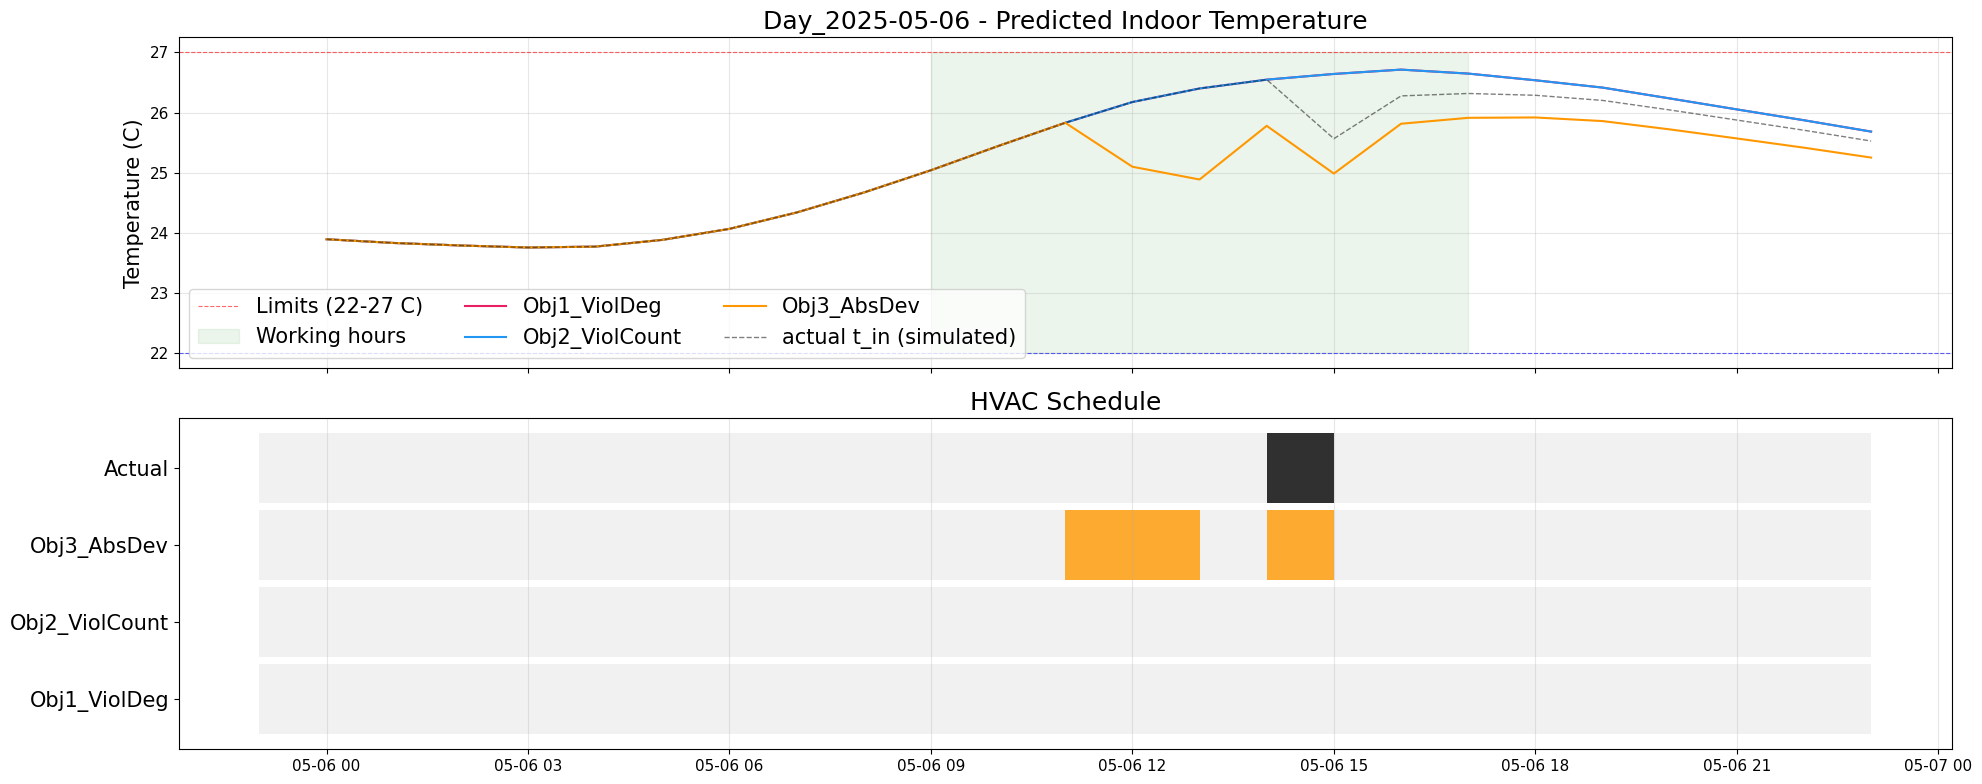

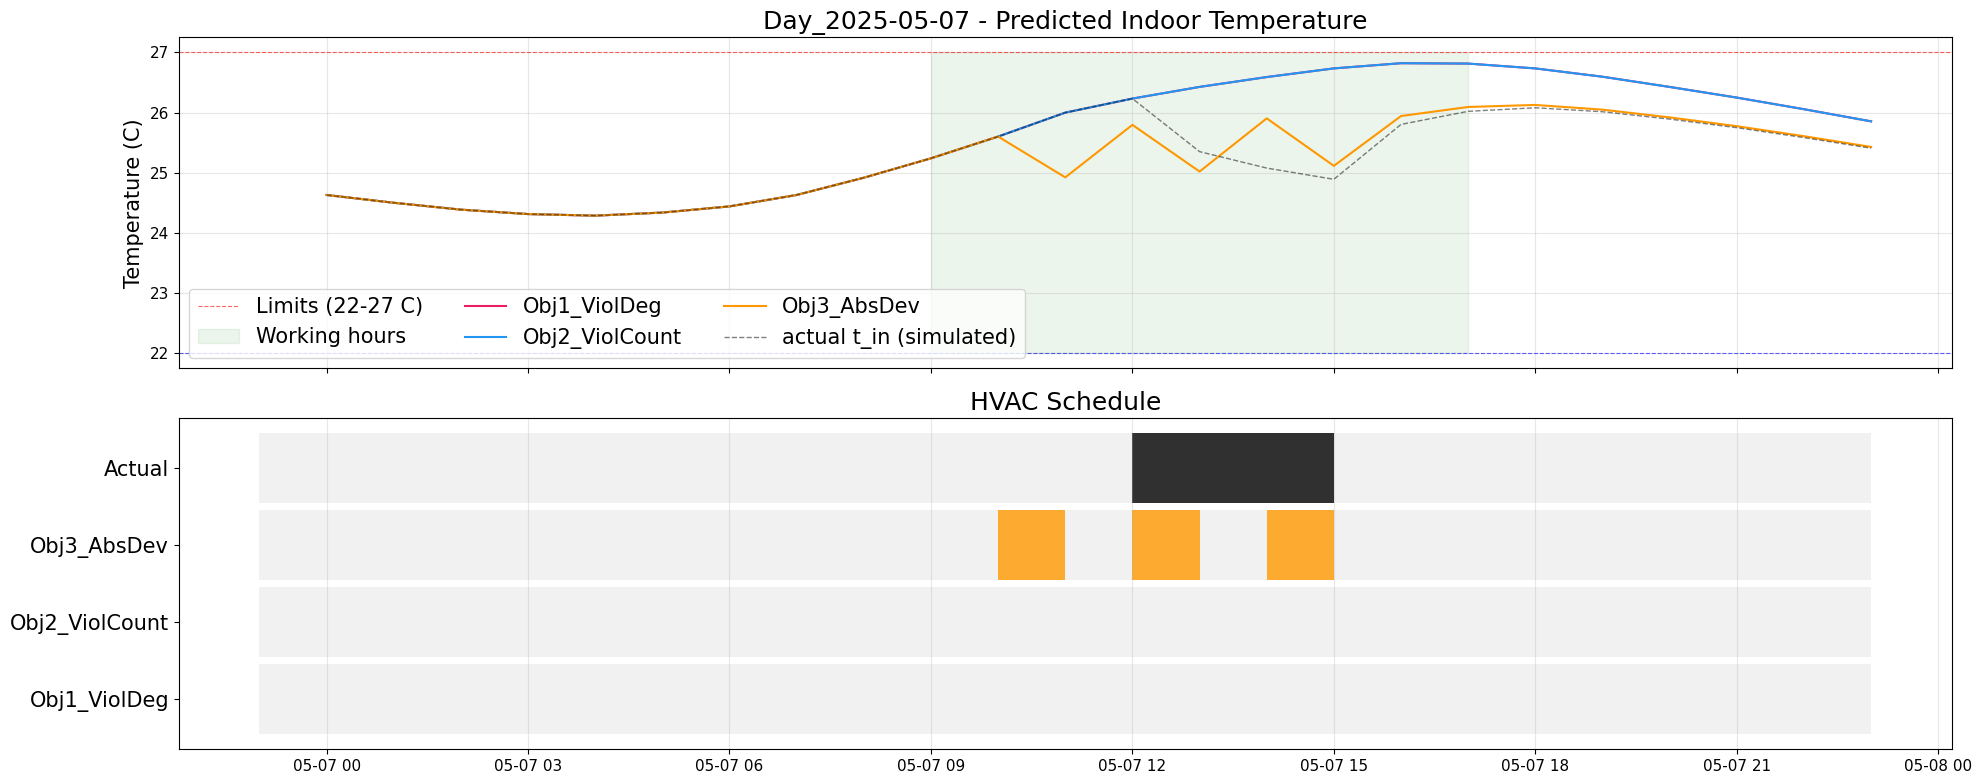

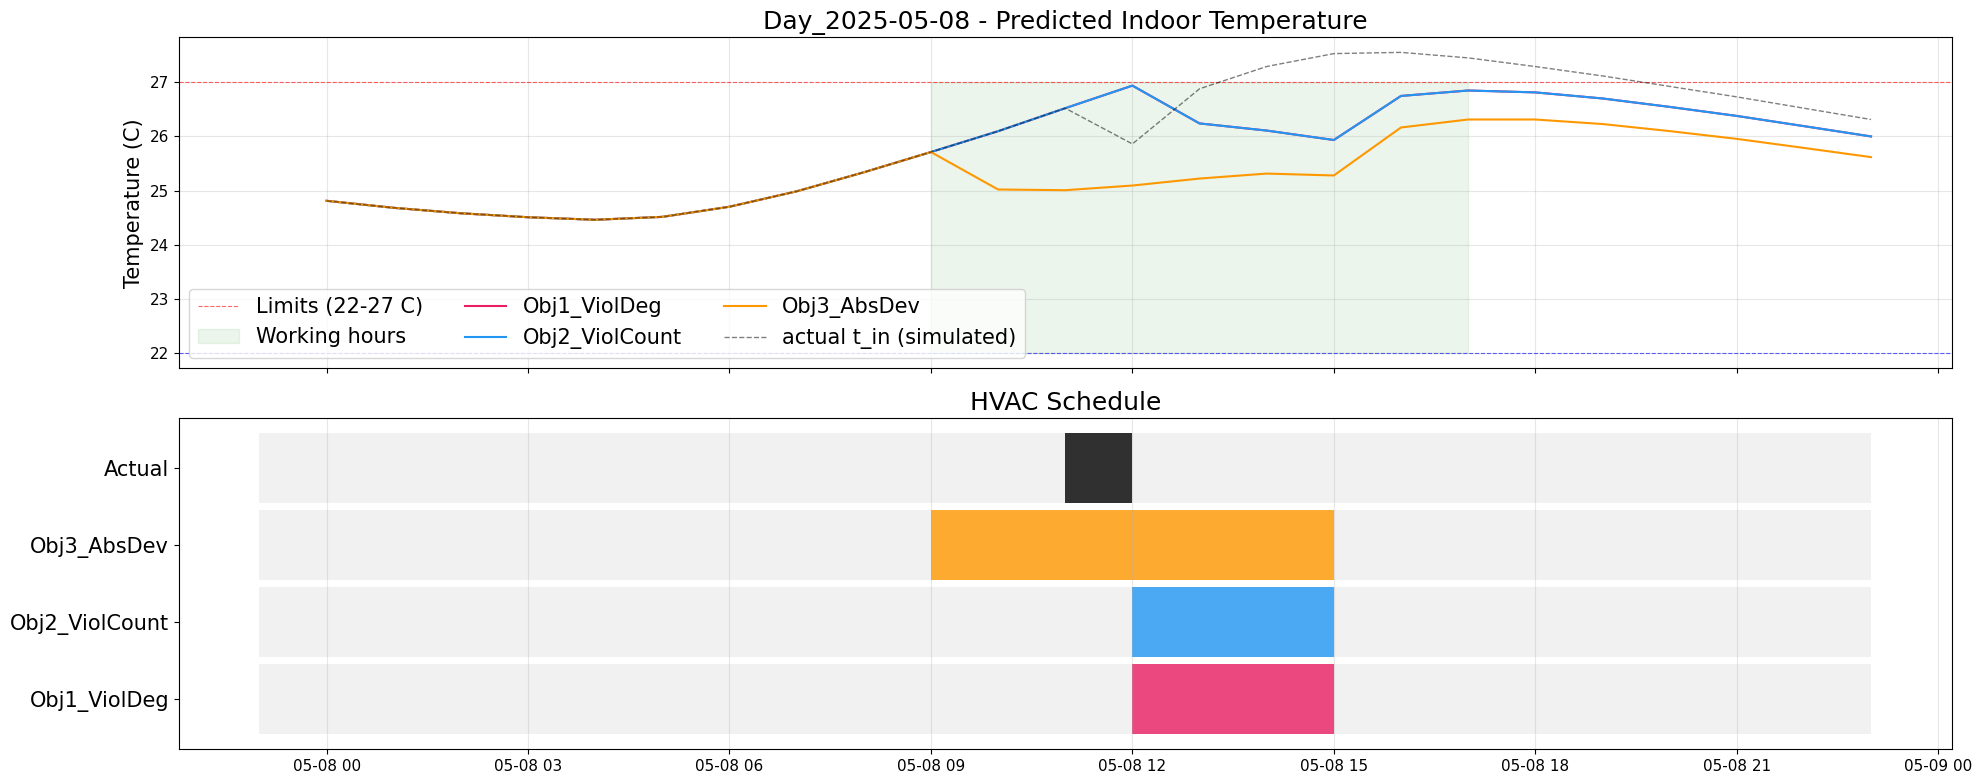

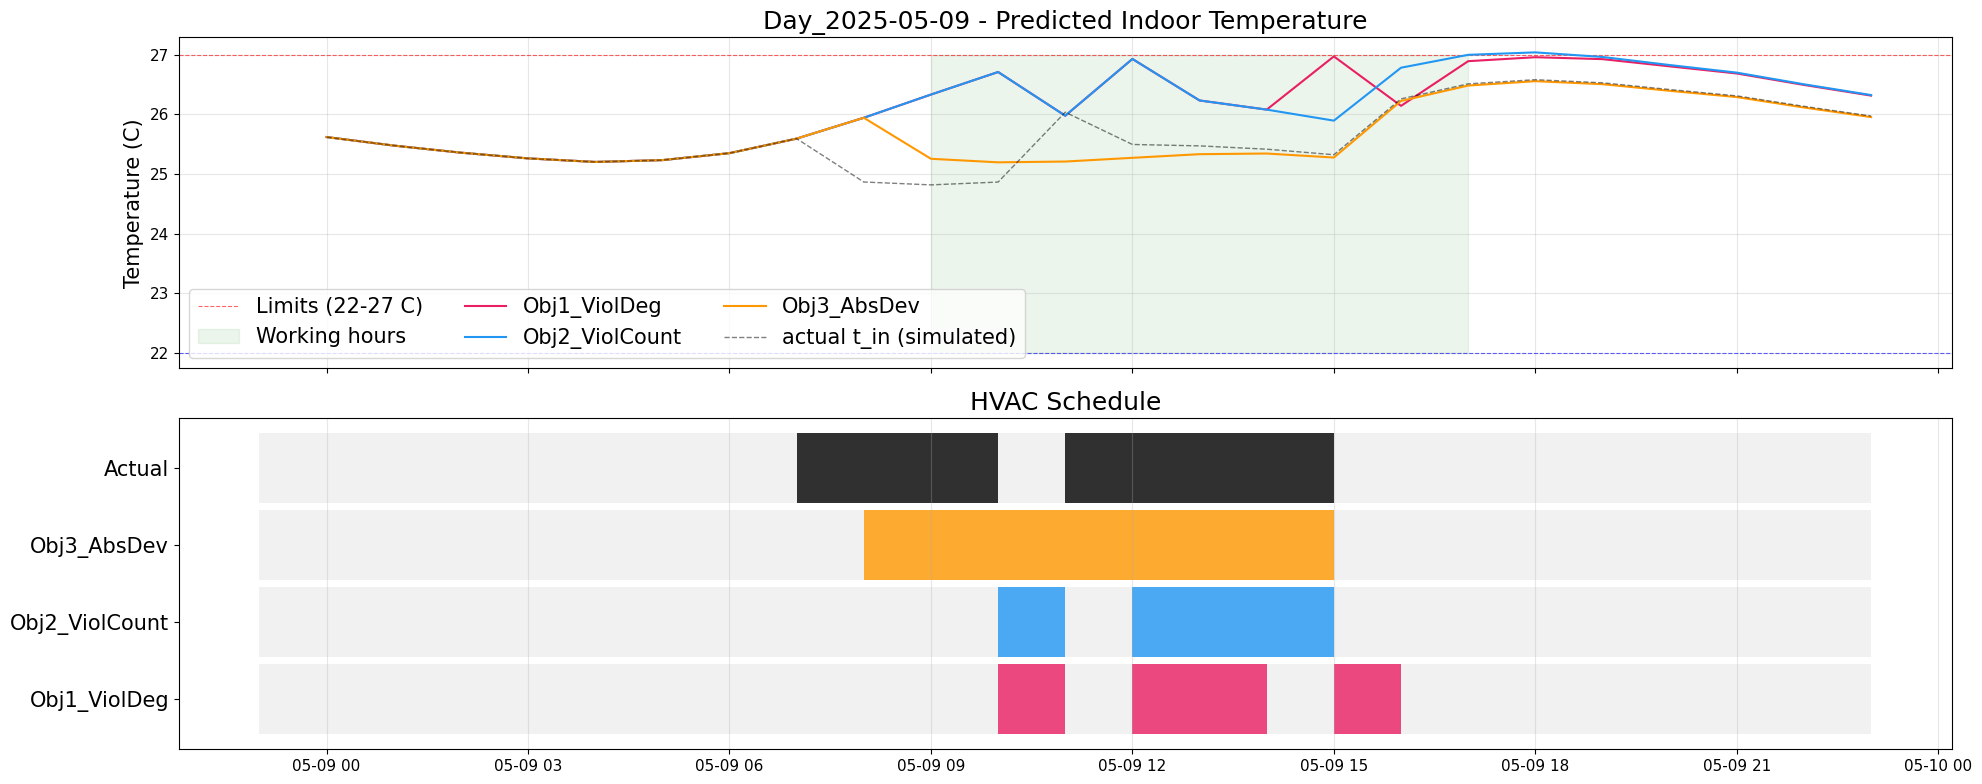

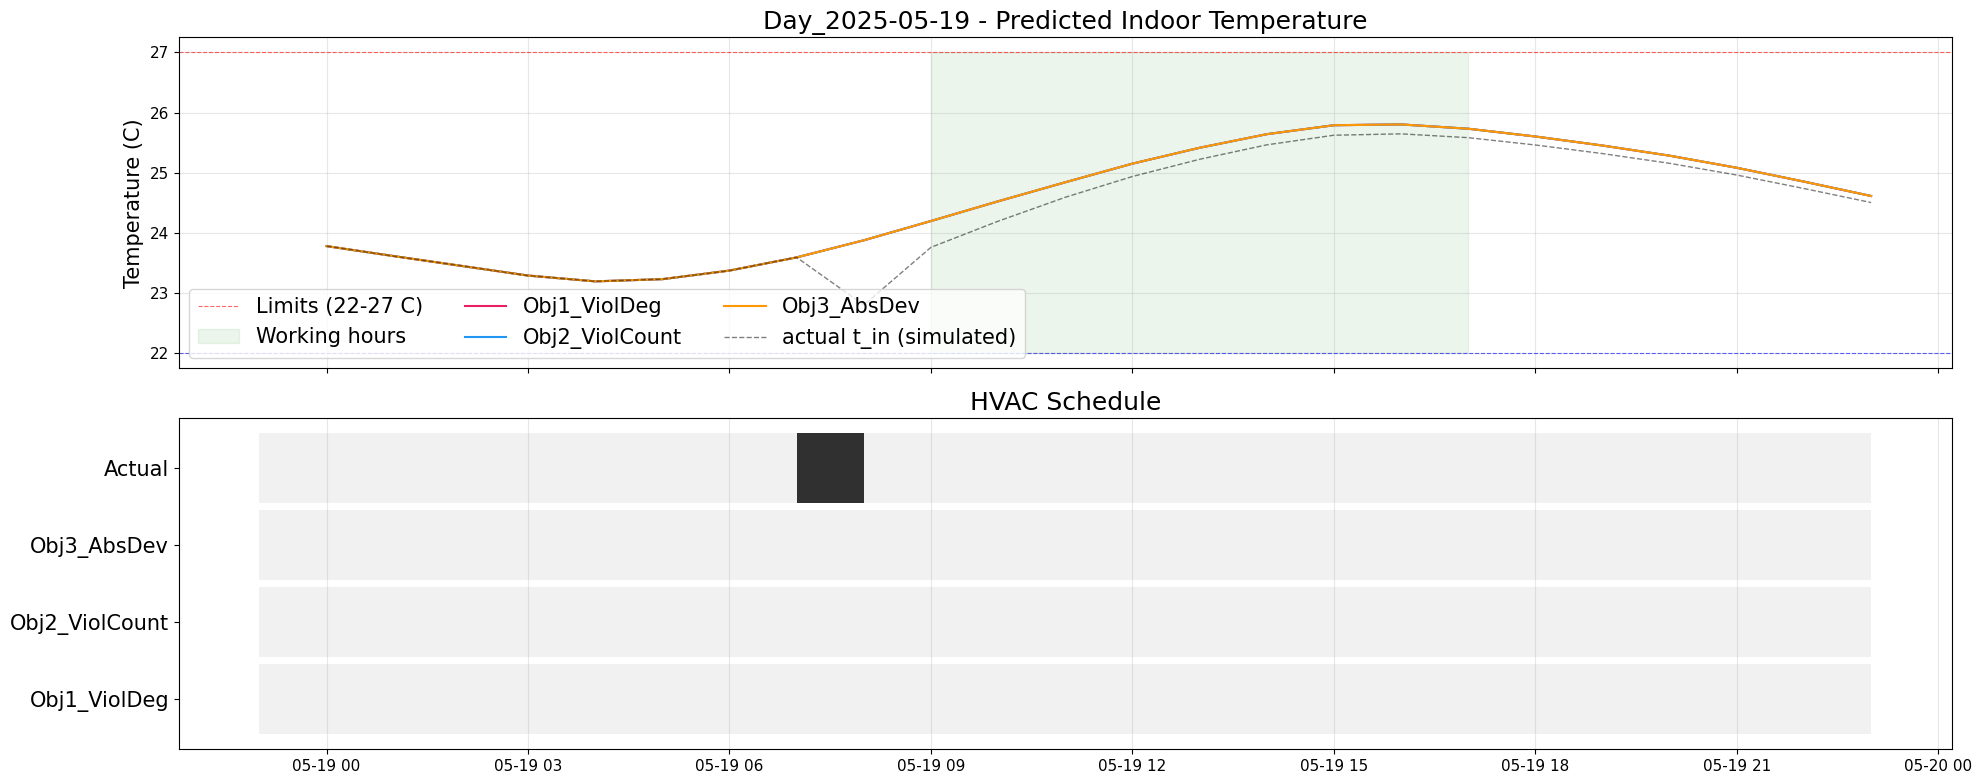

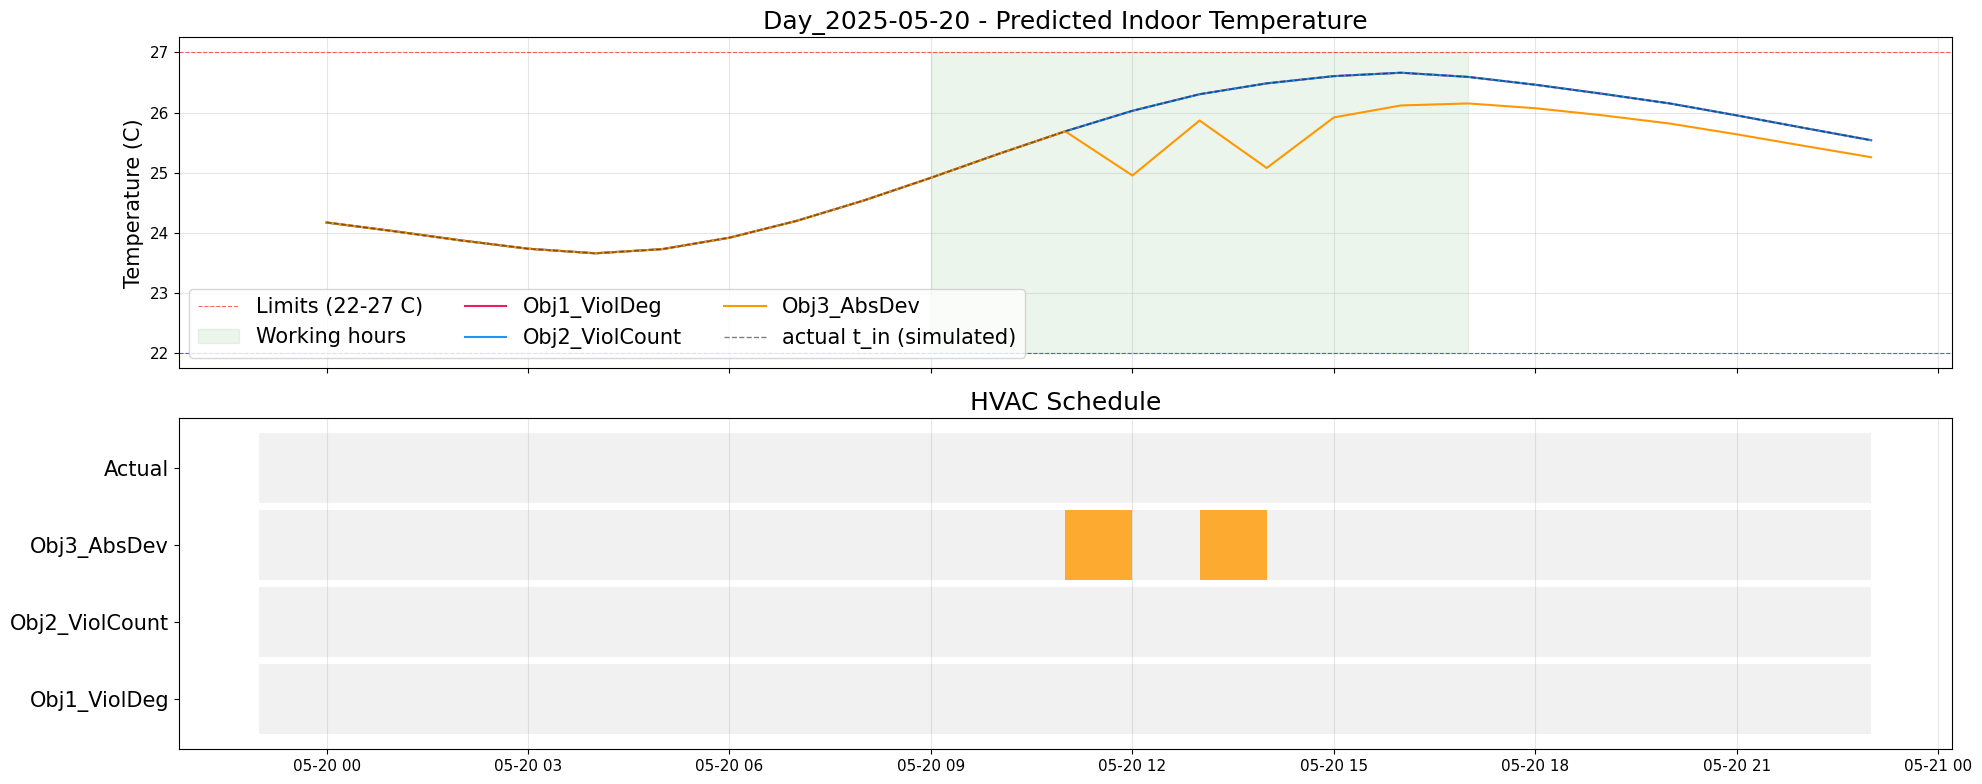

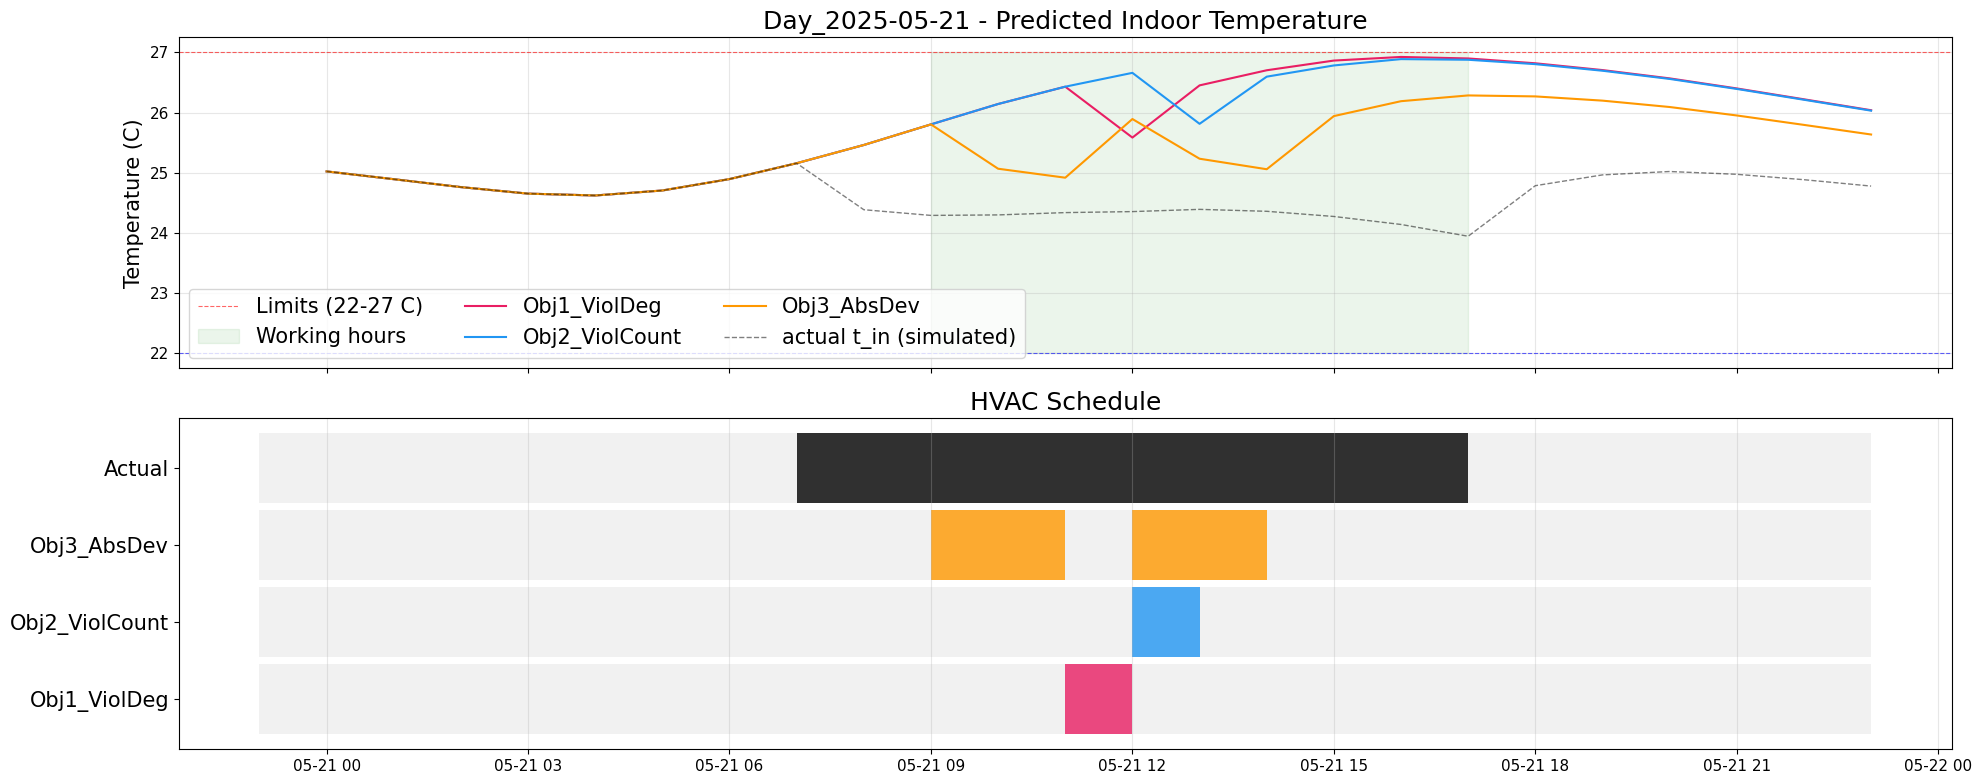

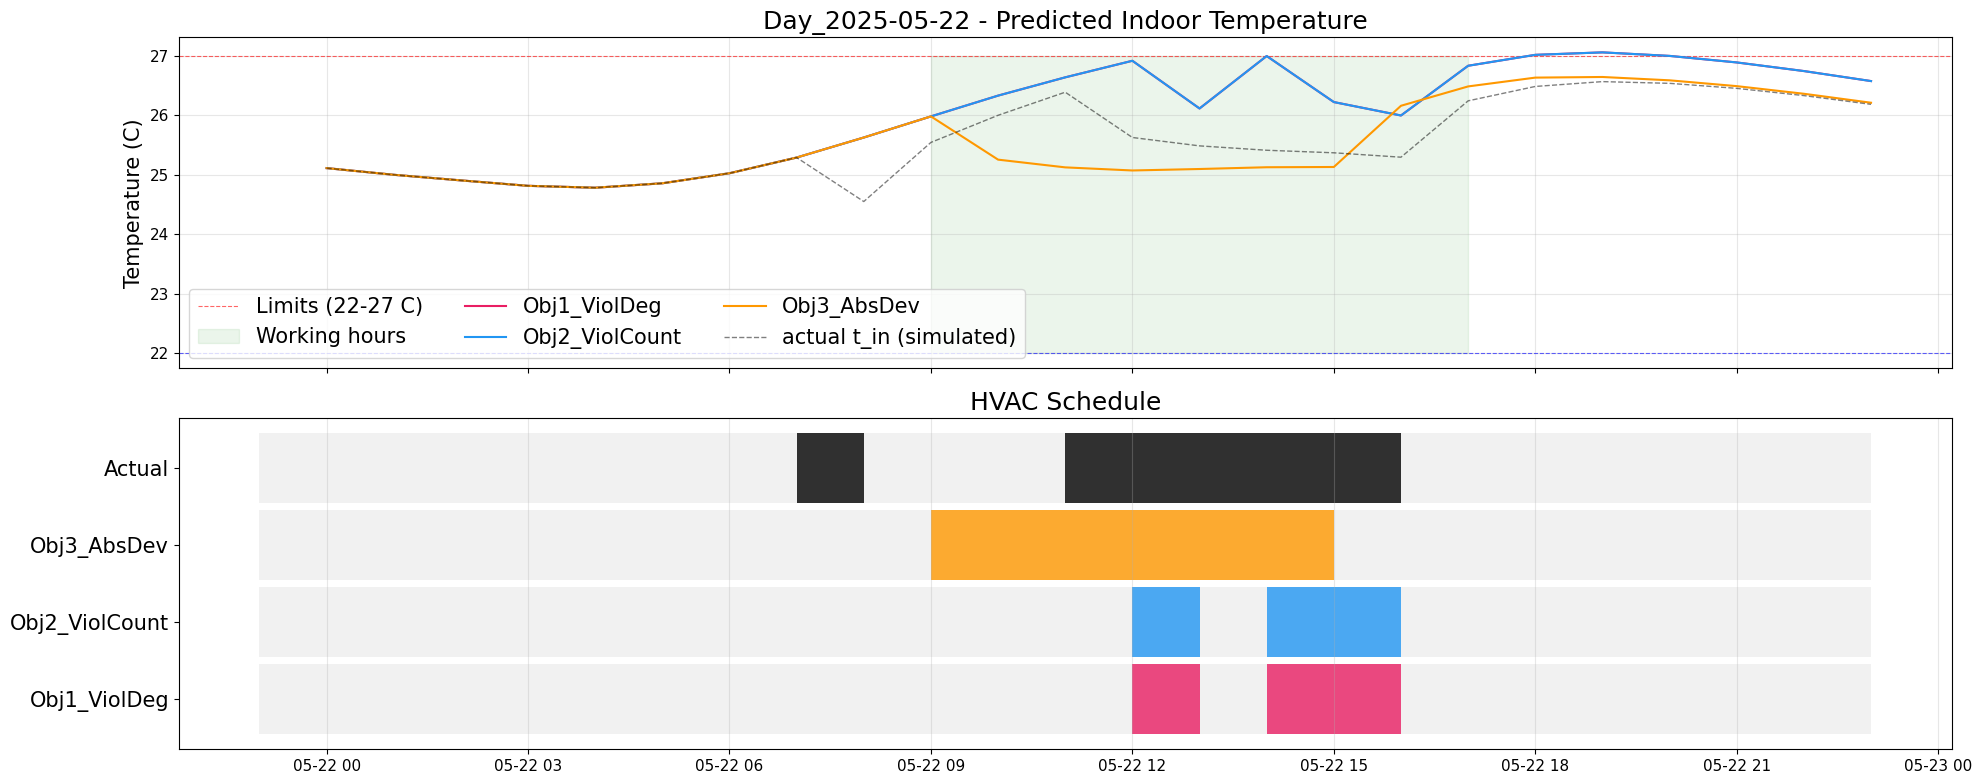

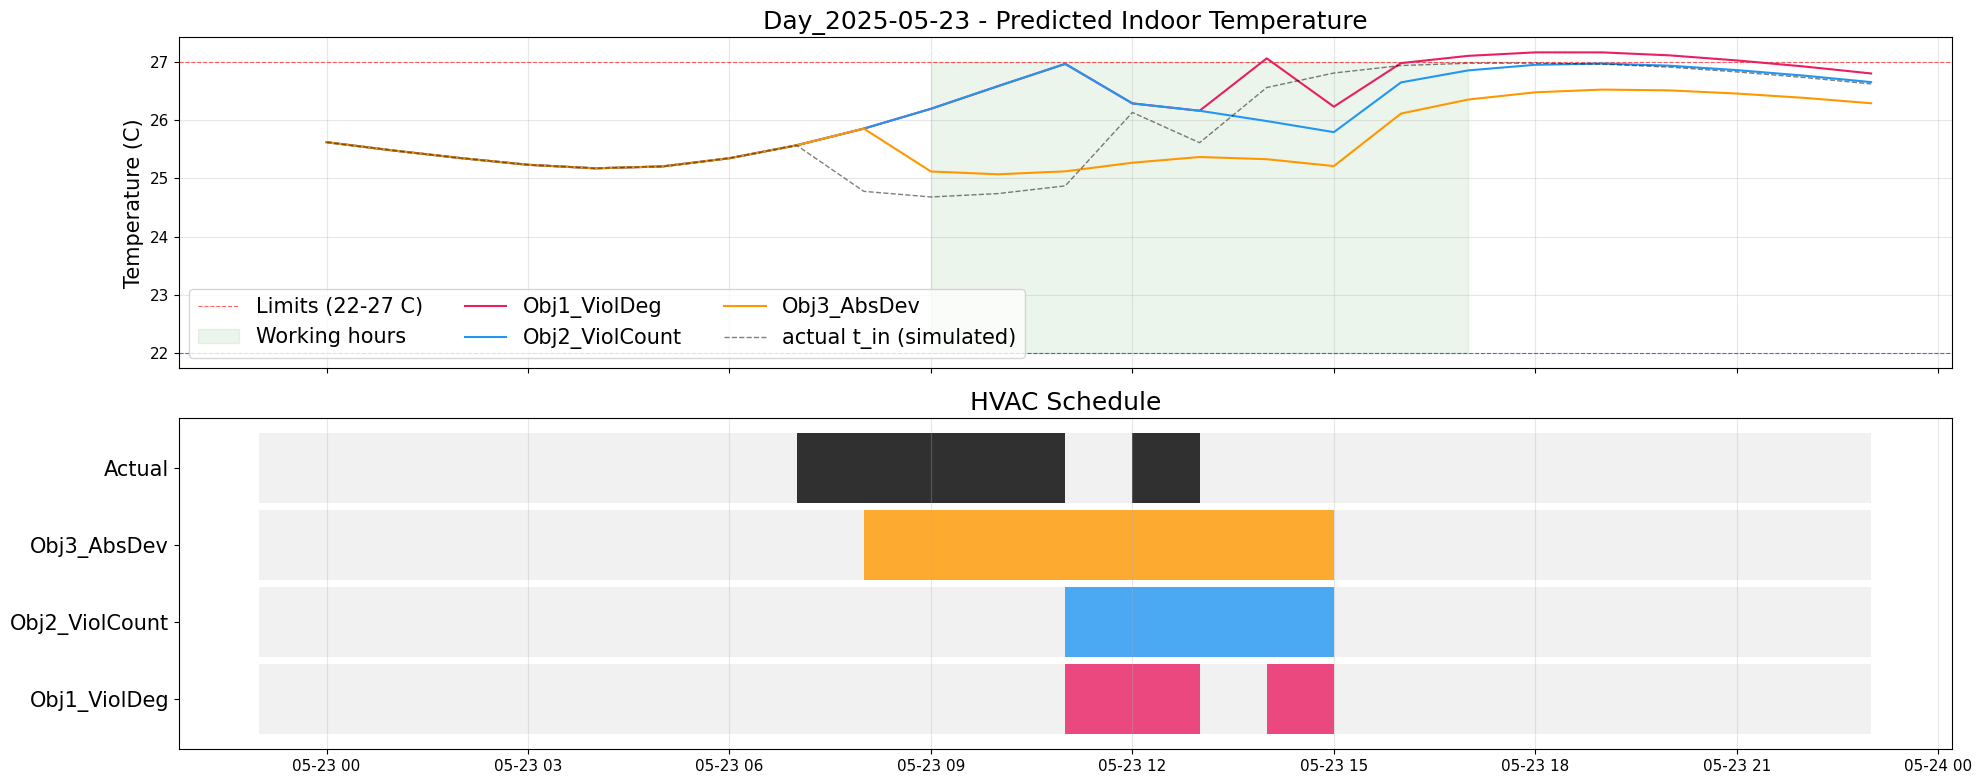

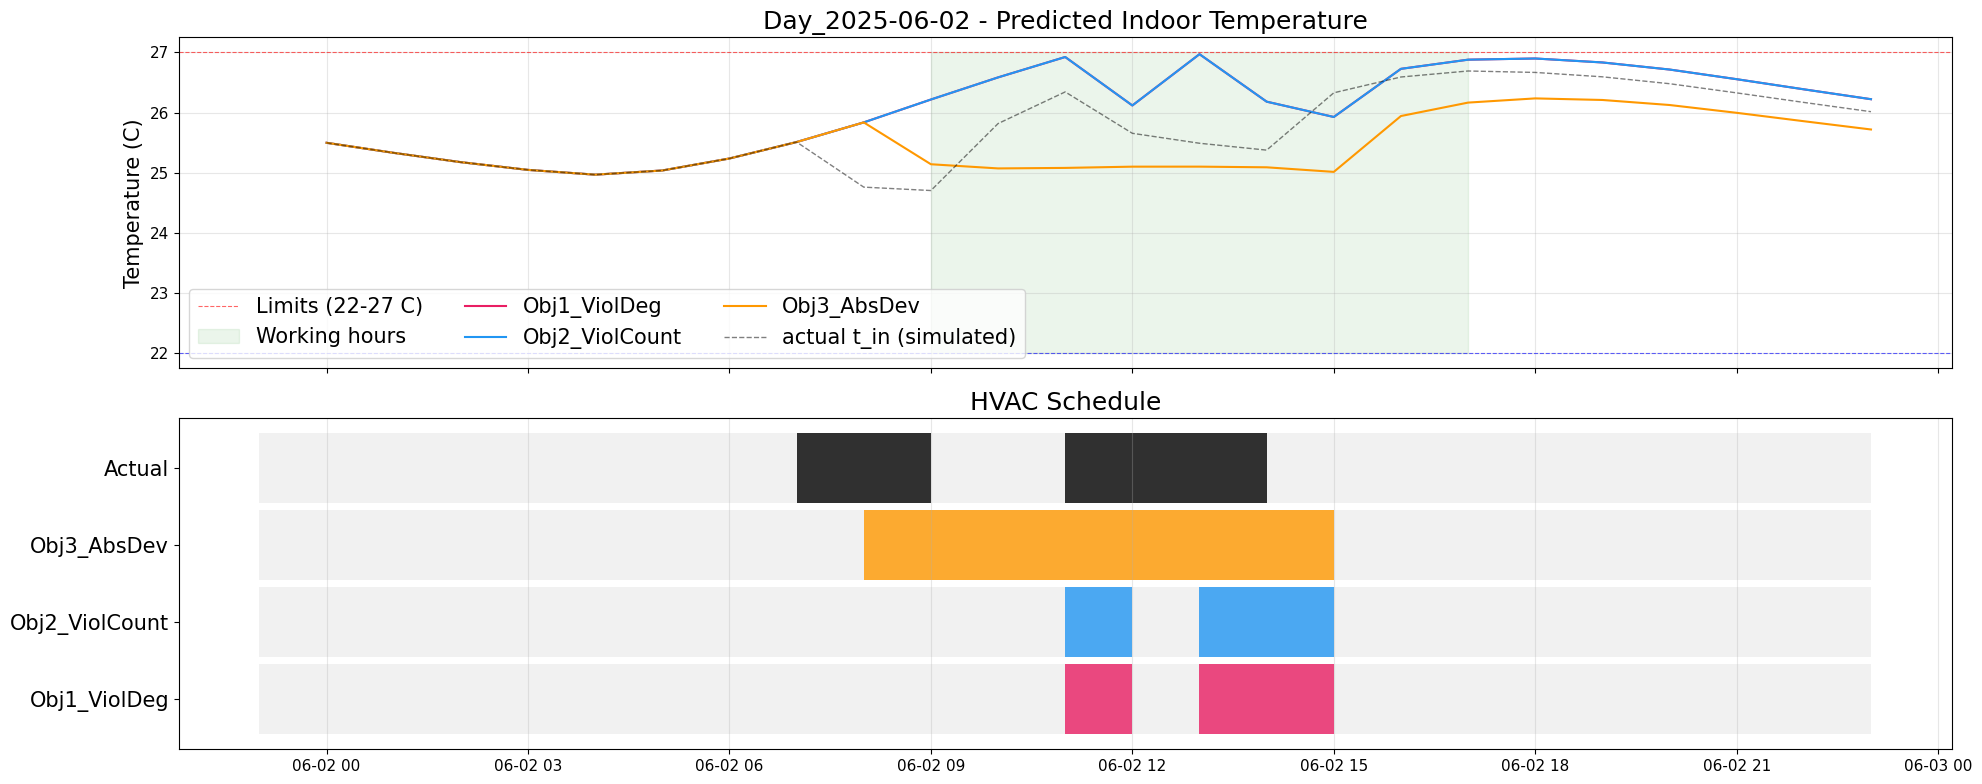

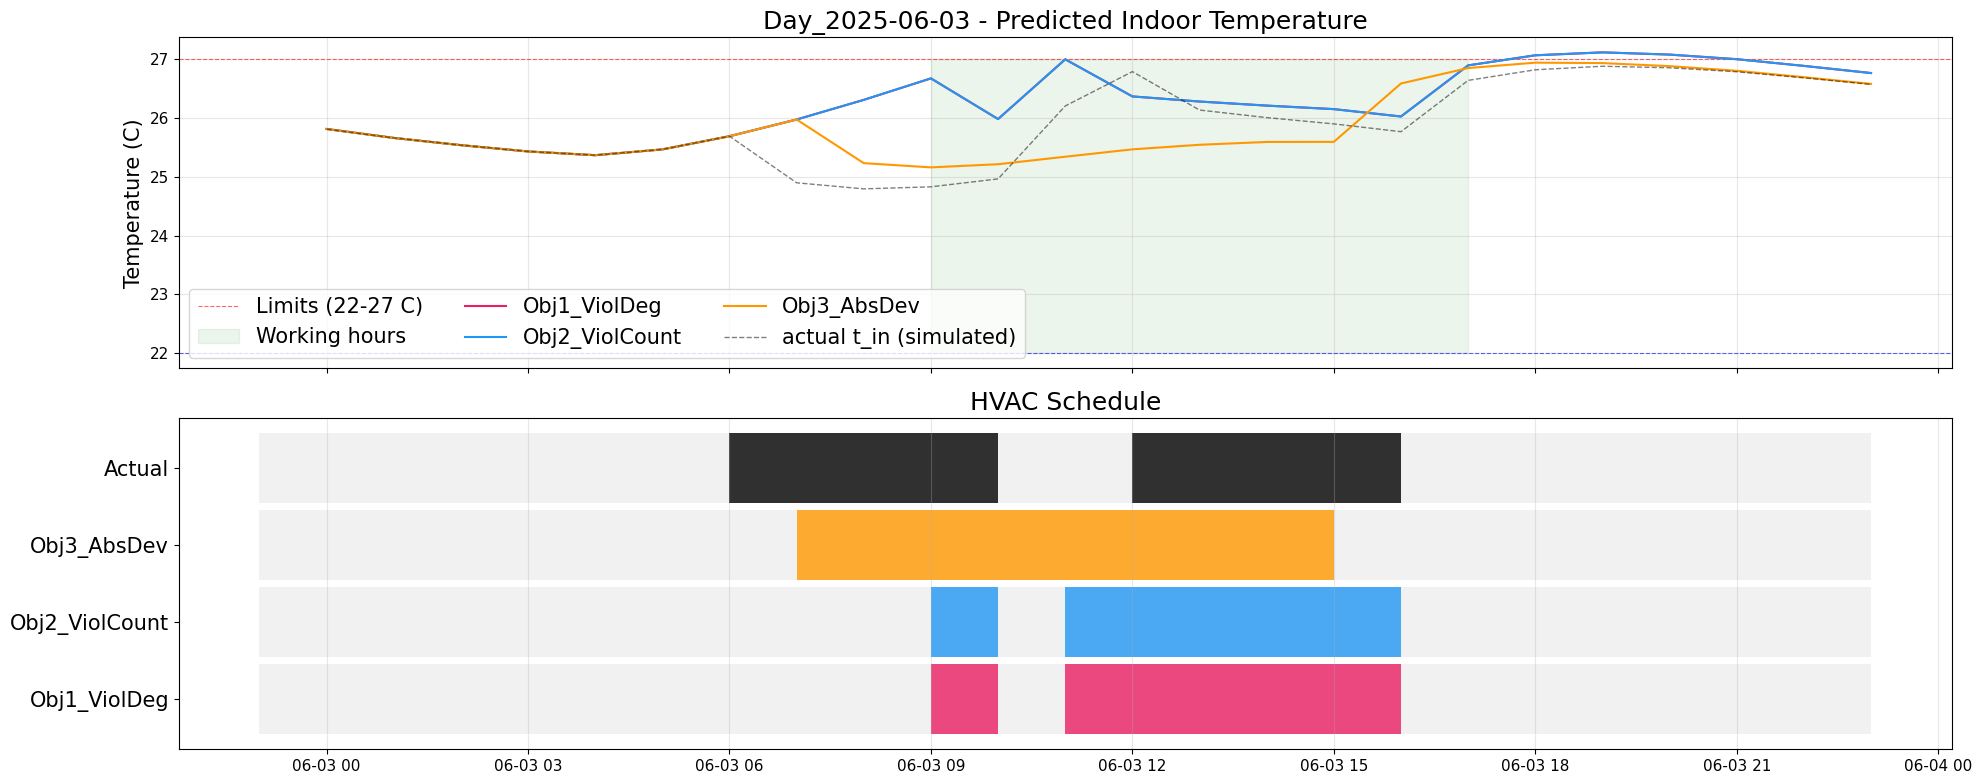

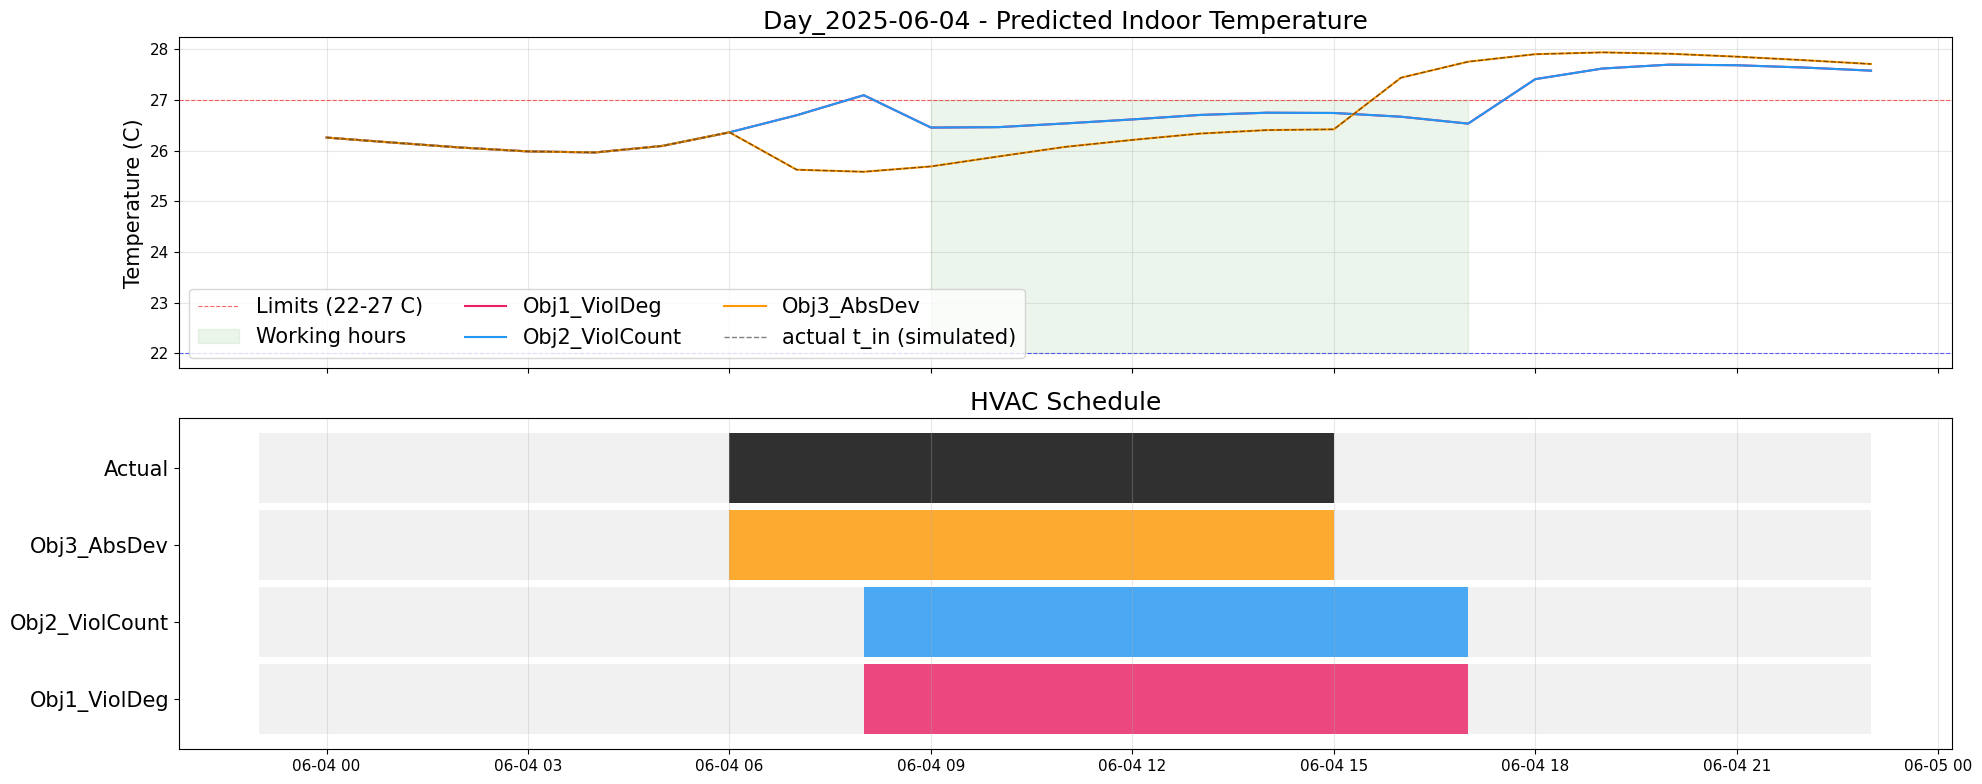

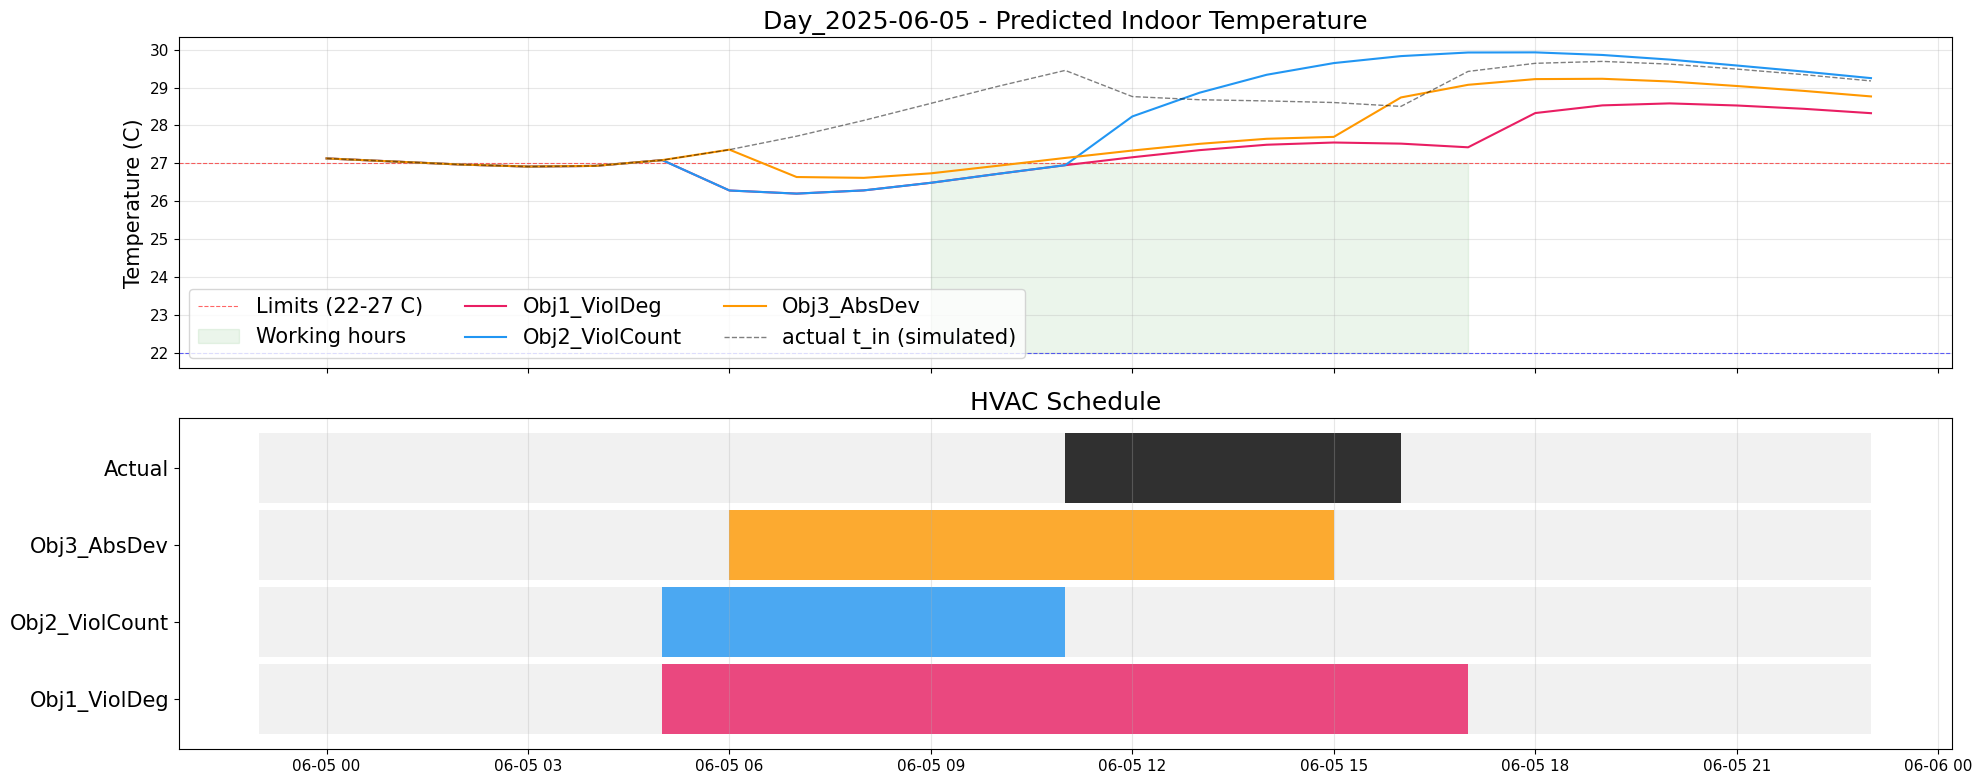

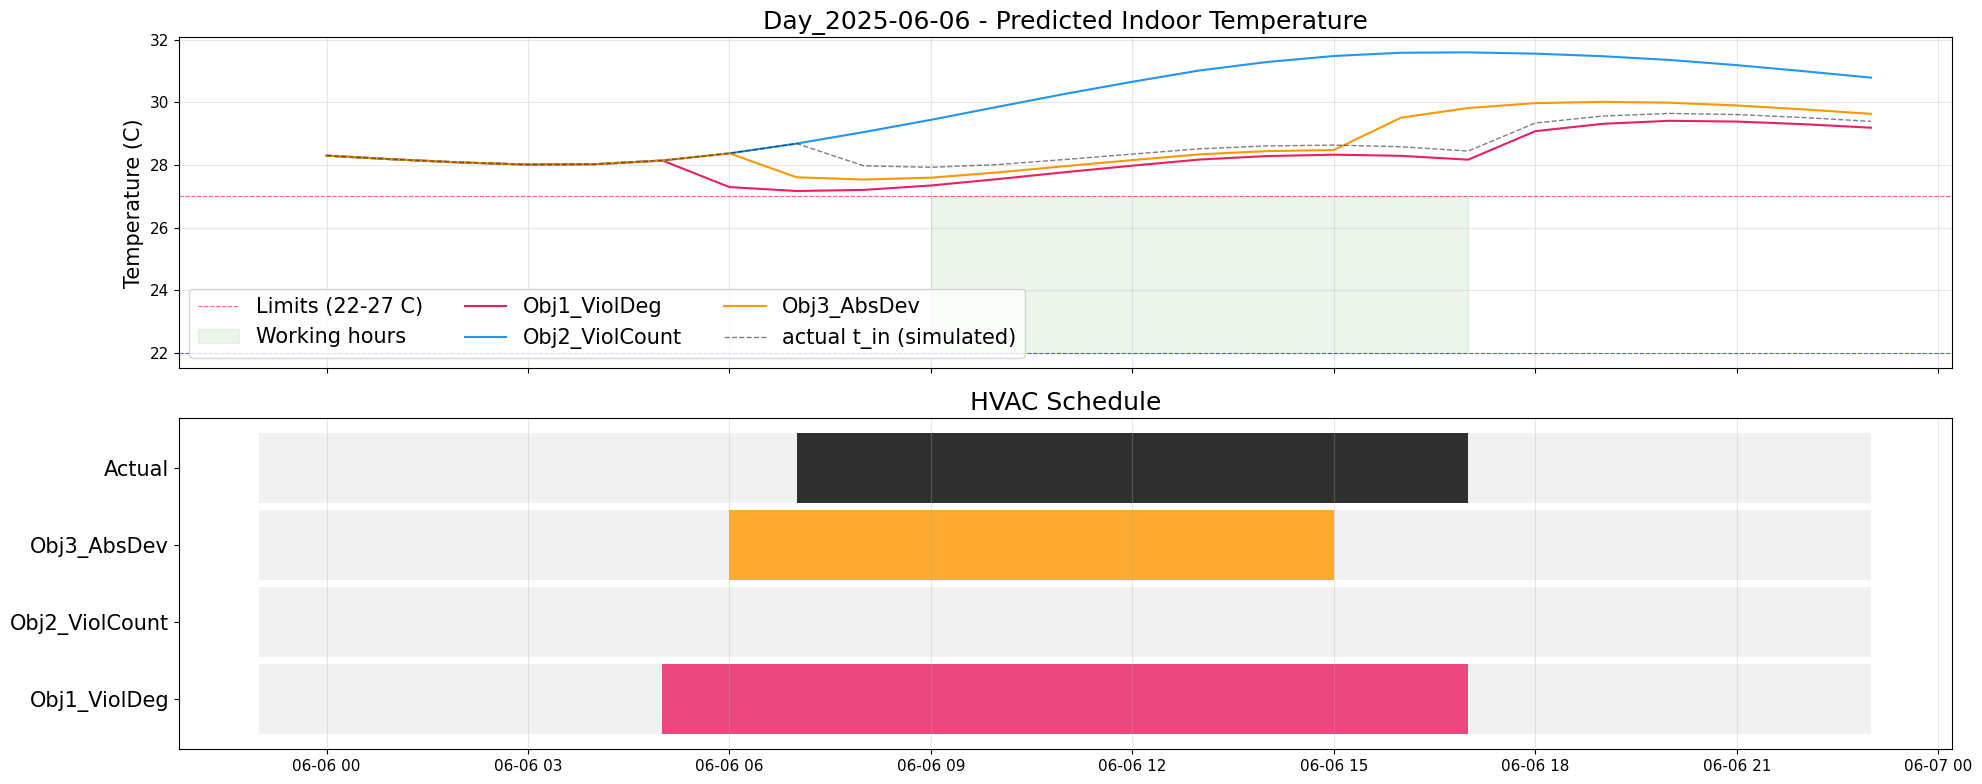

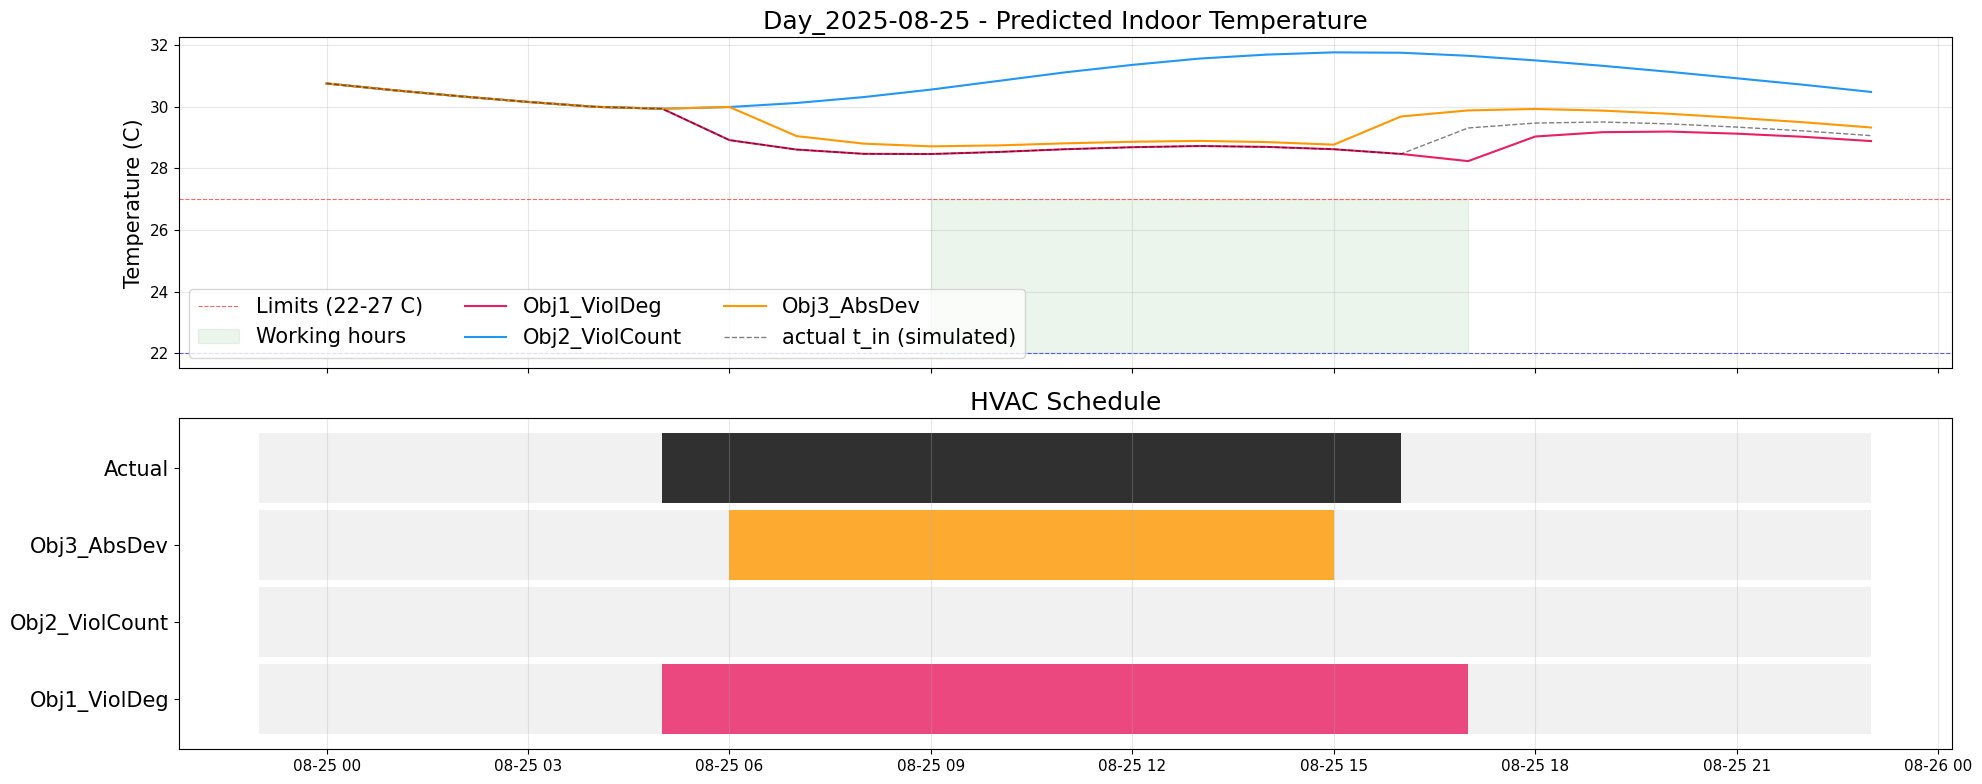

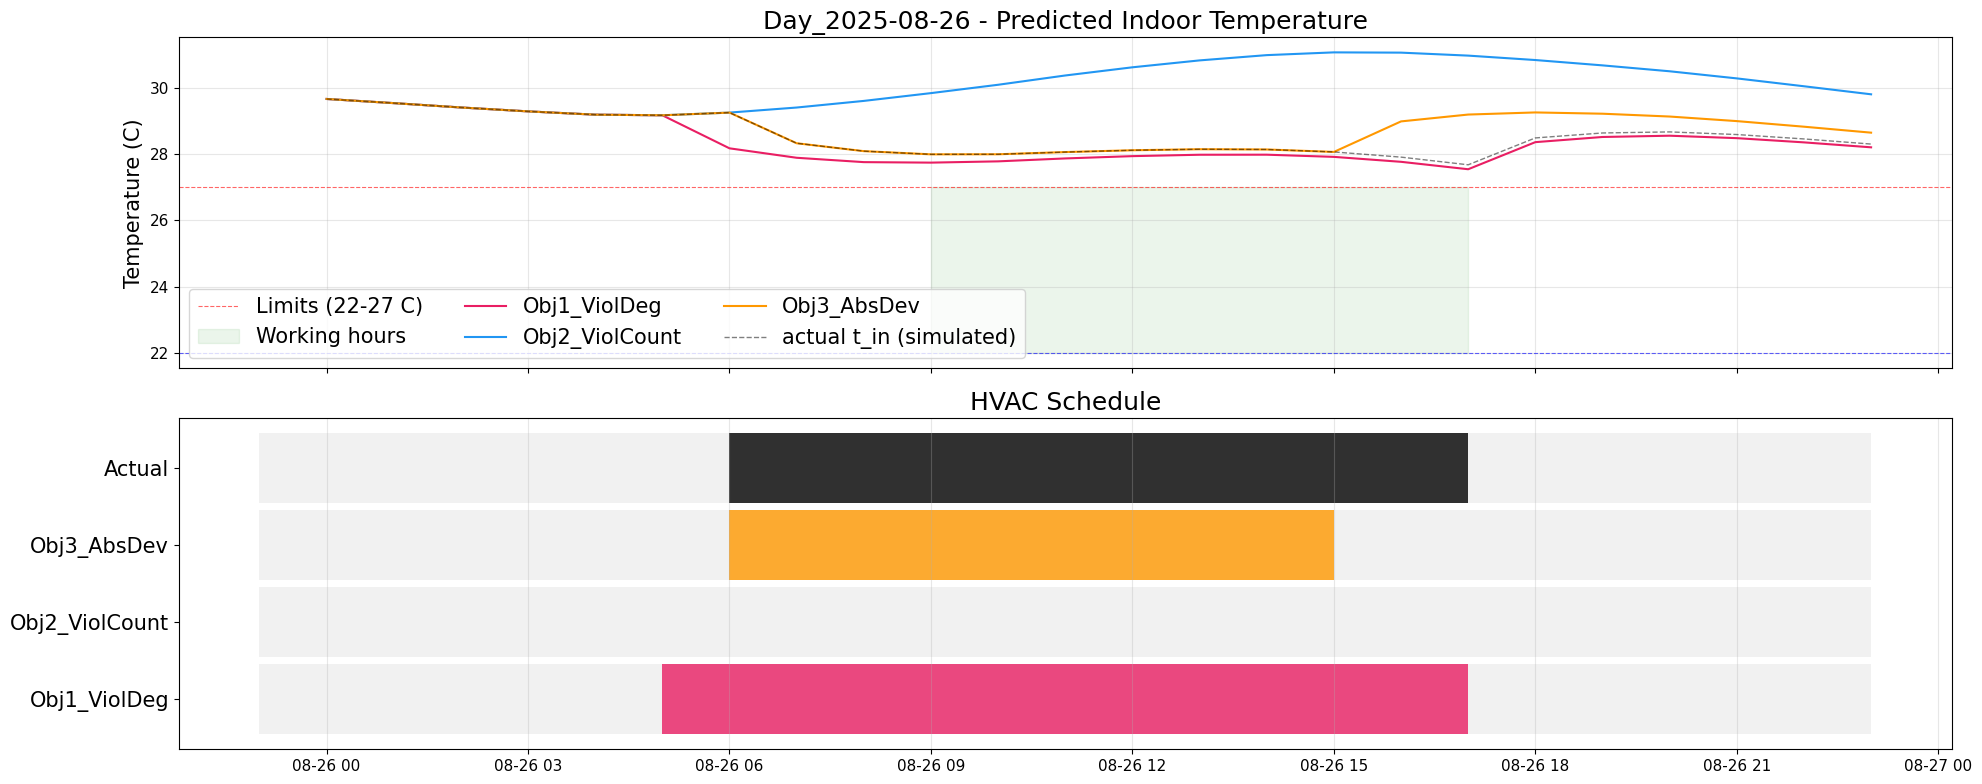

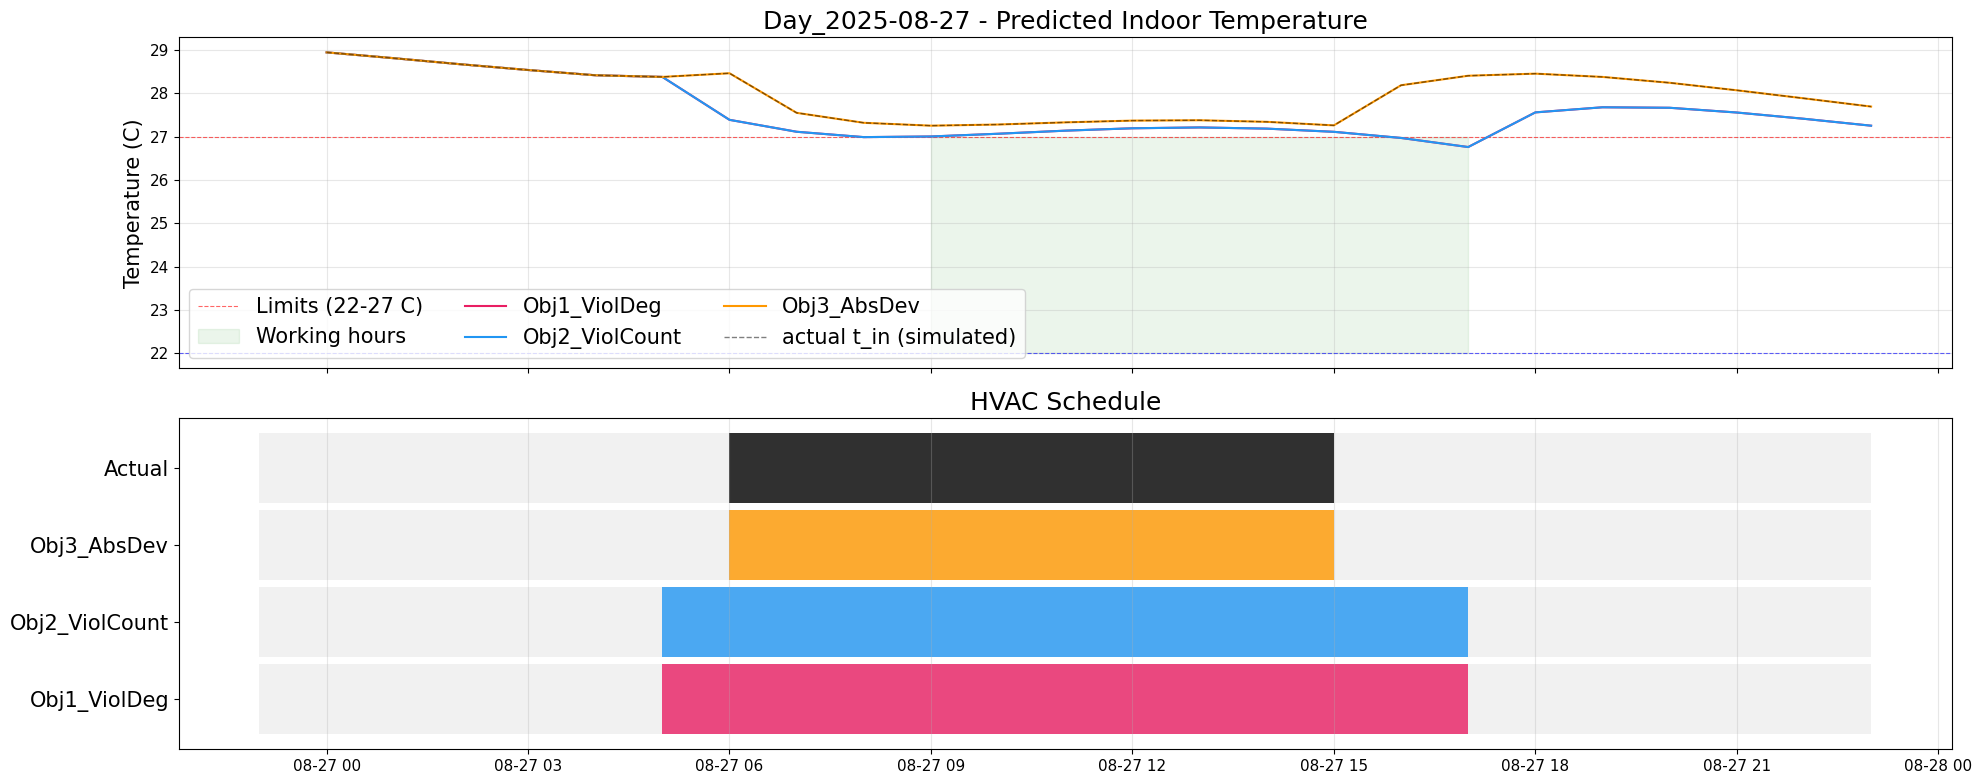

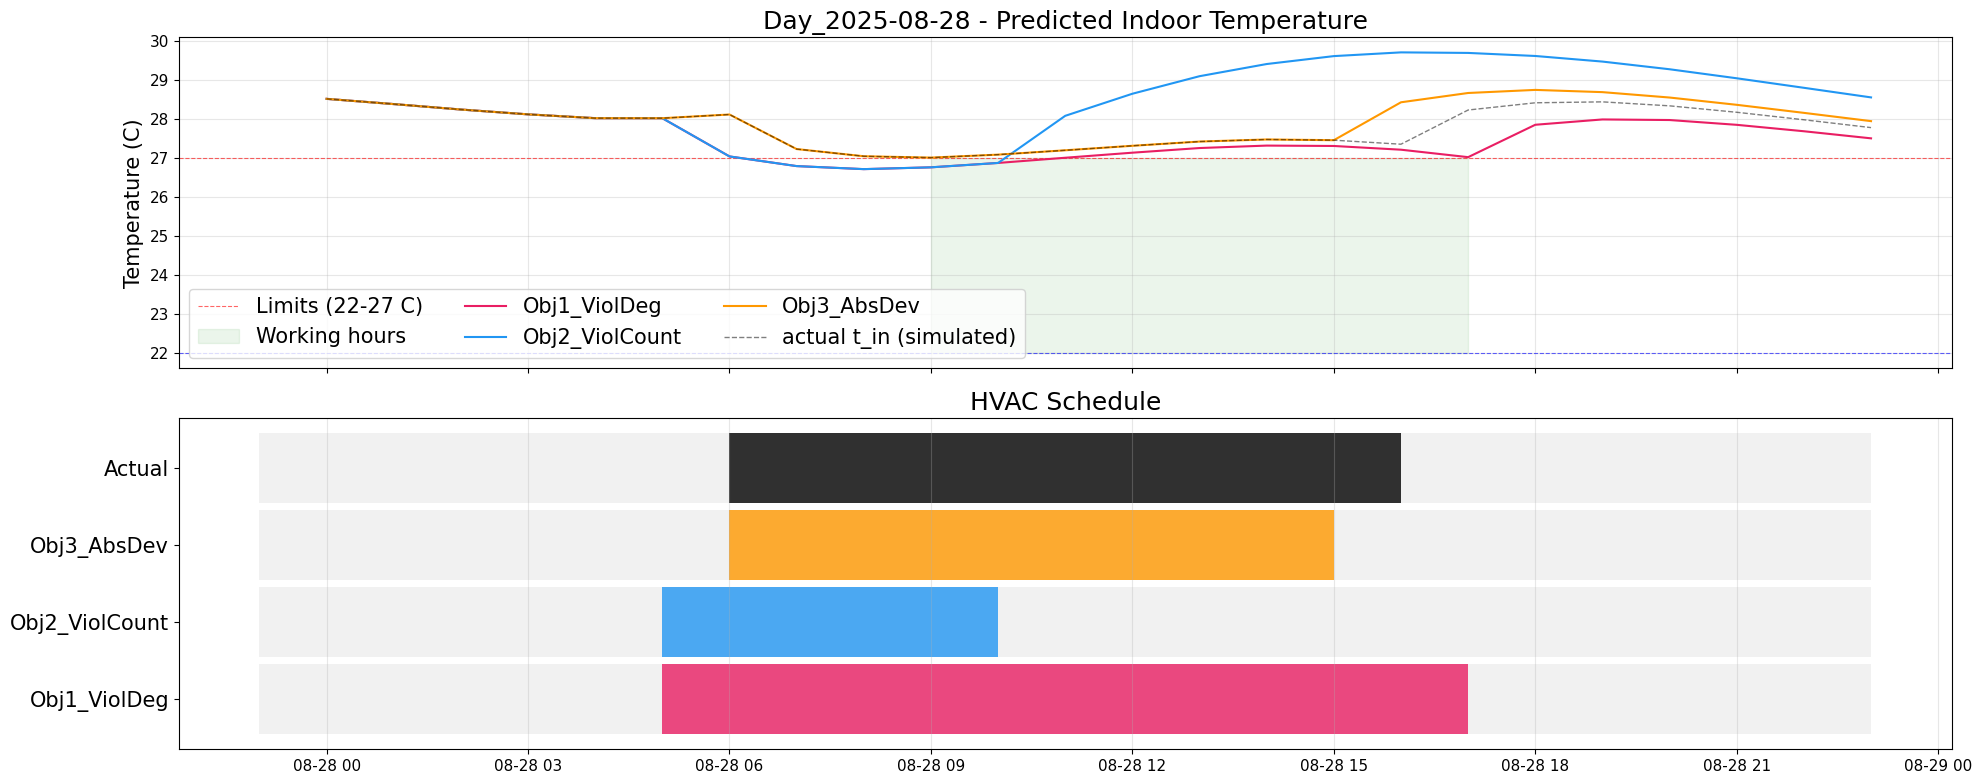

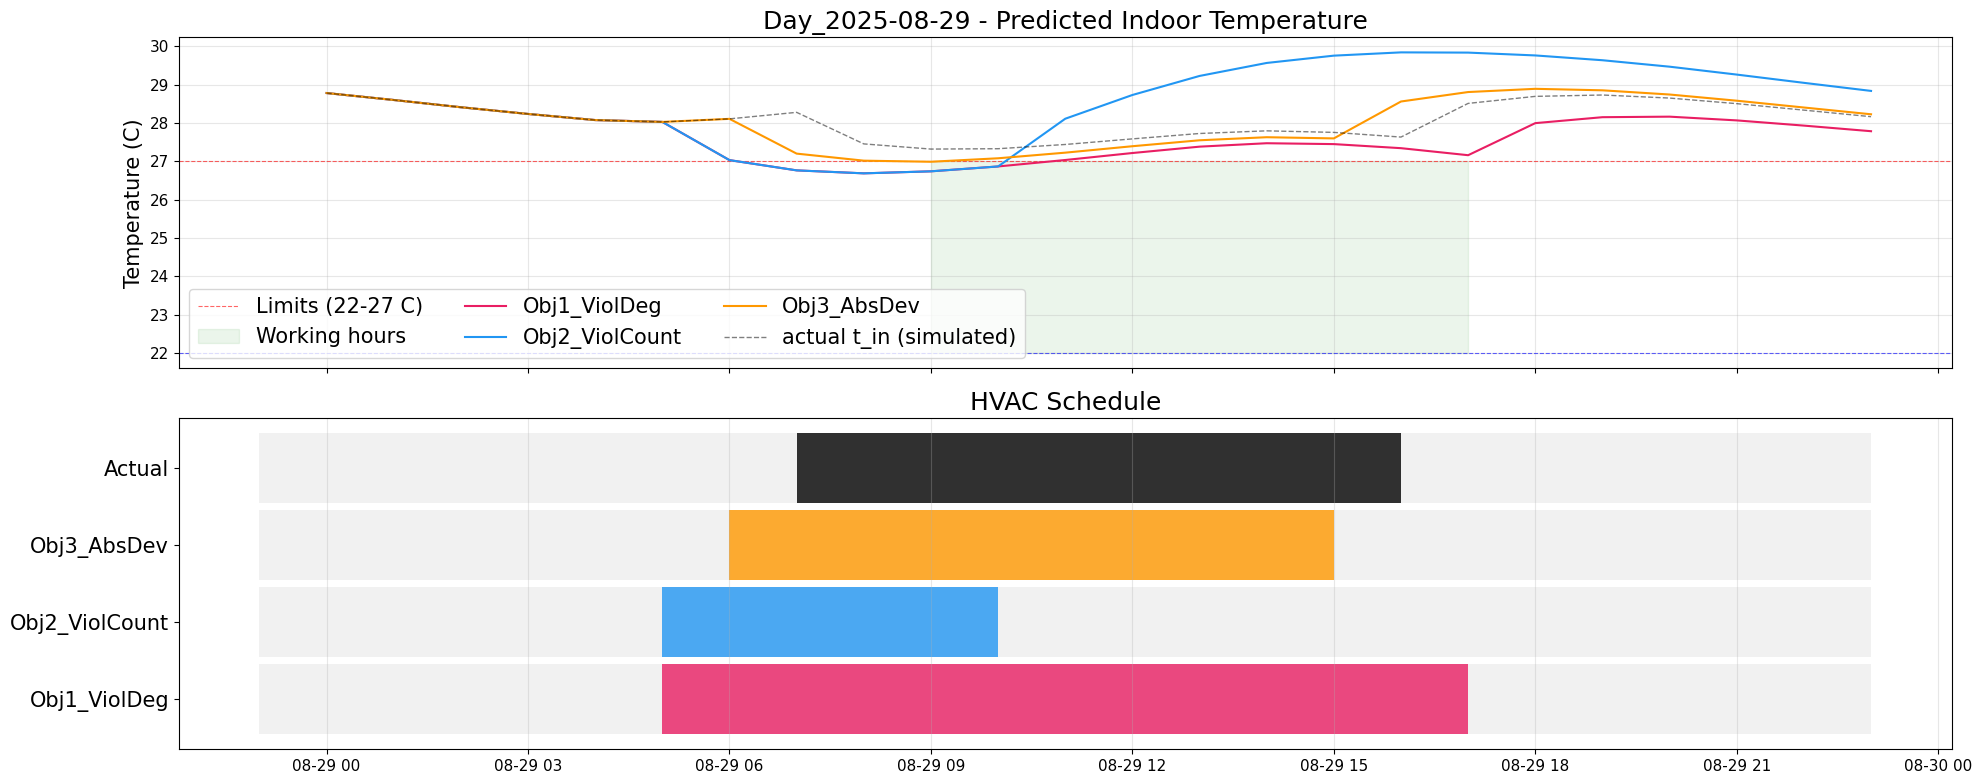

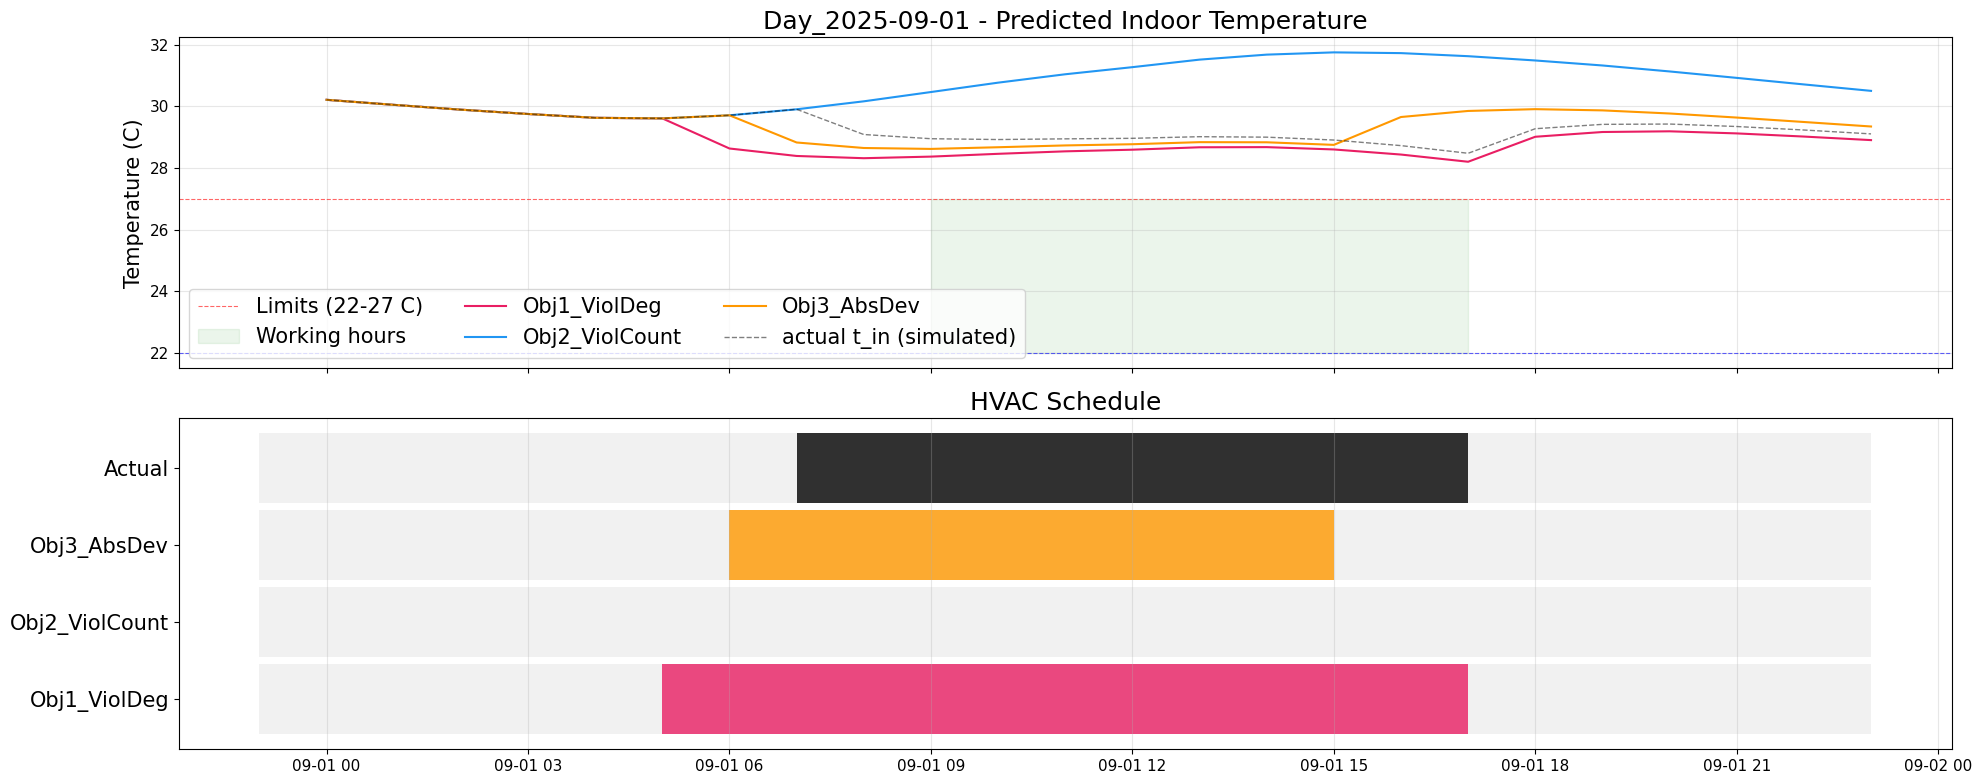

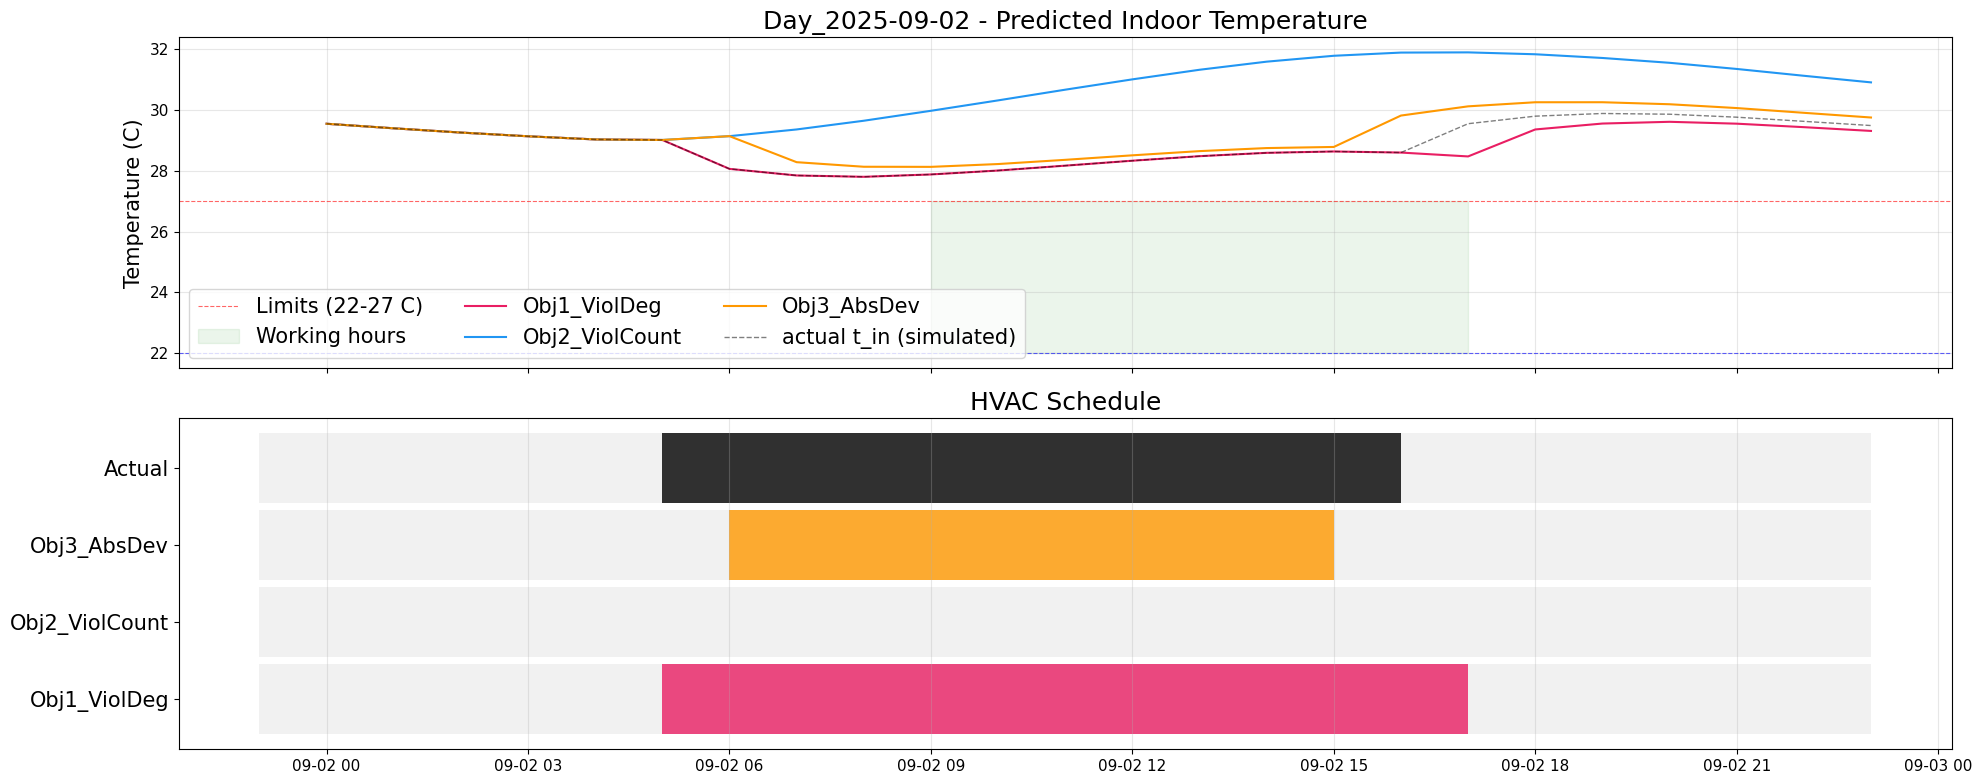

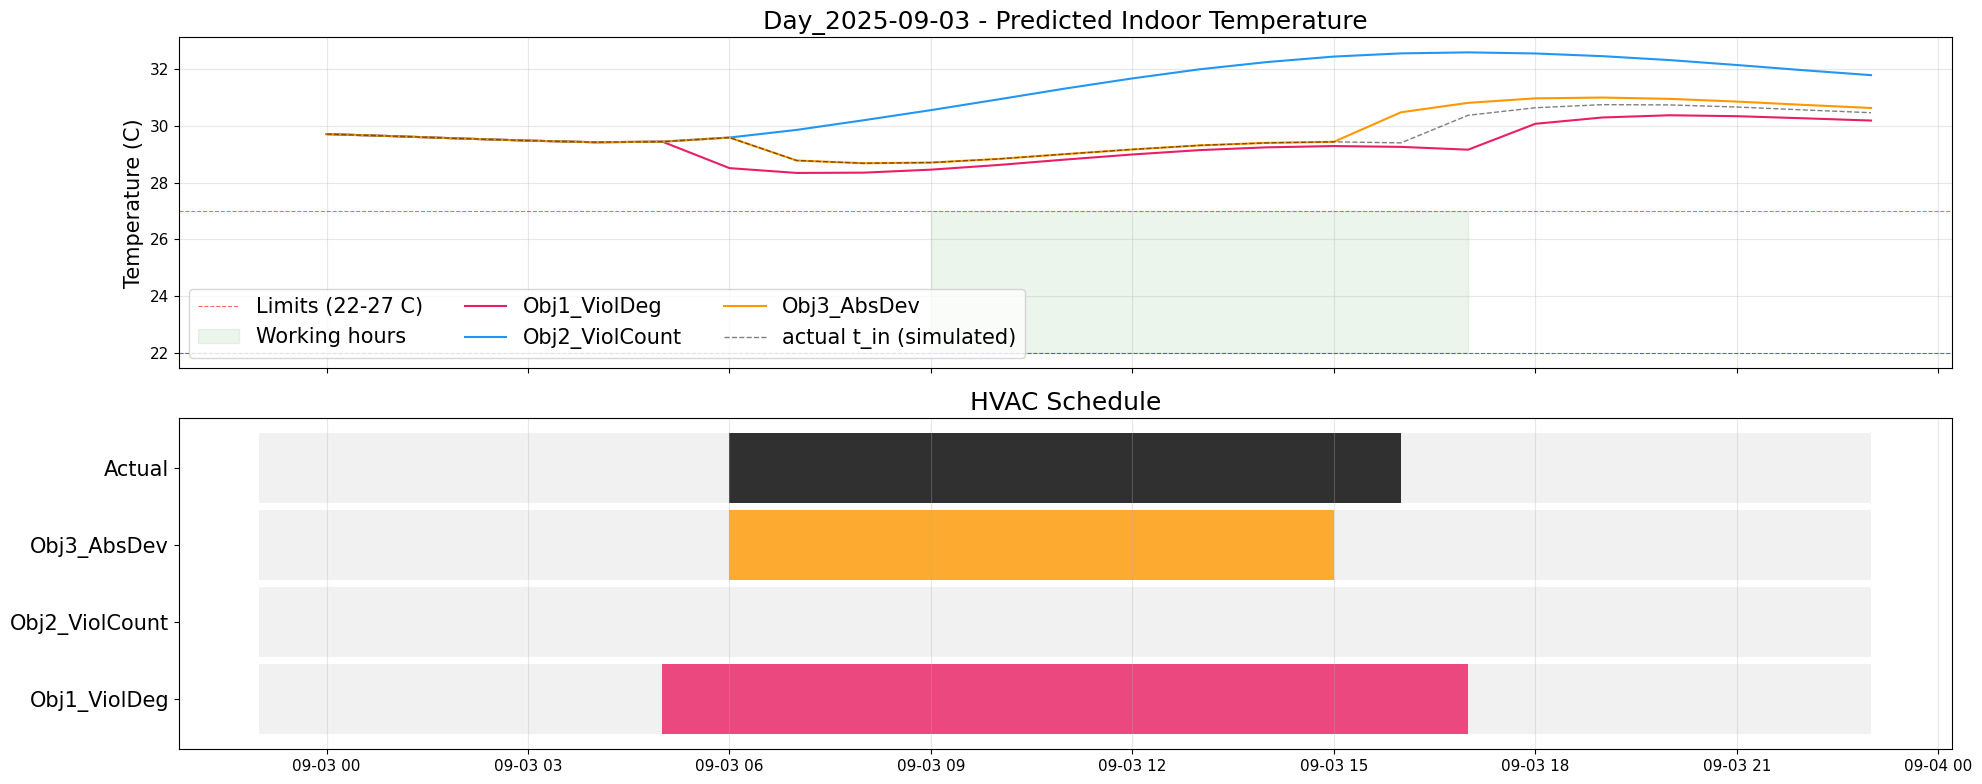

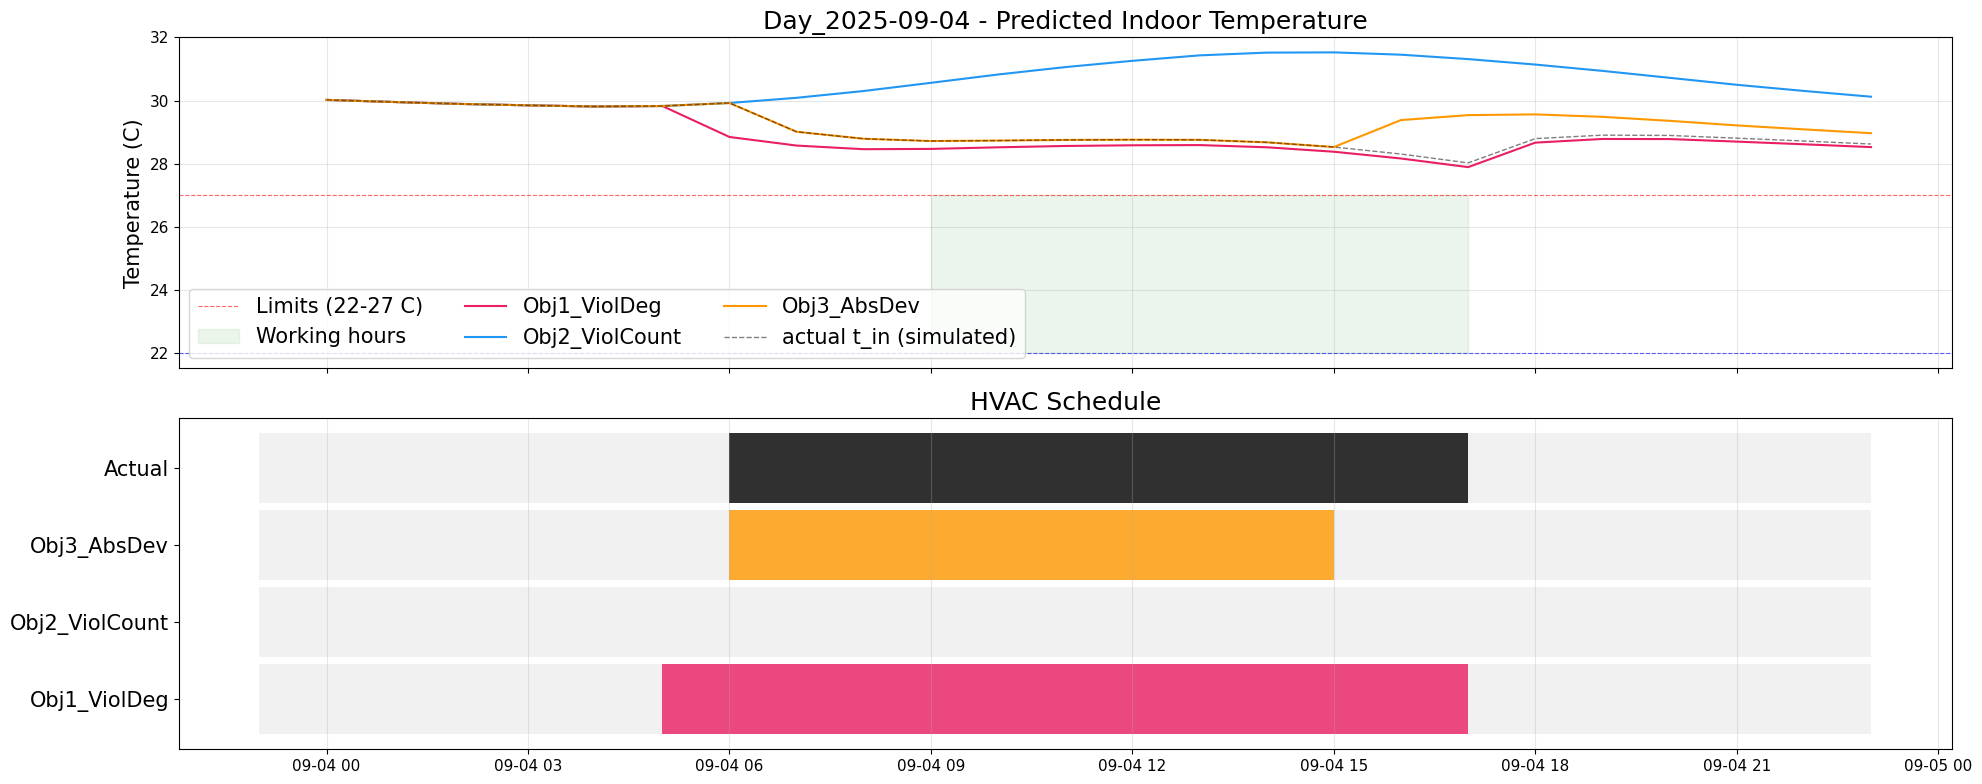

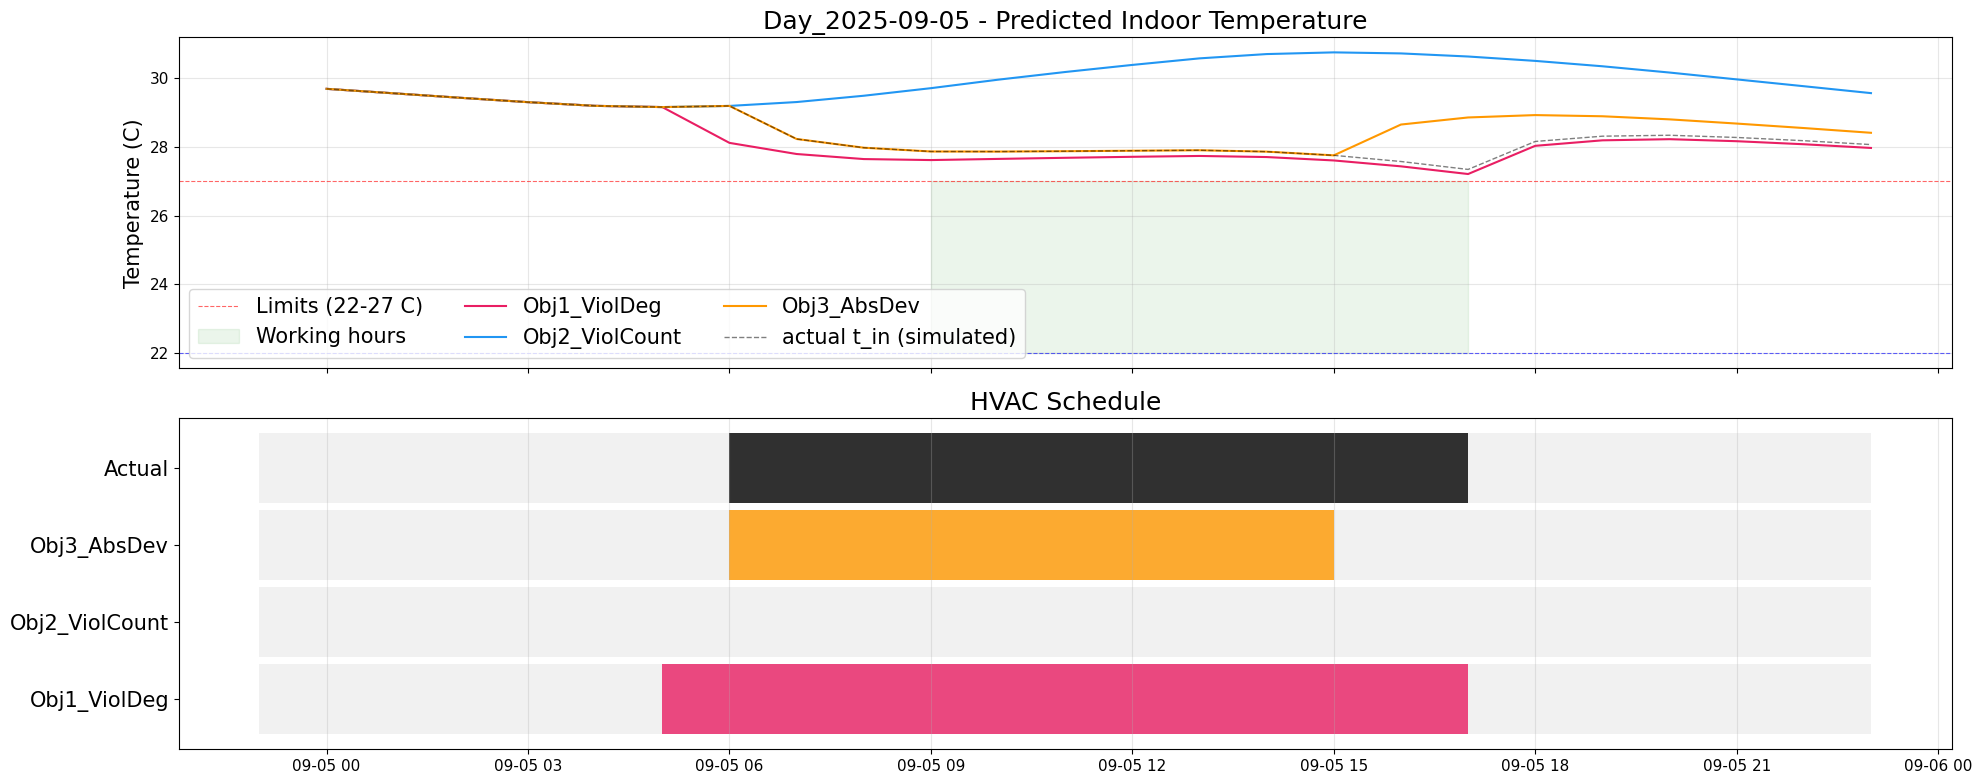

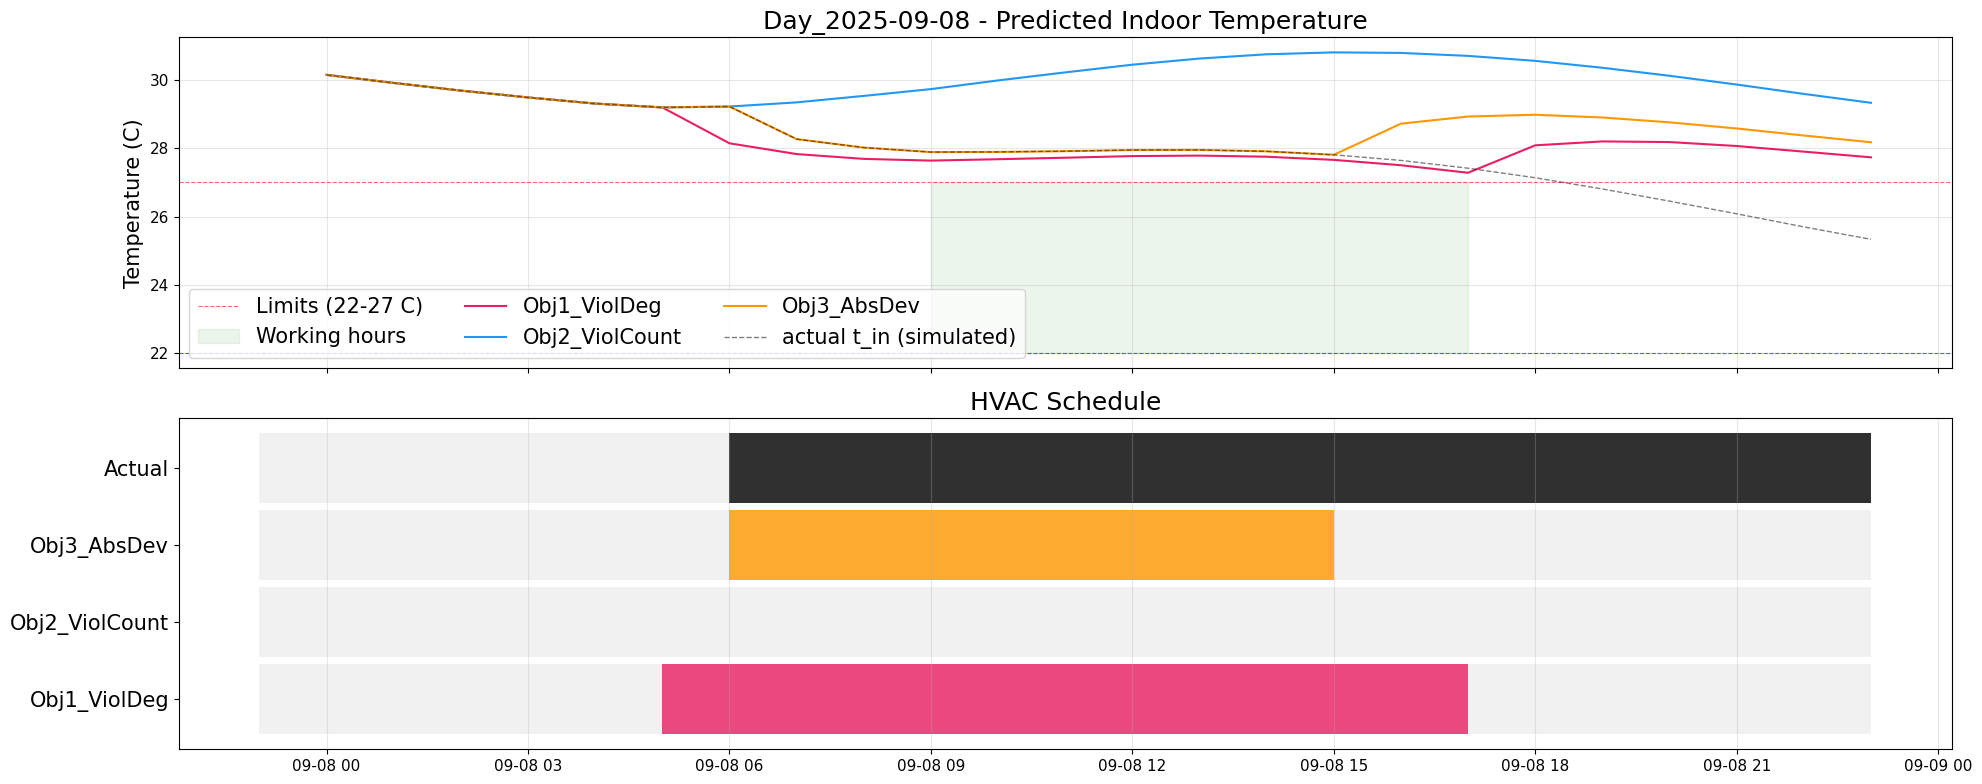

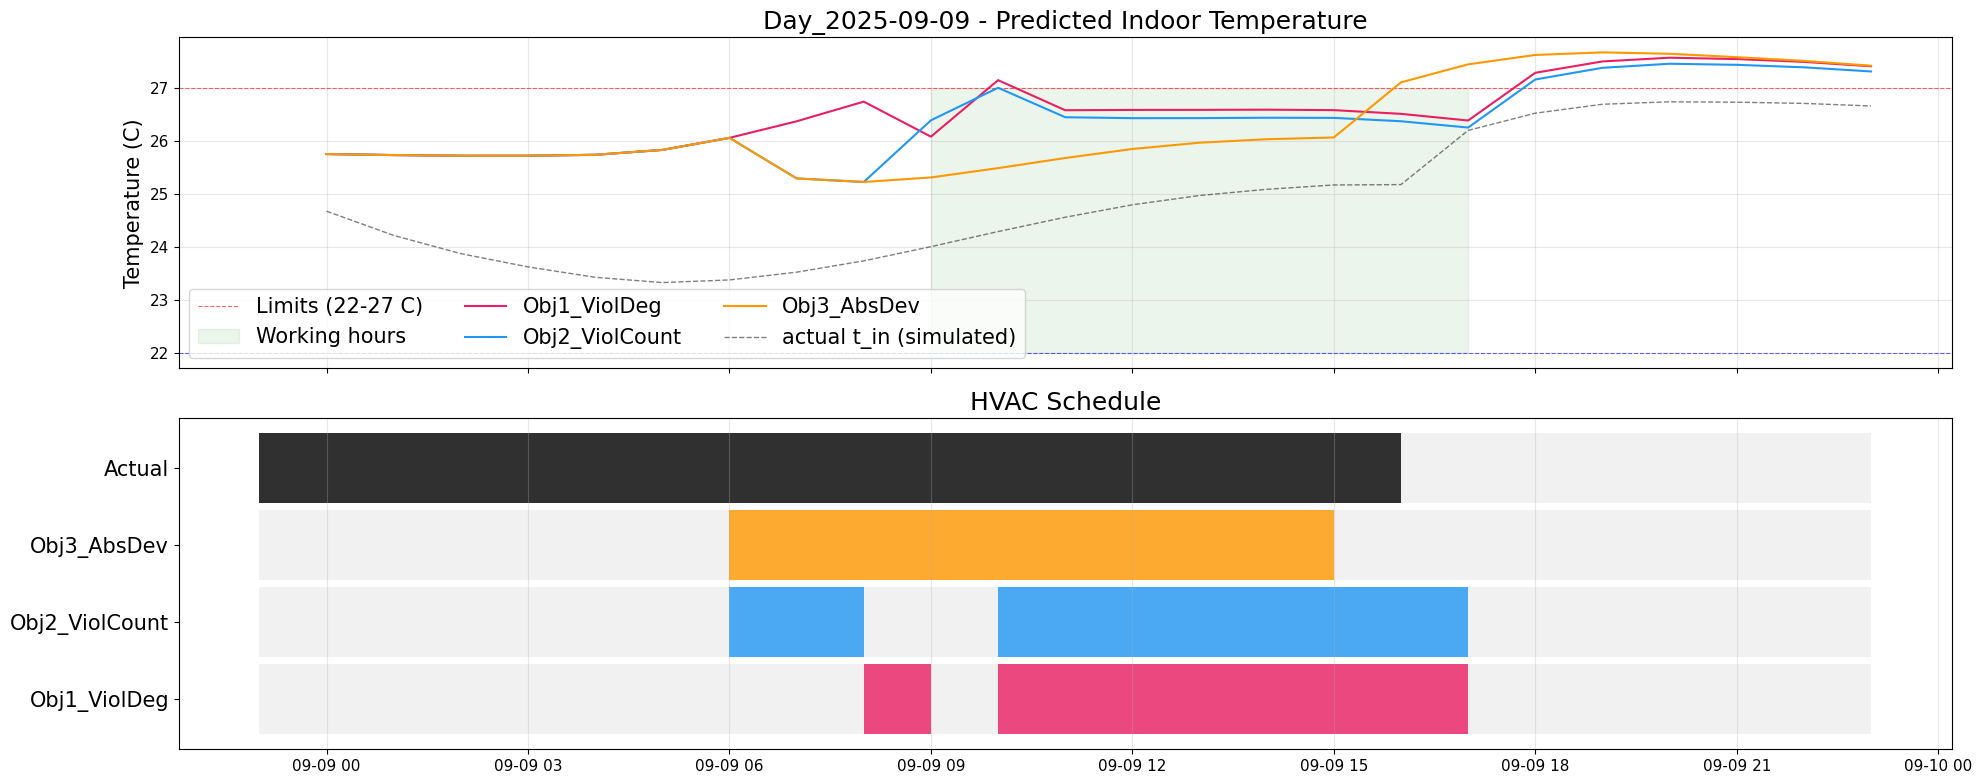

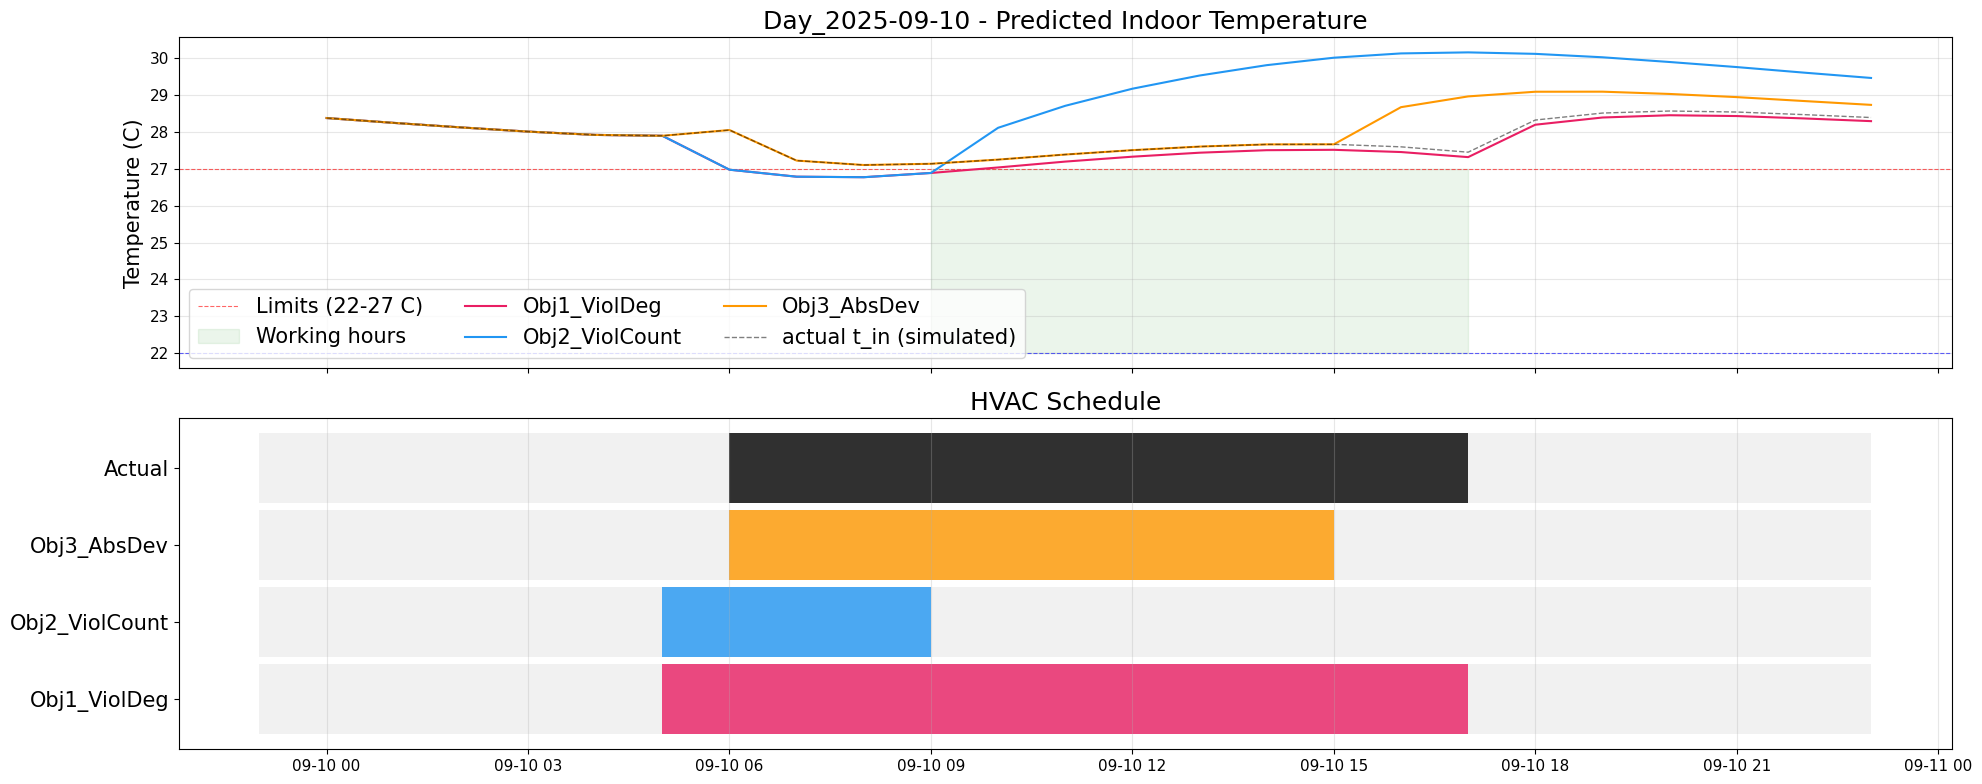

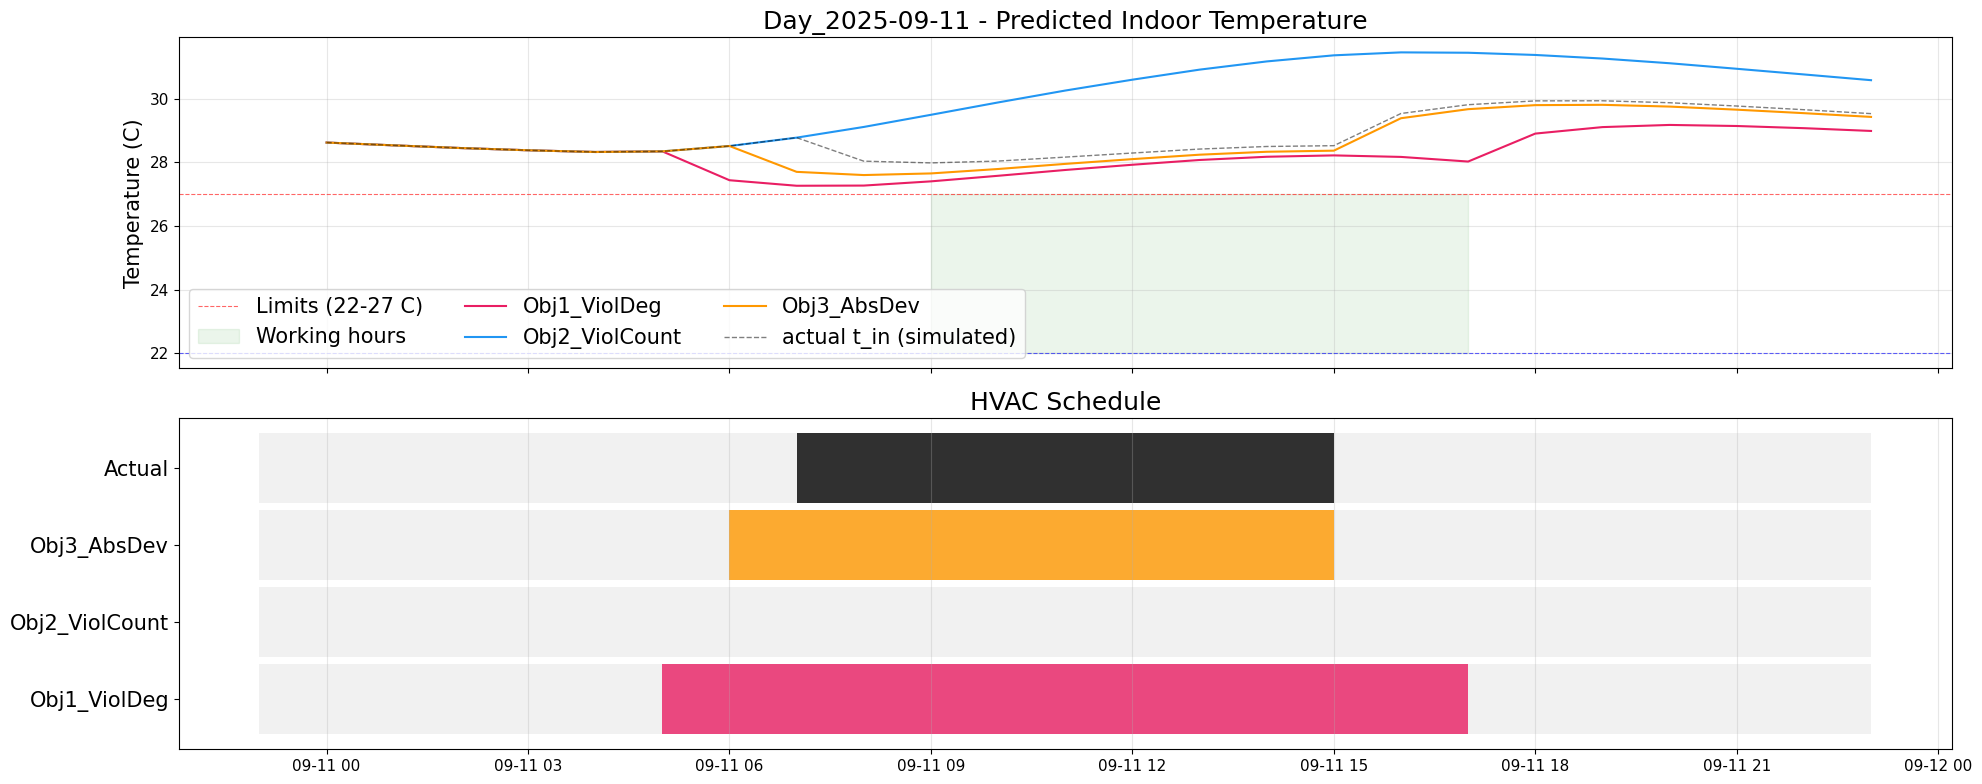

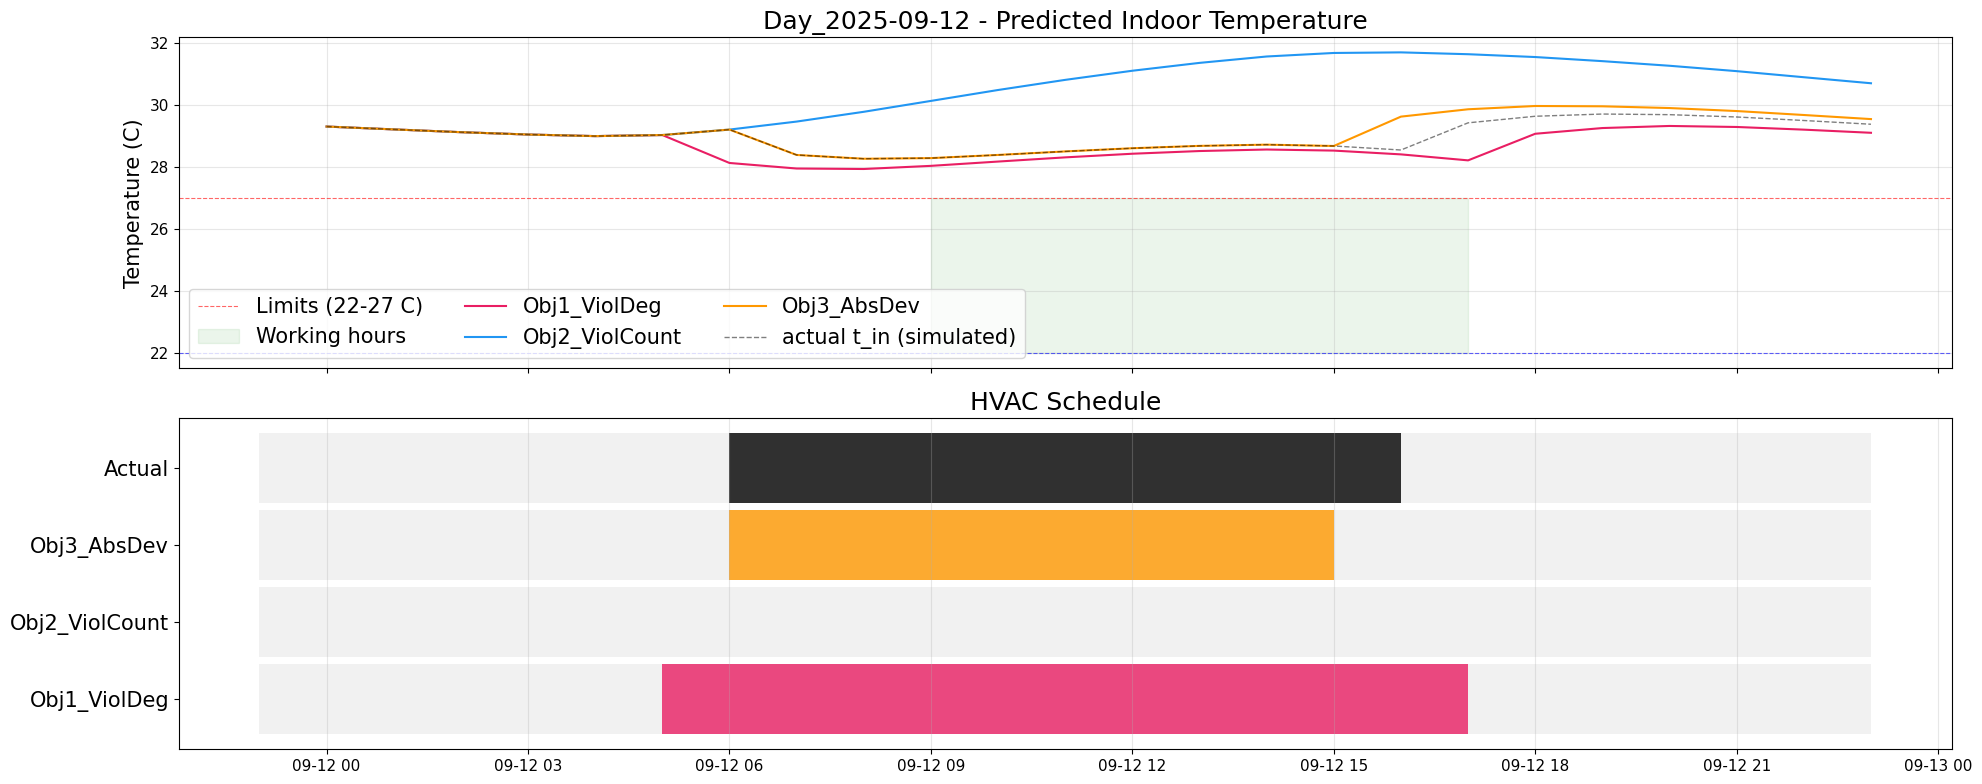

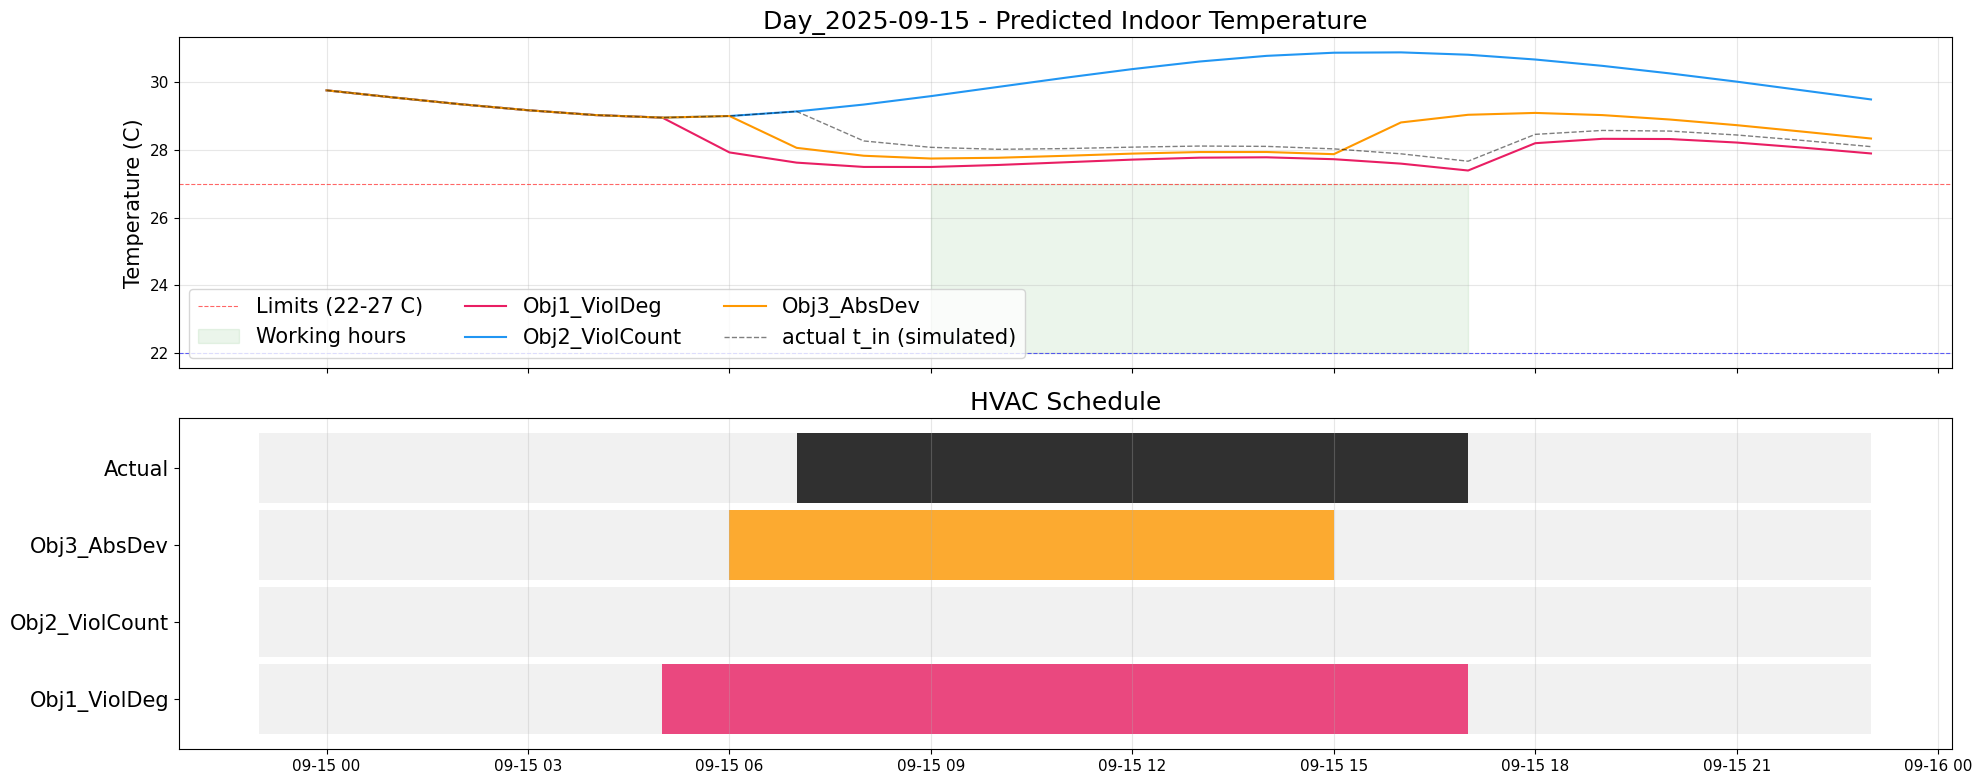

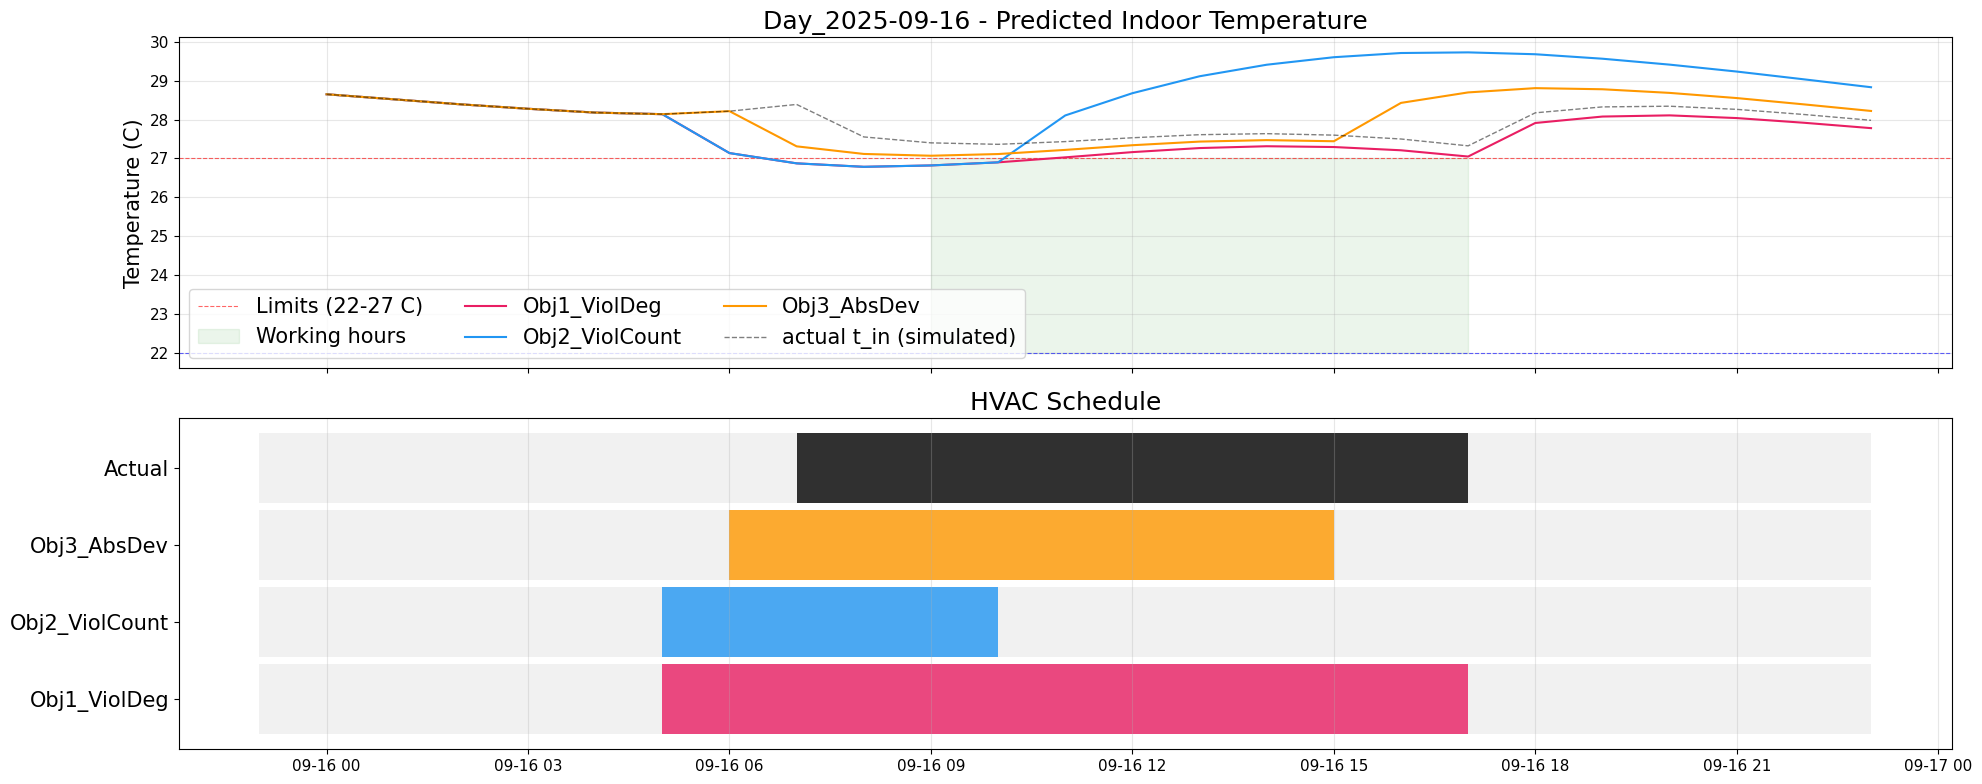

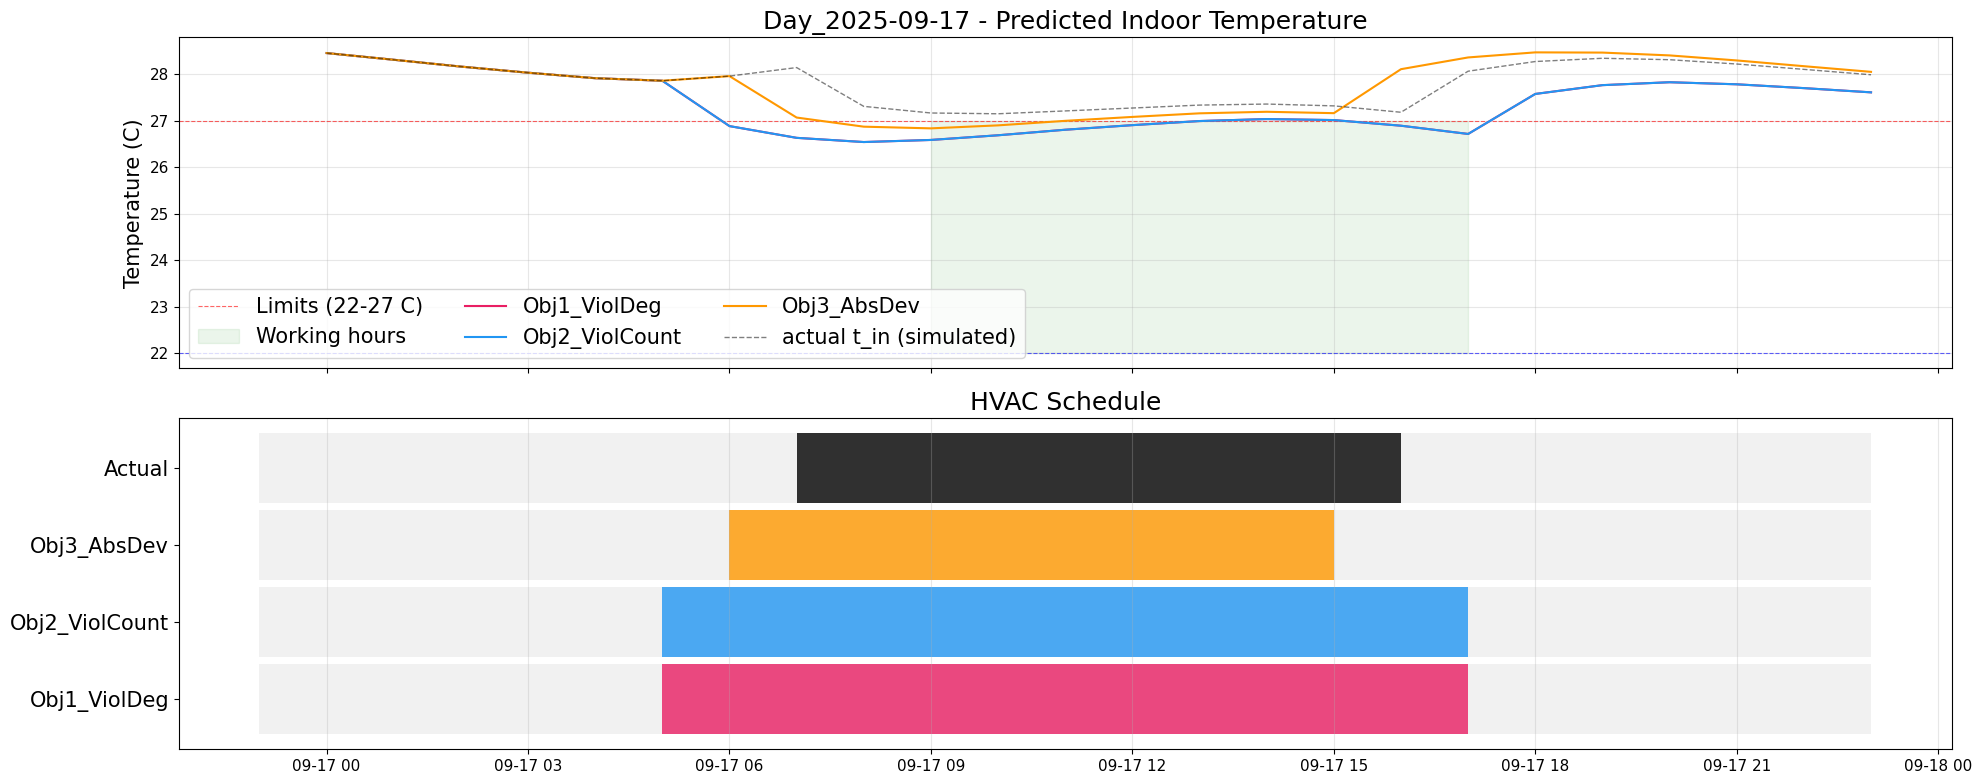

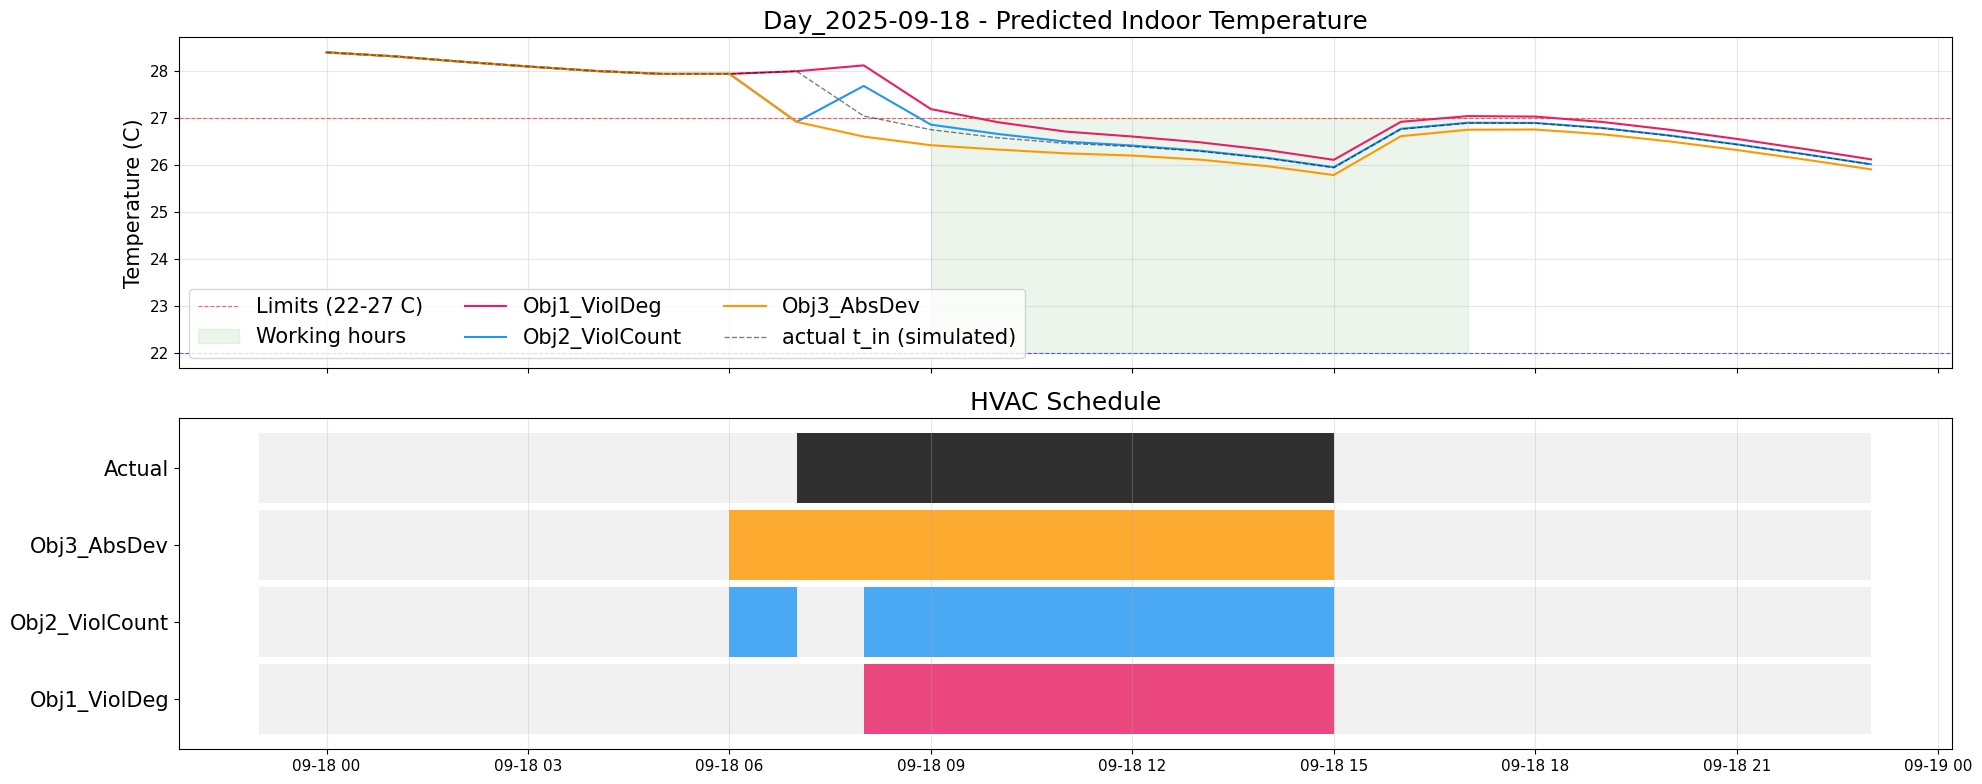

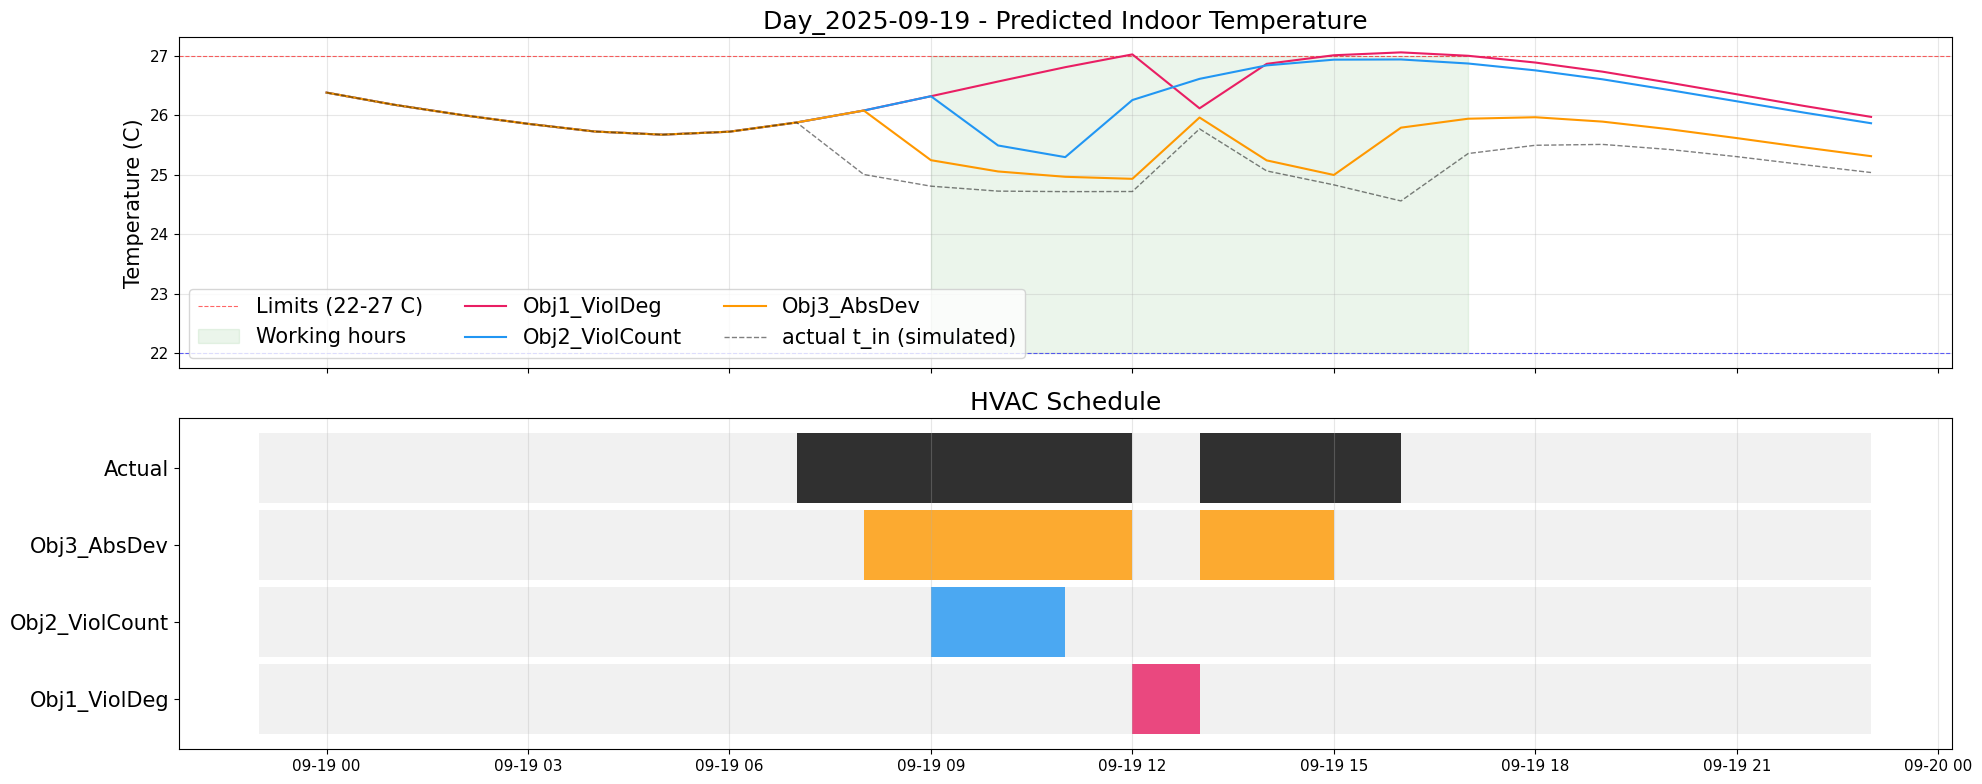

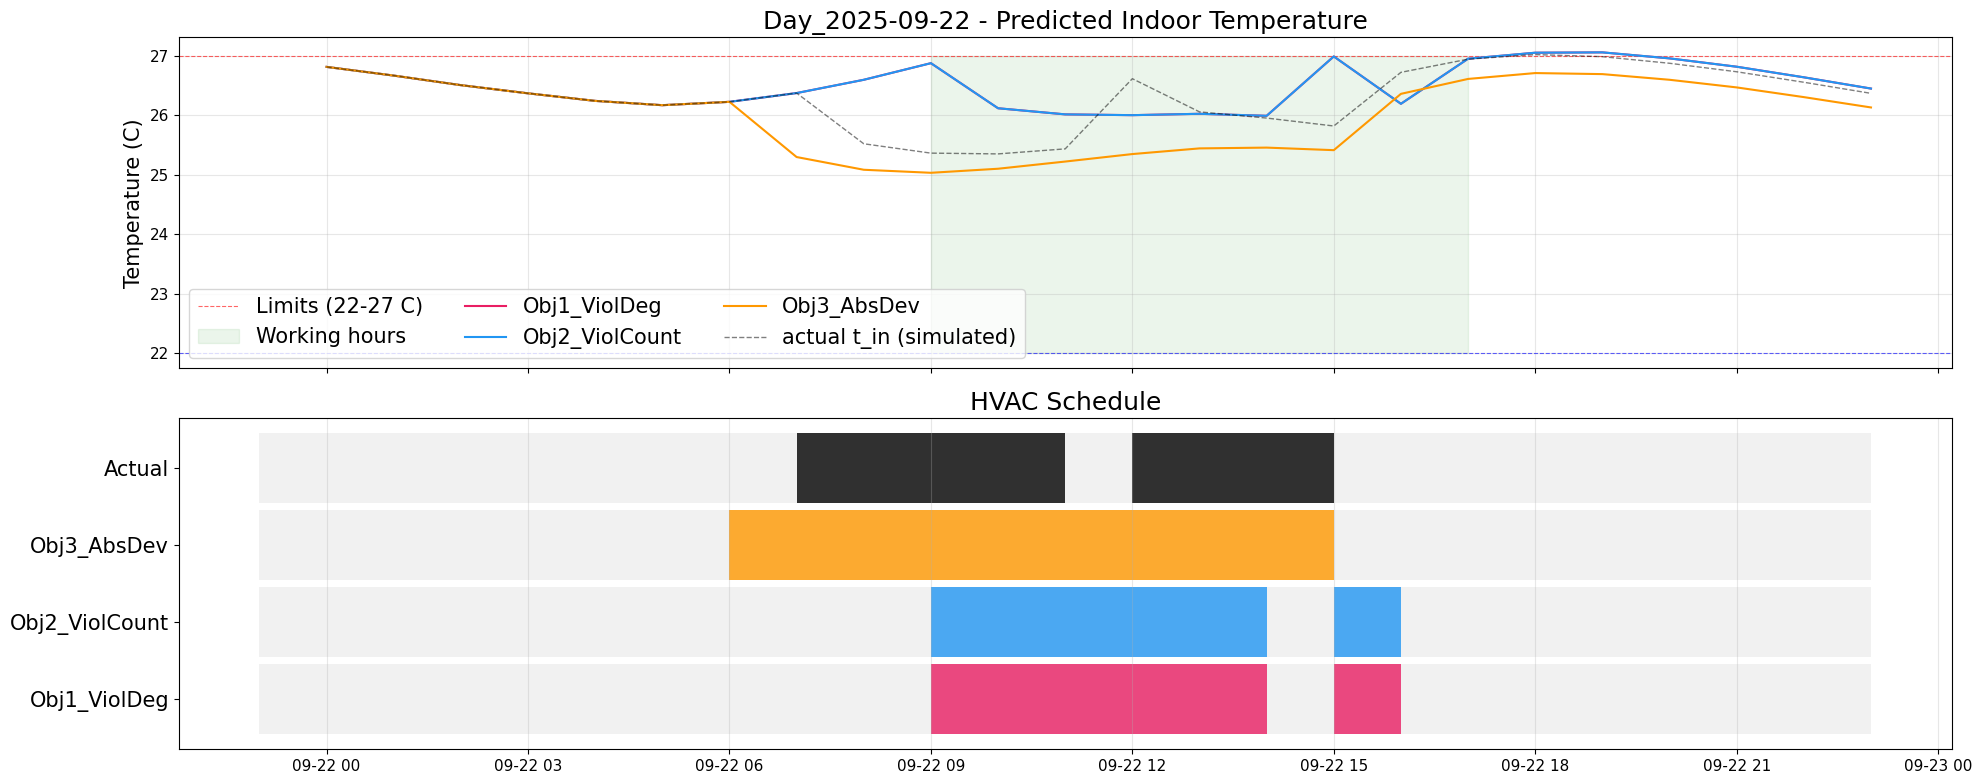

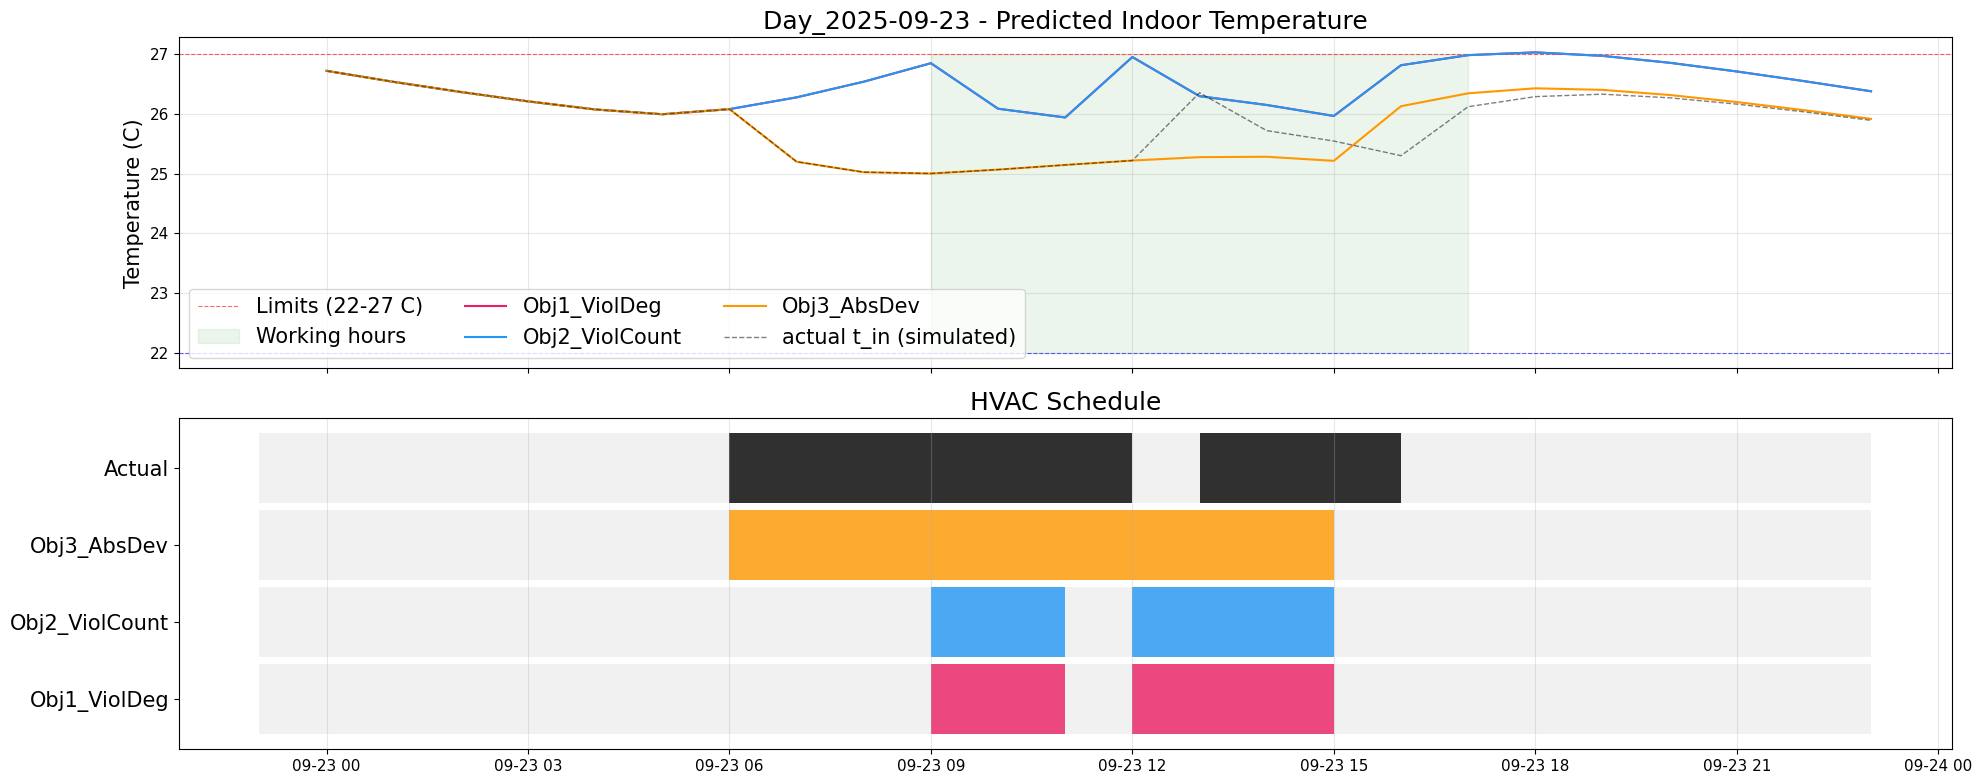

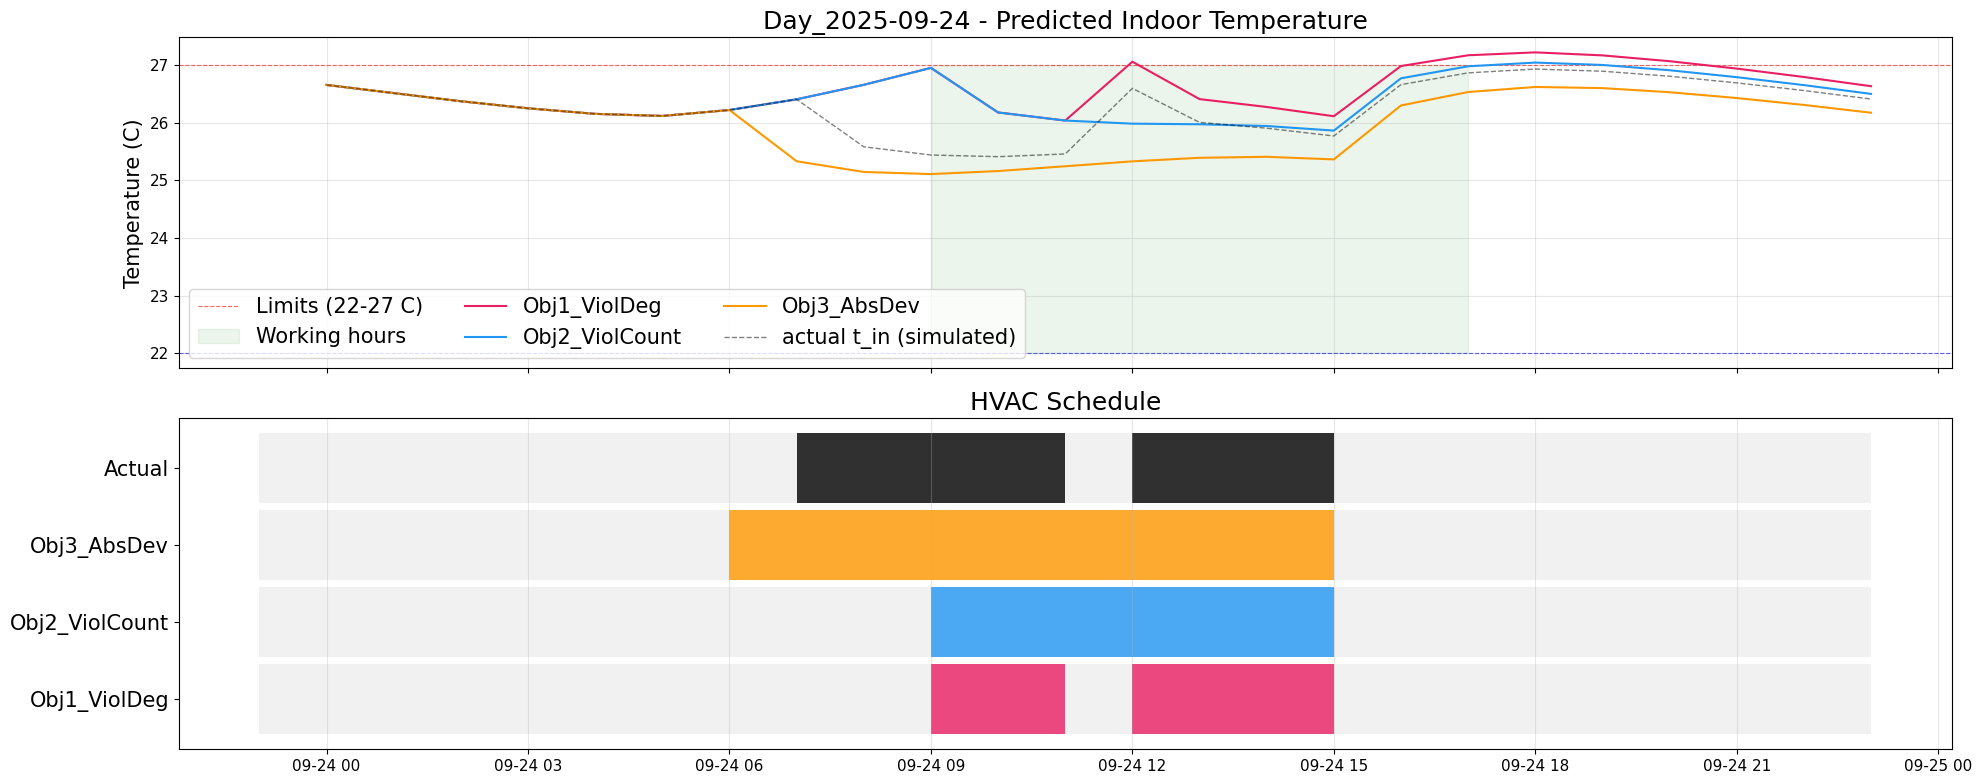

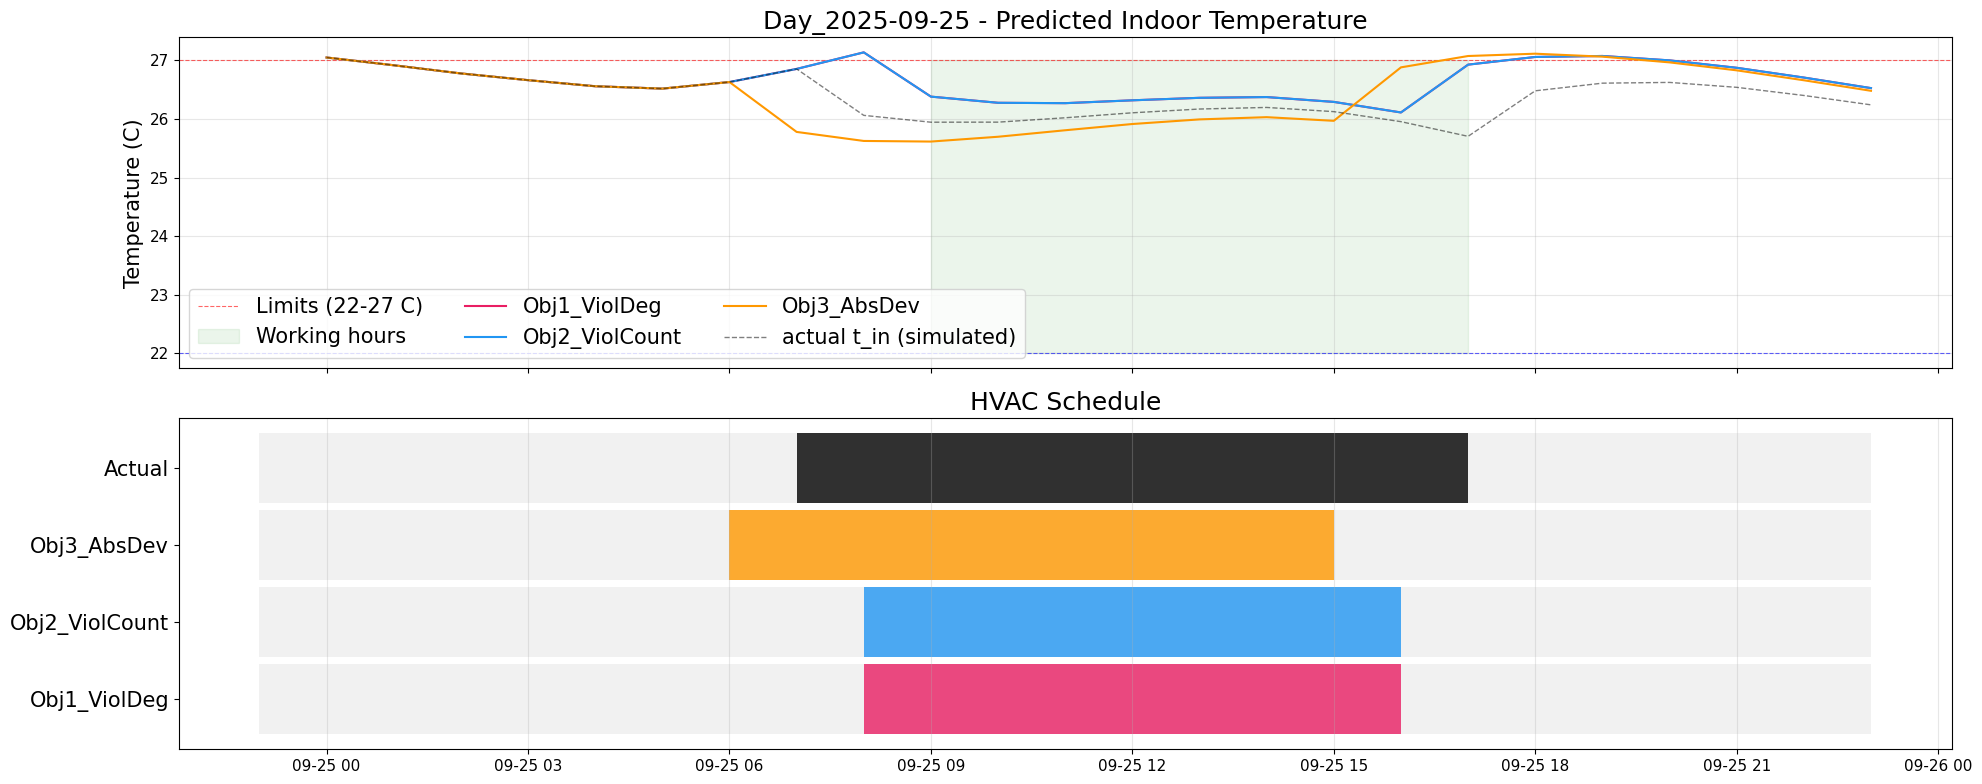

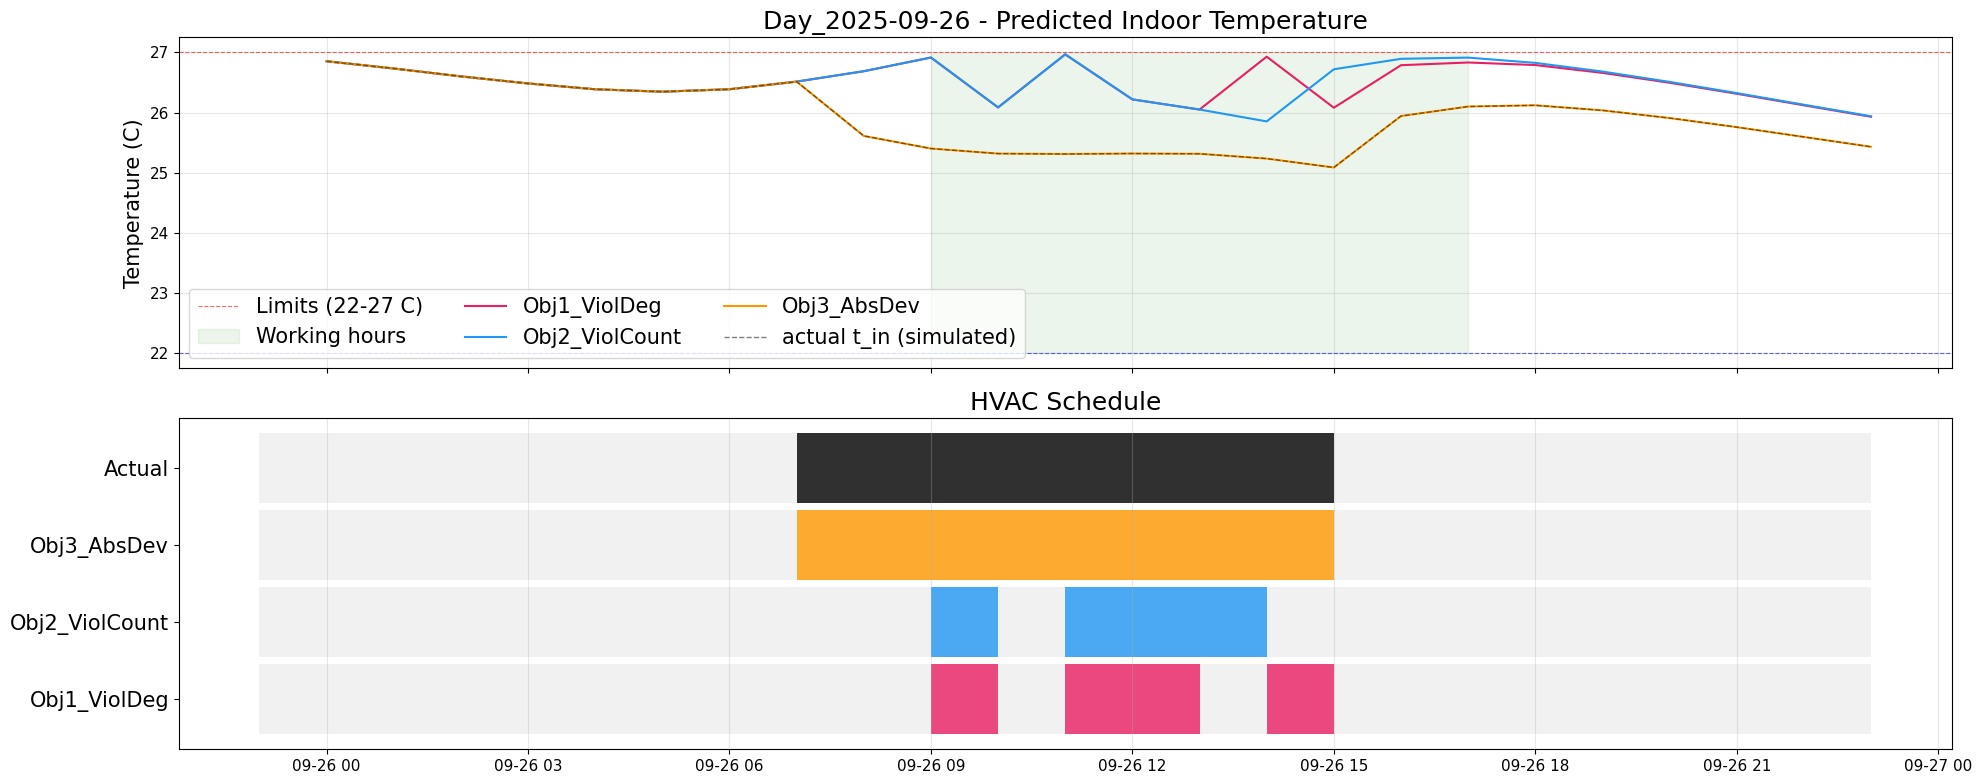

In [70]:
import matplotlib.dates as mdates

METHOD_COLORS = {
    'Obj1_ViolDeg':   '#E91E63',
    'Obj2_ViolCount': '#2196F3',
    'Obj3_AbsDev':    '#FF9800',
}

for label, df in all_session_results.items():
    fig, (ax_temp, ax_sched) = plt.subplots(2, 1, figsize=(20, 8), sharex=True)

    ax_temp.axhline(UPPER_LIMIT, color='red',  linestyle='--', lw=0.8, alpha=0.6, label=f'Limits ({LOWER_LIMIT}-{UPPER_LIMIT} C)')
    ax_temp.axhline(LOWER_LIMIT, color='blue', linestyle='--', lw=0.8, alpha=0.6)
    ax_temp.fill_between(df.index, LOWER_LIMIT, UPPER_LIMIT, where=df['is_working_hours'],
                         color='green', alpha=0.08, label='Working hours')

    for name, _ in METHODS:
        col = f'{name}_t_in_pred'
        if col in df and df[col].notna().any():
            ax_temp.plot(df.index, df[col], lw=1.5, color=METHOD_COLORS[name], label=name)

    ax_temp.plot(df.index, df['actual_t_in_simulated'], 'k--', lw=1, alpha=0.5, label='actual t_in (simulated)')

    ax_temp.set_ylabel('Temperature (C)', fontsize=15)
    ax_temp.set_title(f'{label} - Predicted Indoor Temperature', fontsize=18)
    ax_temp.legend(fontsize=15, ncol=3, loc='lower left')
    ax_temp.tick_params(axis='both', labelsize=11)
    ax_temp.grid(alpha=0.3)

    offsets = {name: i * 1.1 for i, (name, _) in enumerate(METHODS)}
    offsets['Actual'] = len(METHODS) * 1.1

    def draw_schedule_row(ax, idx, on_mask, y_off, color, row_label):
        """
        Draw one HVAC row as independent 1-hour-wide bars (broken_barh). A mark at
        timestamp t represents the hour ENDING at t, so each bar spans [t - 1h, t].
        """
        hour_width = 1.0 / 24.0
        day_start  = mdates.date2num(idx[0]) - hour_width
        day_end    = mdates.date2num(idx[-1])
        ax.broken_barh([(day_start, day_end - day_start)], (y_off, 1.0),
                        facecolors='lightgrey', alpha=0.3)

        on_starts = mdates.date2num(idx[on_mask]) - hour_width
        if len(on_starts) > 0:
            ax.broken_barh([(s, hour_width) for s in on_starts], (y_off, 1.0),
                            facecolors=color, alpha=0.8, label=row_label)

    for name, _ in METHODS:
        col = f'{name}_schedule'
        if col in df and df[col].notna().any():
            on_mask = (df[col].fillna(0) > 0).values
            draw_schedule_row(ax_sched, df.index, on_mask, offsets[name], METHOD_COLORS[name], name)

    actual_on_mask = (df['actual_cooling_mode'].fillna(0) > 0).values
    draw_schedule_row(ax_sched, df.index, actual_on_mask, offsets['Actual'], 'black', 'Actual')

    ax_sched.set_yticks([v + 0.5 for v in offsets.values()])
    ax_sched.set_yticklabels(list(offsets.keys()), fontsize=15)
    ax_sched.set_title('HVAC Schedule', fontsize=18)
    ax_sched.tick_params(axis='x', labelsize=11)
    ax_sched.grid(axis='x', alpha=0.3)

    plt.tight_layout()
    plt.show()


## Cross-Run Summary Table

In [71]:
rows = []
for label, df in all_session_results.items():
    for name, _ in METHODS:
        sched = df.get(f'{name}_schedule')
        if sched is None or sched.isna().all():
            continue
        row = {'Session': label, 'Method': name}
        row.update(compute_method_metrics(df, name, label))
        rows.append(row)

    actual_row = {'Session': label, 'Method': 'Actual'}
    actual_row.update(compute_method_metrics(
        df, 'Actual', label,
        schedule_col='actual_cooling_mode', temp_col='actual_t_in',
        real_consumption=df['actual_consumption'].sum(),
    ))
    rows.append(actual_row)

summary_df = pd.DataFrame(rows)

for metric_name in ['HVAC Hours', 'Switches', 'Avg T_in (work)', 'Max T_in (work)', 'Comfort Violation Hours',
                     'Avg Discomfort (all work hrs)', 'Avg Discomfort (violated hrs)', 'Avg PMV (work)',
                     'Energy Proxy (Wh)', 'Objective Cost', 'Runtime (s)']:
    print(f"\n=== {metric_name} by Method & Session ===")
    display(summary_df.pivot(index='Session', columns='Method', values=metric_name))



=== HVAC Hours by Method & Session ===


Method,Actual,Obj1_ViolDeg,Obj2_ViolCount,Obj3_AbsDev
Session,,,,
Day_2025-05-05,0,0,0,0
Day_2025-05-06,1,0,0,3
Day_2025-05-07,3,0,0,3
Day_2025-05-08,1,3,3,6
Day_2025-05-09,7,4,4,7
Day_2025-05-19,1,0,0,0
Day_2025-05-20,0,0,0,2
Day_2025-05-21,10,1,1,4
Day_2025-05-22,6,3,3,6



=== Switches by Method & Session ===


Method,Actual,Obj1_ViolDeg,Obj2_ViolCount,Obj3_AbsDev
Session,,,,
Day_2025-05-05,0,0,0,0
Day_2025-05-06,2,0,0,4
Day_2025-05-07,2,0,0,6
Day_2025-05-08,2,2,2,2
Day_2025-05-09,4,6,4,2
Day_2025-05-19,2,0,0,0
Day_2025-05-20,0,0,0,4
Day_2025-05-21,2,2,2,4
Day_2025-05-22,4,4,4,2



=== Avg T_in (work) by Method & Session ===


Method,Actual,Obj1_ViolDeg,Obj2_ViolCount,Obj3_AbsDev
Session,,,,
Day_2025-05-05,24.78,25.19,25.19,25.19
Day_2025-05-06,26.01,26.16,26.16,25.42
Day_2025-05-07,25.62,26.27,26.27,25.51
Day_2025-05-08,26.51,26.35,26.35,25.46
Day_2025-05-09,26.30,26.47,26.44,25.51
Day_2025-05-19,25.61,25.23,25.23,25.23
Day_2025-05-20,26.68,26.07,26.07,25.56
Day_2025-05-21,24.56,26.42,26.44,25.60
Day_2025-05-22,25.90,26.45,26.45,25.49


... (12 outputs left out)


=== Objective Cost by Method & Session ===


Method,Actual,Obj1_ViolDeg,Obj2_ViolCount,Obj3_AbsDev
Session,,,,
Day_2025-05-05,N/A,0.0,0.0,2.862
Day_2025-05-06,N/A,0.0,0.0,5.427
Day_2025-05-07,N/A,0.0,0.0,5.869
Day_2025-05-08,N/A,3.0,3.0,8.471
Day_2025-05-09,N/A,4.0,4.0,9.758
Day_2025-05-19,N/A,0.0,0.0,2.979
Day_2025-05-20,N/A,0.0,0.0,5.157
Day_2025-05-21,N/A,1.0,1.0,7.328
Day_2025-05-22,N/A,3.0,3.0,8.648



=== Runtime (s) by Method & Session ===


Method,Actual,Obj1_ViolDeg,Obj2_ViolCount,Obj3_AbsDev
Session,,,,
Day_2025-05-05,N/A,0.03,0.04,0.04
Day_2025-05-06,N/A,0.03,0.03,0.04
Day_2025-05-07,N/A,0.03,0.03,0.05
Day_2025-05-08,N/A,0.07,0.04,0.03
Day_2025-05-09,N/A,0.13,0.04,0.06
Day_2025-05-19,N/A,0.05,0.03,0.03
Day_2025-05-20,N/A,0.03,0.03,0.04
Day_2025-05-21,N/A,0.05,0.04,0.06
Day_2025-05-22,N/A,0.07,0.03,0.05
